# 固定 rank sweep と Pareto frontier

この Notebook は、6-core の tensorization を固定し、複数の固定 rank について、fine-tuning 前、通常 TT fine-tuning、DMRG-like fine-tuning を比較する。比較の終点は early stopping であり、推論時の費用と学習コストの Pareto frontier を別々に作る。

共通の未学習 Dense state に由来する初期 TT モデルを用い、固定 6-core・指定 rank・指定学習プロトコルの下で、各方式を early stopping まで実行した際の到達性能と費用を比較する。これは計算予算をそろえた比較ではなく、各プロトコルの到達点を比較する実験である。

- 単一 seed の結果である。
- DMRG-like と通常 TT は、更新単位、optimizer、データ走査回数が異なる。
- parameter 削減は、MACs や latency の削減を保証しない。
- 理論 MACs と実測 latency は別指標である。
- early stopping は、数学的な収束を保証しない。
- rank-selection validation は、候補比較に使う開発用データである。
- test は未使用である。

`INITIAL_MAX_EPOCHS = 50` と `INITIAL_MAX_SWEEPS = 200` は、学習完了の定義ではない。異常に長い実行を止める初期の安全上限である。停止は、stopping reference に対して `MIN_DELTA = 1e-4` を超える validation loss の改善が 5 回連続で無いときに `early_stopping` とする。安全上限で止まった条件は、完了、収束、到達性能にはしない。その `stop_reason` は `max_epochs` または `max_sweeps` であり、Pareto の確定候補から外す。上限だけを増やしても、学習時の `implementation_sha256` が現在の学習実装と違う場合、または実行中の条件にその記録が無い場合は再開しない。完了済みで実装 hash が記録されていない条件は再学習せずに skip する。その skip は、学習時ソースが現在と同じだったことの確認ではない。

rank 12 の通常 TT と DMRG-like は、Notebook 06 で early stopping 済みの成果物を読み取り専用で再利用する。再学習しない。

`RUN_SMOKE`、`RUN_MAIN_EXPERIMENT` の既定値は偽である。このファイルを上から実行しても、学習は始まらない。

## 図の表示方針

主要図はDense・通常TT（Adam）・DMRG-likeの学習後checkpointを比較し、fine-tuning前のinitialは除外する。initialはcheckpoint、全結果CSV、改善量表に保持する。rank軸ではDenseを水平破線、費用軸ではDenseを参照点として表示し、DenseのTT core要素数は適用対象外とする。同rankの通常TTとDMRG-likeは同じ構造なので、parameter数・MACsのrank曲線は1本にまとめる。GPU memoryは元の記録値で比較未検証のため補助図に置き、推奨点の決定には使わない。

`REGENERATE_DISPLAY_ARTIFACTS=False`では図をNotebook内だけに描画し、既存CSV・JSON・図を変更しない。明示的に真へ変更した場合も、既存の`figures_revised`があれば上書きせず停止し、新しい改訂図だけをそこへ保存する。


In [8]:
import csv
import ast
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from matplotlib import font_manager
from torch import nn
from torch.utils.data import DataLoader

from nn_compression.compression import TTLinear, tt_linear_initialization_stages
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import (
    count_parameters,
    linear_macs,
    measure_synchronized_inference_latency,
    tt_linear_direct_contraction_macs,
)
from nn_compression.metrics.evaluation import evaluate
from nn_compression.models import MNISTMLP
from nn_compression.selection import extract_pareto_frontier, select_pareto_knee
import importlib

import nn_compression.training as _nn_training
import nn_compression.training.tt_linear_full_batch_sweep as _tt_full_batch_sweep

# カーネル再利用時に、src 側の未コミット API 変更（batch_size など）を取り込む。
importlib.reload(_tt_full_batch_sweep)
importlib.reload(_nn_training)

from nn_compression.training import (
    GpuResidentTensorBatches,
    NonFiniteLocalUpdate,
    initial_validation_selection,
    replay_validation_selection,
    train_one_epoch,
    update_tt_linear_two_core_pair,
    update_validation_selection,
)
from nn_compression.tt_mps import (
    tt_matrix_canonicality_errors,
    tt_matrix_num_parameters_from_ranks,
    tt_matrix_physical_sizes,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.utils import find_project_root, set_seed

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic"):
    if any(font_name == font.name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.ioff()

RUN_SMOKE = False
RUN_MAIN_EXPERIMENT = False
REGENERATE_DISPLAY_ARTIFACTS = True

SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK_CAPS = (1, 2, 3, 4, 5, 6, 8, 12)
MIN_DELTA = 1e-4
PATIENCE = 5
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
TARGET_LAYER = "fc1"
INITIAL_MAX_EPOCHS = 50
INITIAL_MAX_SWEEPS = 200
SMOKE_MAX_EPOCHS = 1
SMOKE_MAX_SWEEPS = 1
SMOKE_RANK = 4
ADAM_LEARNING_RATE = 1e-3
ADAM_BATCH_SIZE = 64
DMRG_TT_LEARNING_RATE = 0.3
DMRG_DENSE_LEARNING_RATE = 0.3
DMRG_BATCH_SIZE = 4096
LOCAL_STEPS_PER_PAIR = 8
VALIDATION_BATCH_SIZE = 512
INITIALIZATION_CONTROL_BATCH_SIZE = 64
TRAINING_DIAGNOSTIC_BATCH_SIZE = 512
LATENCY_BATCH_SIZES = (1, 4096)
LATENCY_WARMUP = 20
LATENCY_REPETITIONS = 100
CANONICAL_WEIGHT_MAX_ABS = 1e-4
CANONICAL_LOGITS_MAX_ABS = 1e-3
SITE0_RIGHT_ORTHOGONALITY_MAX_ABS = 1e-4
RANK12_REFERENCE_RANKS = (1, 8, 12, 12, 12, 12, 1)
NOTEBOOK06_SPLIT_INDEX_SHA256 = (
    "aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913"
    "|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360"
    "|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26"
)
NOTEBOOK06_IMAGE_SHA256 = "6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5"
NOTEBOOK06_LABEL_SHA256 = "6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c"
NOTEBOOK06_STAGE_C_SHA256 = "ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a"
EXPERIMENT_NAME = "07_fixed_rank_sweep_and_pareto_gpu_slice"
SMOKE_EXPERIMENT_NAME = "07_fixed_rank_sweep_and_pareto_gpu_slice_smoke"
NON_TT_KEYS = ("fc1.bias", "fc2.weight", "fc2.bias", "fc3.weight", "fc3.bias")
FINISHED_STOPS = {"early_stopping", "max_epochs", "max_sweeps"}
BLOCKED_STOPS = {"non_finite", "out_of_memory"}

project_root = find_project_root(Path.cwd())
STAGE_C_PATH = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "01_tt_initialization_scale_diagnostics"
    / "initial_stage_c.pt"
)
NOTEBOOK06_MODELS = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "06_dense_tt_dmrg_like_convergence_comparison"
)
NOTEBOOK06_RESULTS = (
    project_root
    / "results"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "06_dense_tt_dmrg_like_convergence_comparison"
)
NOTEBOOK_PATH = (
    project_root
    / "notebooks"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "07_fixed_rank_sweep_and_pareto.ipynb"
)
print("project:", project_root)
print("RUN_SMOKE", RUN_SMOKE)
print("RUN_MAIN_EXPERIMENT", RUN_MAIN_EXPERIMENT)


project: D:\dev\nn-compression-svd-dmrg
RUN_SMOKE False
RUN_MAIN_EXPERIMENT False


In [12]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def module_device(module):
    """nn.Module に .device 属性はない。先頭 parameter / buffer の device を返す。"""
    for tensor in module.parameters():
        return tensor.device
    for tensor in module.buffers():
        return tensor.device
    raise RuntimeError(f"{type(module).__name__} に parameter / buffer がありません。")


def tensor_sha256(tensor):
    array = tensor.detach().contiguous().cpu().numpy()
    return hashlib.sha256(array.tobytes()).hexdigest()


def index_sha256(subset):
    indices = torch.tensor(list(subset.indices), dtype=torch.int64)
    return hashlib.sha256(indices.numpy().tobytes()).hexdigest()


def atomic_write_bytes(path, writer):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f"{path.stem}.{os.getpid()}.tmp{path.suffix}")
    writer(temporary)
    # Windows では AV / Indexer が宛先を掴んでいると os.replace が WinError 5 になることがある。
    last_error = None
    for attempt in range(12):
        try:
            os.replace(temporary, path)
            return
        except PermissionError as error:
            last_error = error
            time.sleep(0.05 * (attempt + 1))
    raise last_error


def atomic_torch(path, payload):
    atomic_write_bytes(path, lambda temporary: torch.save(payload, temporary))


def atomic_text(path, text):
    atomic_write_bytes(path, lambda temporary: Path(temporary).write_text(text, encoding="utf-8"))


def atomic_json(path, payload):
    atomic_text(path, json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True) + "\n")


def cell_text(value):
    if value is None:
        return ""
    if isinstance(value, float):
        return repr(value)
    if isinstance(value, bool):
        return "True" if value else "False"
    if isinstance(value, (tuple, list)):
        return "|".join(str(item) for item in value)
    return str(value)


def atomic_csv(path, fieldnames, rows):
    def writer(temporary):
        with Path(temporary).open("w", encoding="utf-8", newline="") as handle:
            csv_writer = csv.DictWriter(handle, fieldnames=fieldnames, extrasaction="raise")
            csv_writer.writeheader()
            for row in rows:
                csv_writer.writerow({name: cell_text(row.get(name)) for name in fieldnames})

    atomic_write_bytes(path, writer)


def read_csv_rows(path):
    with Path(path).open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))


def parse_float(value):
    if value is None or value == "":
        return None
    return float(value)


def parse_int(value):
    if value is None or value == "":
        return None
    return int(value)


def ranks_text(ranks):
    return "|".join(str(int(rank)) for rank in ranks)


def parse_ranks(text):
    if text is None or text == "":
        return None
    return tuple(int(part) for part in str(text).split("|"))


def structural_tt_ranks(rank_cap):
    sizes = tt_matrix_physical_sizes(OUT_MODES, IN_MODES)
    left = 1
    right = math.prod(sizes)
    bonds = []
    for size in sizes[:-1]:
        left *= int(size)
        right //= int(size)
        bonds.append(min(int(rank_cap), left, right))
    return (1, *bonds, 1)


def actual_ranks_of(model):
    return tuple(int(rank) for rank in tt_matrix_ranks(list(model.fc1.cores)))


def clone_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


def checkpoint_payload(model, rank_cap, expected_ranks):
    return {
        "layer_name": TARGET_LAYER,
        "state_dict": clone_state(model),
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "requested_rank_cap": int(rank_cap),
        "expected_actual_ranks": list(expected_ranks),
    }


def model_from_checkpoint(path, device):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    state = payload["state_dict"]
    cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state["fc1.bias"])
    model.load_state_dict(state)
    model.to(device)
    return model, payload


def core_elements_of(model):
    return int(sum(core.numel() for core in model.fc1.cores))


def fc1_parameters_of(model):
    return int(sum(parameter.numel() for name, parameter in model.named_parameters() if name.startswith("fc1.")))


def theoretical_macs_of(model):
    if isinstance(model.fc1, TTLinear):
        fc1 = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, actual_ranks_of(model))))
    else:
        fc1 = int(linear_macs(model.fc1))
    total = fc1 + int(linear_macs(model.fc2)) + int(linear_macs(model.fc3))
    return fc1, total


def macs_from_ranks(ranks, dense_model):
    fc1 = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, ranks)))
    total = fc1 + int(linear_macs(dense_model.fc2)) + int(linear_macs(dense_model.fc3))
    return fc1, total


def assert_mac_crossing(dense_model):
    dense_total = int(linear_macs(dense_model.fc1) + linear_macs(dense_model.fc2) + linear_macs(dense_model.fc3))
    below = []
    above = []
    for rank_cap in RANK_CAPS:
        _, total = macs_from_ranks(structural_tt_ranks(rank_cap), dense_model)
        if total < dense_total:
            below.append(rank_cap)
        elif total > dense_total:
            above.append(rank_cap)
        else:
            raise RuntimeError(f"rank {rank_cap} の理論総 MACs が Dense と一致しました。")
    if max(below) != 4 or min(above) != 5:
        raise RuntimeError(f"MACs が Dense を跨ぐ rank が 4 と 5 ではありません: below={below}, above={above}")
    if structural_tt_ranks(12) != RANK12_REFERENCE_RANKS:
        raise RuntimeError(f"rank 12 の構造 rank が参照と違います: {structural_tt_ranks(12)}")
    return dense_total


def notebook_code_sha256():
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    excluded = {
        "INITIAL_MAX_EPOCHS",
        "INITIAL_MAX_SWEEPS",
        "SMOKE_MAX_EPOCHS",
        "SMOKE_MAX_SWEEPS",
        "RUN_SMOKE",
        "RUN_MAIN_EXPERIMENT",
        "REGENERATE_DISPLAY_ARTIFACTS",
    }
    chunks = []
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)
        kept = []
        for line in source.replace("\r\n", "\n").split("\n"):
            stripped = line.strip()
            name = stripped.split("=", 1)[0].strip()
            if name in excluded:
                continue
            kept.append(line)
        chunks.append("\n".join(kept))
    return hashlib.sha256("\n\n".join(chunks).encode("utf-8")).hexdigest()


def protected_files():
    paths = [STAGE_C_PATH]
    notebook_dir = NOTEBOOK_PATH.parent
    for path in sorted(notebook_dir.glob("0*.ipynb")):
        if path.name != NOTEBOOK_PATH.name:
            paths.append(path)
    for root in (NOTEBOOK06_MODELS, NOTEBOOK06_RESULTS):
        if root.exists():
            paths.extend(path for path in root.rglob("*") if path.is_file())
    return sorted(set(paths))


def hash_protected():
    return {str(path): file_sha256(path) for path in protected_files()}


def verify_protected(before):
    after = hash_protected()
    if set(before) != set(after):
        raise RuntimeError("保護対象ファイルの集合が実行中に変わりました。")
    changed = [path for path, digest in before.items() if after[path] != digest]
    if changed:
        raise RuntimeError("Notebook 00〜06 または既存成果物が変更されました: " + changed[0])


def make_loader(dataset, batch_size, *, shuffle=False, generator=None):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        drop_last=False,
        num_workers=0,
        pin_memory=False,
    )


def capture_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch_state = state["torch"].detach().cpu() if torch.is_tensor(state["torch"]) else state["torch"]
    torch.set_rng_state(torch_state)
    if "cuda" in state and torch.cuda.is_available():
        cuda_states = []
        for tensor in state["cuda"]:
            if torch.is_tensor(tensor):
                tensor = tensor.detach().to(dtype=torch.uint8, device="cpu").contiguous()
            cuda_states.append(tensor)
        torch.cuda.set_rng_state_all(cuda_states)


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def round_trip_visits(n_cores):
    right = [(index, "right") for index in range(n_cores - 1)]
    left = [(index, "left") for index in range(n_cores - 2, -1, -1)]
    return right + left


def prepare_shared_state():
    set_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type != "cuda":
        raise RuntimeError("Stage C の再生成と GPU 常駐学習には CUDA が必要です。")
    full_train, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
    train_dataset, early_dataset, rank_dataset = split_fashion_mnist_dataset(
        full_train,
        SPLIT_LENGTHS,
        seed=SEED,
    )
    if (len(train_dataset), len(early_dataset), len(rank_dataset)) != SPLIT_LENGTHS:
        raise RuntimeError("分割サイズが 50,000 / 5,000 / 5,000 ではありません。")
    test_length = len(test_dataset)
    del test_dataset
    if test_length != 10_000:
        raise RuntimeError("test の長さが 10,000 ではありません。中身は読みません。")
    train_images = torch.stack([train_dataset[index][0] for index in range(len(train_dataset))])
    train_labels = torch.tensor([int(train_dataset[index][1]) for index in range(len(train_dataset))], dtype=torch.int64)
    image_sha = tensor_sha256(train_images)
    label_sha = tensor_sha256(train_labels)
    split_sha = "|".join(index_sha256(subset) for subset in (train_dataset, early_dataset, rank_dataset))
    if image_sha != NOTEBOOK06_IMAGE_SHA256:
        raise RuntimeError("学習画像の checksum が Notebook 06 と一致しません。")
    if label_sha != NOTEBOOK06_LABEL_SHA256:
        raise RuntimeError("学習ラベルの checksum が Notebook 06 と一致しません。")
    if split_sha != NOTEBOOK06_SPLIT_INDEX_SHA256:
        raise RuntimeError("split index の checksum が Notebook 06 と一致しません。")
    if file_sha256(STAGE_C_PATH) != NOTEBOOK06_STAGE_C_SHA256:
        raise RuntimeError("initial_stage_c.pt の SHA-256 が Notebook 06 の記録と一致しません。")
    dense = MNISTMLP().to(device)
    dense_total = assert_mac_crossing(dense)
    for batch_size, expected_last in ((64, 16), (512, 336), (4096, 848)):
        sizes = [int(images.shape[0]) for images, _ in make_loader(train_dataset, batch_size)]
        if sum(sizes) != 50_000 or sizes[-1] != expected_last:
            raise RuntimeError(f"batch {batch_size} の端数が一致しません: {sizes[-1]}")
    print("split index sha256:", split_sha)
    print("image sha256:", image_sha)
    print("label sha256:", label_sha)
    print("dense total MACs:", dense_total)
    print("test length, not scanned:", test_length)
    return {
        "device": device,
        "dense": dense,
        "train": train_dataset,
        "early": early_dataset,
        "rank": rank_dataset,
        "train_images": train_images,
        "train_labels": train_labels,
        "dense_total_macs": dense_total,
        "split_sha256": split_sha,
        "test_length": test_length,
    }


def assert_site0_canonical(cores, rank_cap):
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, 0)
    if errors["left"]:
        raise RuntimeError(f"rank {rank_cap} の site 0 正準形に左側の直交誤差があります。")
    right = errors["right"]
    if len(right) != len(OUT_MODES) - 1:
        raise RuntimeError(
            f"rank {rank_cap} の右正準誤差の個数が site 数と一致しません: {len(right)} / {len(OUT_MODES) - 1}"
        )
    for site, item in enumerate(right, start=1):
        value = float(item)
        if not math.isfinite(value) or value > SITE0_RIGHT_ORTHOGONALITY_MAX_ABS:
            raise RuntimeError(
                f"rank {rank_cap} の site {site} の右正準誤差が有限かつ許容値以下ではありません: {value}"
            )


def build_stage_c(dense, rank_cap):
    _, _, stage_c = tt_linear_initialization_stages(
        dense,
        TARGET_LAYER,
        OUT_MODES,
        IN_MODES,
        max_rank=int(rank_cap),
        canonical_center=0,
    )
    expected = structural_tt_ranks(rank_cap)
    actual = actual_ranks_of(stage_c)
    if actual != expected:
        raise RuntimeError(f"rank {rank_cap} の actual ranks {actual} が構造上の期待 {expected} と違います。")
    if tt_matrix_num_parameters_from_ranks(OUT_MODES, IN_MODES, actual) != core_elements_of(stage_c):
        raise RuntimeError(f"rank {rank_cap} の core 要素数が ranks からの計算と違います。")
    assert_site0_canonical(list(stage_c.fc1.cores), rank_cap)
    return stage_c, expected, actual


def load_stage_c_reference():
    payload = torch.load(STAGE_C_PATH, map_location="cpu", weights_only=False)
    return payload


def run_rank12_control_on_model(shared, stage, expected):
    device = shared["device"]
    actual = actual_ranks_of(stage)
    reference = load_stage_c_reference()
    state = reference["state_dict"]
    regenerated = clone_state(stage)
    for key in NON_TT_KEYS:
        if not torch.equal(regenerated[key], state[key].detach().cpu()):
            raise RuntimeError(f"rank 12 control: TT 化対象外の {key} が一致しません。sweep は開始しません。")
    reference_cores = [state[f"fc1.cores.{index}"].detach().cpu() for index in range(len(OUT_MODES))]
    reference_ranks = tuple(int(rank) for rank in tt_matrix_ranks(reference_cores))
    if actual != reference_ranks or actual != RANK12_REFERENCE_RANKS:
        raise RuntimeError(f"rank 12 control: actual ranks が一致しません: {actual} / {reference_ranks}")
    regenerated_cores = [regenerated[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    for key, tensor in list(regenerated.items()) + [(f"reference.{index}", core) for index, core in enumerate(reference_cores)]:
        if not torch.is_tensor(tensor) or not bool(torch.isfinite(tensor).all()):
            raise RuntimeError(f"rank 12 control の {key} が有限な tensor ではありません。")
    weight_gap = float((tt_matrix_to_dense(regenerated_cores, OUT_MODES, IN_MODES) - tt_matrix_to_dense(reference_cores, OUT_MODES, IN_MODES)).abs().max())
    reference_model, _ = model_from_checkpoint(STAGE_C_PATH, device)
    probe = torch.stack([shared["train"][index][0] for index in range(INITIALIZATION_CONTROL_BATCH_SIZE)]).to(device)
    stage.eval()
    reference_model.eval()
    with torch.no_grad():
        logits_gap = float((stage(probe) - reference_model(probe)).abs().max())
    del reference_model
    report = {
        "weight_max_abs": weight_gap,
        "logits_max_abs": logits_gap,
        "actual_ranks": list(actual),
        "non_tt_parameters_equal": True,
        "weight_tolerance": CANONICAL_WEIGHT_MAX_ABS,
        "logits_tolerance": CANONICAL_LOGITS_MAX_ABS,
    }
    print("rank 12 control weight max abs:", weight_gap)
    print("rank 12 control logits max abs:", logits_gap)
    if not math.isfinite(weight_gap) or not math.isfinite(logits_gap) or weight_gap > CANONICAL_WEIGHT_MAX_ABS or logits_gap > CANONICAL_LOGITS_MAX_ABS:
        raise RuntimeError("rank 12 初期化 control に不合格のため、rank sweep は開始しません。 " + json.dumps(report))
    return stage, expected, report


def materialize_rank12_control(shared, models_dir):
    rank_dir = models_dir / "rank_12" / "initial"
    rank_dir.mkdir(parents=True, exist_ok=True)
    model_path = rank_dir / "initial_model.pt"
    control_path = rank_dir / "initialization_control.json"
    record_path = rank_dir / "initial_record.json"
    dense_sha = file_sha256(models_dir / "shared_untrained_dense_state.pt")

    def write_initial_record(expected):
        atomic_json(
            record_path,
            {
                "requested_rank_cap": 12,
                "expected_actual_ranks": list(expected),
                "dense_state_sha256": dense_sha,
            },
        )

    if model_path.is_file() or control_path.is_file():
        if not model_path.is_file() or not control_path.is_file():
            raise RuntimeError("rank 12 の initial と control 記録の片方だけがあります。上書きしません。")
        stage, payload = model_from_checkpoint(model_path, shared["device"])
        expected = tuple(int(rank) for rank in payload["expected_actual_ranks"])
        if actual_ranks_of(stage) != expected:
            raise RuntimeError("保存済み rank 12 initial の ranks が記録と違います。上書きしません。")
        # save_initial_models が要求する initial_record.json が無い古い成果物を補完する。
        if not record_path.is_file():
            write_initial_record(expected)
        return run_rank12_control_on_model(shared, stage, expected)
    stage, expected, _actual = build_stage_c(shared["dense"], 12)
    stage, expected, report = run_rank12_control_on_model(shared, stage, expected)
    atomic_torch(model_path, checkpoint_payload(stage, 12, expected))
    atomic_json(control_path, report)
    write_initial_record(expected)
    return stage, expected, report


In [13]:
import copy
import shutil

HISTORY_FIELDS = [
    "state",
    "epoch",
    "sweep",
    "cumulative_local_updates",
    "train_loss",
    "train_accuracy",
    "early_stopping_validation_loss",
    "early_stopping_validation_accuracy",
    "strict_best_loss",
    "strict_best_step",
    "reference_loss",
    "non_improvement_count",
    "early_stop_triggered",
    "became_strict_best",
    "actual_ranks",
    "tt_core_elements",
    "fc1_parameters",
    "total_parameters",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "cumulative_train_seconds",
    "cumulative_eval_seconds",
    "cumulative_save_seconds",
]

LOCAL_FIELDS = [
    "cumulative_updates",
    "sweep",
    "pair_index",
    "target_bond",
    "direction",
    "local_step",
    "rank_cap",
    "retained_rank",
    "actual_ranks",
    "center_before",
    "center_after",
    "diagnostic_batch_loss",
    "update_seconds",
    "status",
]


def rank_directory(models_dir, rank_cap):
    return models_dir / f"rank_{int(rank_cap):02d}"


def condition_directory(models_dir, rank_cap, state_name):
    return rank_directory(models_dir, rank_cap) / state_name


def environment_record(device):
    return {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu_name": torch.cuda.get_device_name(device),
        "cudnn": int(torch.backends.cudnn.version()),
        "allow_tf32_matmul": bool(torch.backends.cuda.matmul.allow_tf32),
        "allow_tf32_cudnn": bool(torch.backends.cudnn.allow_tf32),
        "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
        "compile": False,
        "execution": "eager",
    }


def base_config(shared, rank_cap, state_name):
    return {
        "state": state_name,
        "requested_rank_cap": int(rank_cap),
        "seed": SEED,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "target_layer": TARGET_LAYER,
        "min_delta": MIN_DELTA,
        "patience": PATIENCE,
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "criterion": "mean_cross_entropy",
        "expected_actual_ranks": list(structural_tt_ranks(rank_cap)),
        "split_index_sha256": shared["split_sha256"],
        "stage_c_sha256": NOTEBOOK06_STAGE_C_SHA256,
        "notebook_code_sha256": notebook_code_sha256(),
        "implementation_sha256": implementation_sha256(),
        "dtype": "float32",
    }


def adam_config(shared, rank_cap, max_epochs):
    config = base_config(shared, rank_cap, "standard_tt")
    config.update(
        {
            "optimizer": "Adam",
            "learning_rate": ADAM_LEARNING_RATE,
            "train_batch_size": ADAM_BATCH_SIZE,
            "max_epochs": int(max_epochs),
            "updates_all_parameters": True,
        }
    )
    return config


def dmrg_config(shared, rank_cap, max_sweeps):
    config = base_config(shared, rank_cap, "dmrg_like")
    config.update(
        {
            "optimizer": "full_batch_joint_gd",
            "tt_learning_rate": DMRG_TT_LEARNING_RATE,
            "dense_parameter_learning_rate": DMRG_DENSE_LEARNING_RATE,
            "full_batch_chunk_size": DMRG_BATCH_SIZE,
            "data_residency": "gpu_resident",
            "gradient_batch_source": "gpu_resident_contiguous_slices",
            "local_steps_per_pair": LOCAL_STEPS_PER_PAIR,
            "updates_per_sweep": 2 * (len(OUT_MODES) - 1) * LOCAL_STEPS_PER_PAIR,
            "max_sweeps": int(max_sweeps),
        }
    )
    return config


def required_files(state_name):
    common = [
        "initial_model.pt",
        "best_model.pt",
        "final_model.pt",
        "history.csv",
        "config.json",
        "environment.json",
        "run_state.json",
    ]
    if state_name == "standard_tt":
        return common + ["adam_training_state.pt"]
    if state_name == "dmrg_like":
        return common + ["local_updates.csv", "dmrg_rng_state.pt"]
    return ["initial_model.pt", "metrics.json"]


def load_active_generation(directory):
    directory = Path(directory)
    pointer_path = directory / "active_generation.json"
    partial = sorted(path.name for path in directory.glob(".partial_generation_*"))
    legacy = [
        name for name in ("history.csv", "run_state.json", "final_model.pt", "config.json", "best_model.pt", "adam_training_state.pt")
        if (directory / name).is_file()
    ]
    if not pointer_path.is_file():
        if legacy or partial:
            raise RuntimeError(
                "保存世代の pointer がありません。旧形式または不完全な保存は自動採用せず、上書きもしません: "
                f"{directory} legacy={legacy} partial={partial}"
            )
        return None
    pointer = json.loads(pointer_path.read_text(encoding="utf-8"))
    artifact = directory / pointer["directory"]
    manifest_path = artifact / "manifest.json"
    if not manifest_path.is_file():
        raise RuntimeError(f"有効世代の manifest がありません: {artifact}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if int(manifest["generation"]) != int(pointer["generation"]):
        raise RuntimeError("active_generation と manifest の世代が一致しません。")
    for name, digest in manifest["files"].items():
        file_path = artifact / name
        if not file_path.is_file() or file_sha256(file_path) != digest:
            raise RuntimeError(f"世代 {pointer['generation']} の {name} が manifest と一致しないため採用しません。")
    initial_path = directory / "initial_model.pt"
    if not initial_path.is_file() or file_sha256(initial_path) != manifest["initial_model_sha256"]:
        raise RuntimeError("条件の initial_model.pt が世代 manifest と一致しません。")
    if "rank_initial_sha256" not in manifest:
        raise RuntimeError("manifest に rank initial の hash がありません。自動採用しません。")
    return {"path": artifact, "manifest": manifest, "pointer": pointer}


def read_generation_state(directory):
    active = load_active_generation(directory)
    if active is None:
        raise RuntimeError(f"有効な保存世代がありません: {directory}")
    return json.loads((active["path"] / "run_state.json").read_text(encoding="utf-8"))


def release_after_training(result, model, candidate=None):
    for module in (model, candidate):
        if module is not None and hasattr(module, "cpu"):
            module.cpu()
    return result


VOLATILE_CONFIG_KEYS = frozenset(
    {
        "notebook_code_sha256",
        "implementation_sha256",
    }
)


def comparable_config(config):
    return {key: value for key, value in config.items() if key not in VOLATILE_CONFIG_KEYS}


def directory_action(directory, config, state_name, cap_field):
    directory = Path(directory)
    if not directory.exists():
        return "start", None, None
    active = load_active_generation(directory)
    if active is None:
        contents = [path.name for path in directory.iterdir()]
        raise RuntimeError(f"空、または世代情報の無いディレクトリは上書きしません: {directory} contents={contents}")
    artifact = active["path"]
    manifest = active["manifest"]
    saved = json.loads((artifact / "config.json").read_text(encoding="utf-8"))
    state = json.loads((artifact / "run_state.json").read_text(encoding="utf-8"))
    for key in ("completed_epochs", "completed_sweeps", "optimizer_steps", "total_local_updates", "history_rows", "stop_reason", "center"):
        if key in manifest and manifest[key] != state.get(key):
            raise RuntimeError(f"世代 manifest と run_state の {key} が一致しません: {directory}")
    saved_cmp = comparable_config(saved)
    config_cmp = comparable_config(config)
    if set(saved_cmp) != set(config_cmp):
        raise RuntimeError(f"config のキーが一致しないため上書きしません: {directory}")
    if "initial_model_sha256" not in saved:
        raise RuntimeError(f"config に initial_model_sha256 がありません。旧形式は自動採用しません: {directory}")
    changed = [key for key in config_cmp if key != cap_field and saved_cmp[key] != config_cmp[key]]
    if changed:
        raise RuntimeError(f"設定が一致しないため上書きしません: {directory} {changed}")
    if saved["initial_model_sha256"] != manifest["rank_initial_sha256"]:
        raise RuntimeError(f"条件 initial の hash が rank 共通 initial と一致しません: {directory}")
    saved_cap = int(saved[cap_field])
    new_cap = int(config[cap_field])
    if new_cap < saved_cap:
        raise RuntimeError(f"安全上限を下げる再開はしません: {directory}")
    status = state["stop_reason"]
    if status in BLOCKED_STOPS:
        raise RuntimeError(f"{status} のディレクトリは上書きしません: {directory}")
    verify_saved_condition(directory, state, state_name)
    saved_implementation = saved.get("implementation_sha256")
    current_implementation = implementation_sha256()
    implementation_recorded = isinstance(saved_implementation, str) and saved_implementation != ""
    if implementation_recorded and saved_implementation != current_implementation:
        raise RuntimeError(
            "保存された implementation_sha256 が現在の学習実装と違います。再開も自動再学習もしません: "
            + str(directory)
        )
    if new_cap == saved_cap and status in FINISHED_STOPS:
        return "skip", state, artifact
    if status == "early_stopping" and new_cap != saved_cap:
        raise RuntimeError(f"early stopping 済みの条件は上限変更では再開しません: {directory}")
    if status == "running" or status in {"max_epochs", "max_sweeps"}:
        if not implementation_recorded:
            raise RuntimeError(
                "学習時の implementation_sha256 が無いため、実行中の条件は再開しません。再学習はしません: "
                + str(directory)
            )
        return "resume", state, artifact
    raise RuntimeError(f"再開できない stop_reason です: {directory} {status}")


def verify_saved_condition(directory, state, state_name):
    active = load_active_generation(directory)
    artifact = active["path"]
    rows = read_csv_rows(artifact / "history.csv")
    if len(rows) != int(state["history_rows"]):
        raise RuntimeError(f"history 行数が run_state と一致しません: {directory}")
    expected = parse_ranks(state["expected_actual_ranks"])
    for row in rows:
        if parse_ranks(row["actual_ranks"]) != expected:
            raise RuntimeError(f"history の actual ranks が期待と違います: {directory}")
    if state_name == "standard_tt":
        if len(rows) != int(state["completed_epochs"]) + 1:
            raise RuntimeError(f"Adam history が完了 epoch と一致しません: {directory}")
        adam = torch.load(artifact / "adam_training_state.pt", map_location="cpu", weights_only=False)
        if "completed_epochs" not in adam or "optimizer_steps" not in adam:
            raise RuntimeError("Adam state に completed_epochs または optimizer_steps がありません。採用しません。")
        if int(adam["completed_epochs"]) != int(state["completed_epochs"]) or int(adam["optimizer_steps"]) != int(state["optimizer_steps"]):
            raise RuntimeError("Adam state の epoch / step が run_state と一致しません。")
    if state_name == "dmrg_like":
        if len(rows) != int(state["completed_sweeps"]) + 1:
            raise RuntimeError(f"DMRG history が完了 sweep と一致しません: {directory}")
        if int(state["total_local_updates"]) != int(state["completed_sweeps"]) * 80 or int(state.get("center", -1)) != 0:
            raise RuntimeError("DMRG-like の保存が sweep 境界（中心 site 0、更新数 = sweep * 80）ではありません。")
        local_rows = read_csv_rows(artifact / "local_updates.csv")
        if len(local_rows) != int(state["total_local_updates"]):
            raise RuntimeError(f"local update 行数が完了更新数と一致しません: {directory}")
        audit_local_rows(local_rows, expected, int(state["requested_rank_cap"]))
        rng_state = torch.load(artifact / "dmrg_rng_state.pt", map_location="cpu", weights_only=False)
        if int(rng_state["completed_sweeps"]) != int(state["completed_sweeps"]) or int(rng_state["total_local_updates"]) != int(state["total_local_updates"]) or int(rng_state["center"]) != int(state["center"]):
            raise RuntimeError("DMRG の RNG 記録が run_state の sweep / 更新数 / 中心と一致しません。")
    for name in ("best_model.pt", "final_model.pt"):
        payload = torch.load(artifact / name, map_location="cpu", weights_only=False)
        cores = [payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
        if tuple(int(rank) for rank in tt_matrix_ranks(cores)) != expected:
            raise RuntimeError(f"{name} の actual ranks が期待と違います: {directory}")
    initial_payload = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
    initial_cores = [initial_payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    if tuple(int(rank) for rank in tt_matrix_ranks(initial_cores)) != expected:
        raise RuntimeError(f"initial_model.pt の actual ranks が期待と違います: {directory}")


def audit_local_rows(rows, expected, rank_cap):
    updates = [int(row["cumulative_updates"]) for row in rows]
    if updates != list(range(1, len(rows) + 1)):
        raise RuntimeError("local update 番号が 1 からの連続ではありません。")
    for row in rows:
        bond = int(row["target_bond"])
        if int(row["retained_rank"]) != expected[bond]:
            raise RuntimeError("retained rank が期待 bond rank と違います。")
        if parse_ranks(row["actual_ranks"]) != expected:
            raise RuntimeError("更新後の actual ranks が期待列と違います。")
        if int(row["rank_cap"]) != int(rank_cap):
            raise RuntimeError("local update の rank cap が条件と違います。")
        if row["status"] != "ok":
            raise RuntimeError("local update の status が ok ではありません。")


def selection_from_history(rows, step_name):
    losses = [float(row["early_stopping_validation_loss"]) for row in rows]
    steps = [int(row[step_name]) for row in rows]
    states = replay_validation_selection(losses, steps, min_delta=MIN_DELTA, patience=PATIENCE)
    last = states[-1]
    recorded = rows[-1]
    if (
        float(recorded["strict_best_loss"]) != last.strict_best_loss
        or int(recorded["strict_best_step"]) != last.strict_best_step
        or float(recorded["reference_loss"]) != last.reference_loss
        or int(recorded["non_improvement_count"]) != last.non_improvement_count
        or (recorded["early_stop_triggered"] == "True") != last.early_stop_triggered
    ):
        raise RuntimeError("history の選択状態が validation selection の再生と一致しません。")
    return last


def history_row(state_name, model, selection, *, epoch, sweep, updates, train_loss, train_accuracy, validation_loss, validation_accuracy, became_best, seconds):
    fc1_macs, total_macs = theoretical_macs_of(model)
    return {
        "state": state_name,
        "epoch": epoch,
        "sweep": sweep,
        "cumulative_local_updates": updates,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "early_stopping_validation_loss": validation_loss,
        "early_stopping_validation_accuracy": validation_accuracy,
        "strict_best_loss": selection.strict_best_loss,
        "strict_best_step": selection.strict_best_step,
        "reference_loss": selection.reference_loss,
        "non_improvement_count": selection.non_improvement_count,
        "early_stop_triggered": selection.early_stop_triggered,
        "became_strict_best": became_best,
        "actual_ranks": ranks_text(actual_ranks_of(model)),
        "tt_core_elements": core_elements_of(model),
        "fc1_parameters": fc1_parameters_of(model),
        "total_parameters": int(count_parameters(model)),
        "theoretical_fc1_macs": fc1_macs,
        "theoretical_total_macs": total_macs,
        "cumulative_train_seconds": seconds["train"],
        "cumulative_eval_seconds": seconds["eval"],
        "cumulative_save_seconds": seconds["save"],
    }


def evaluate_early(model, dataset, device):
    criterion = nn.CrossEntropyLoss(reduction="mean")
    synchronize(device)
    started = time.perf_counter()
    loss, accuracy = evaluate(model, make_loader(dataset, VALIDATION_BATCH_SIZE), criterion, device)
    synchronize(device)
    return float(loss), float(accuracy), time.perf_counter() - started


def publish_generation(directory, config, environment, run_state, history, local_rows, payloads, adam_state, write_initial, rng_payload, source_initial_path):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    if "initial_model_sha256" not in config:
        raise RuntimeError("config に initial_model_sha256 が無いため保存しません。")
    lock_path = directory / ".publish_lock"
    try:
        lock_fd = os.open(lock_path, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    except FileExistsError as error:
        raise RuntimeError(
            "同じ条件への並行保存には対応していません。.publish_lock があるため保存を拒否します: "
            + str(directory)
        ) from error
    try:
        os.write(lock_fd, str(os.getpid()).encode("ascii"))
        os.close(lock_fd)
        if write_initial:
            target = directory / "initial_model.pt"
            if target.is_file():
                raise RuntimeError(f"initial_model.pt は既にあるため再保存しません: {target}")
            shutil.copyfile(source_initial_path, target)
        initial_sha = file_sha256(directory / "initial_model.pt")
        if initial_sha != config["initial_model_sha256"] or initial_sha != file_sha256(source_initial_path):
            raise RuntimeError("条件の initial が rank 共通 initial と一致しません。")
        pointer_path = directory / "active_generation.json"
        used = set()
        if pointer_path.is_file():
            used.add(int(json.loads(pointer_path.read_text(encoding="utf-8"))["generation"]))
        for existing in directory.iterdir():
            name = existing.name
            if name.startswith("generation_") and name.removeprefix("generation_").split("_", 1)[0].isdigit():
                used.add(int(name.removeprefix("generation_").split("_", 1)[0]))
            elif name.startswith(".partial_generation_"):
                token = name.removeprefix(".partial_generation_").split("_", 1)[0]
                if token.isdigit():
                    used.add(int(token))
        generation = max(used, default=0) + 1
        final = directory / f"generation_{generation:06d}"
        if final.is_dir():
            raise RuntimeError(f"未使用であるはずの世代ディレクトリが既にあるため保存しません: {final}")
        partial = directory / f".partial_generation_{generation:06d}_{os.getpid()}_{time.time_ns()}"
        if partial.exists():
            raise RuntimeError(f"一時ディレクトリ名が衝突したため、既存の一時ディレクトリは削除せず停止します: {partial}")
        partial.mkdir()
        started = time.perf_counter()
        atomic_torch(partial / "best_model.pt", payloads["best"])
        atomic_torch(partial / "final_model.pt", payloads["final"])
        atomic_csv(partial / "history.csv", HISTORY_FIELDS, history)
        names = ["best_model.pt", "final_model.pt", "history.csv"]
        if local_rows is not None:
            if rng_payload is None:
                raise RuntimeError("DMRG-like の保存に RNG と中心の記録がありません。")
            atomic_csv(partial / "local_updates.csv", LOCAL_FIELDS, local_rows)
            atomic_torch(partial / "dmrg_rng_state.pt", rng_payload)
            names.extend(["local_updates.csv", "dmrg_rng_state.pt"])
        if adam_state is not None:
            atomic_torch(partial / "adam_training_state.pt", adam_state)
            names.append("adam_training_state.pt")
        atomic_json(partial / "config.json", config)
        atomic_json(partial / "environment.json", environment)
        names.extend(["config.json", "environment.json"])
        run_state["seconds_save"] = float(run_state["seconds_save"]) + (time.perf_counter() - started)
        atomic_json(partial / "run_state.json", run_state)
        names.append("run_state.json")
        manifest = {
            "generation": generation,
            "completed_epochs": run_state["completed_epochs"],
            "completed_sweeps": run_state["completed_sweeps"],
            "optimizer_steps": run_state["optimizer_steps"],
            "total_local_updates": run_state["total_local_updates"],
            "history_rows": run_state["history_rows"],
            "center": run_state.get("center"),
            "stop_reason": run_state["stop_reason"],
            "initial_model_sha256": initial_sha,
            "rank_initial_sha256": config["initial_model_sha256"],
            "files": {name: file_sha256(partial / name) for name in names},
        }
        atomic_json(partial / "manifest.json", manifest)
        for name, digest in manifest["files"].items():
            if file_sha256(partial / name) != digest:
                raise RuntimeError(f"公開前の manifest 検証に失敗したため pointer は切り替えません: {name}")
        pointer = {
            "generation": manifest["generation"],
            "directory": final.name,
            "completed_epochs": manifest["completed_epochs"],
            "completed_sweeps": manifest["completed_sweeps"],
            "optimizer_steps": manifest["optimizer_steps"],
            "total_local_updates": manifest["total_local_updates"],
            "stop_reason": manifest["stop_reason"],
        }
        for key in ("completed_epochs", "completed_sweeps", "optimizer_steps", "total_local_updates", "stop_reason"):
            if pointer[key] != run_state[key] or pointer[key] != manifest[key]:
                raise RuntimeError(f"pointer の {key} が公開する世代と一致しないため切り替えません。")
        os.replace(partial, final)
        atomic_json(pointer_path, pointer)
        return final
    finally:
        if lock_path.exists():
            lock_path.unlink()


def save_training_condition(directory, config, environment, run_state, history, local_rows, payloads, adam_state, write_initial, rng_payload=None, source_initial_path=None):
    publish_generation(
        directory,
        config,
        environment,
        run_state,
        history,
        local_rows,
        payloads,
        adam_state,
        write_initial,
        rng_payload,
        source_initial_path,
    )
    return float(run_state["seconds_save"])


def current_peak(device, stored):
    if device.type != "cuda":
        return stored
    return max(int(stored), int(torch.cuda.max_memory_allocated(device)))


def train_standard_tt(shared, models_dir, rank_cap, max_epochs, halt_after_completed_epochs=None):
    device = shared["device"]
    directory = condition_directory(models_dir, rank_cap, "standard_tt")
    config = adam_config(shared, rank_cap, max_epochs)
    rank_initial_path = condition_directory(models_dir, rank_cap, "initial") / "initial_model.pt"
    config["initial_model_sha256"] = file_sha256(rank_initial_path)
    action, saved_state, artifact = directory_action(directory, config, "standard_tt", "max_epochs")
    candidate = None
    shared["dense"].cpu()
    expected = tuple(config["expected_actual_ranks"])
    if action == "skip":
        print(f"standard_tt rank {rank_cap}: skip {saved_state['stop_reason']}")
        return saved_state
    criterion = nn.CrossEntropyLoss(reduction="mean")
    environment = environment_record(device)
    if action == "start":
        model, _ = model_from_checkpoint(condition_directory(models_dir, rank_cap, "initial") / "initial_model.pt", device)
        for parameter in model.parameters():
            parameter.requires_grad_(True)
        optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LEARNING_RATE)
        generator = torch.Generator()
        generator.manual_seed(SEED)
        history = []
        seconds = {"train": 0.0, "eval": 0.0, "save": 0.0}
        optimizer_steps = 0
        resume_count = 0
        stored_peak = 0
        initial_payload = checkpoint_payload(model, rank_cap, expected)
        best_payload = initial_payload
        write_initial = True
        start_epoch = 0
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
    else:
        model, _ = model_from_checkpoint(artifact / "final_model.pt", device)
        for parameter in model.parameters():
            parameter.requires_grad_(True)
        optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LEARNING_RATE)
        adam_loaded = torch.load(artifact / "adam_training_state.pt", map_location="cpu", weights_only=False)
        if "completed_epochs" not in adam_loaded or "optimizer_steps" not in adam_loaded:
            raise RuntimeError("Adam state に completed_epochs または optimizer_steps がありません。")
        if int(adam_loaded["completed_epochs"]) != int(saved_state["completed_epochs"]) or int(adam_loaded["optimizer_steps"]) != int(saved_state["optimizer_steps"]):
            raise RuntimeError("Adam state の epoch / step が run_state と一致しません。")
        optimizer.load_state_dict(adam_loaded["optimizer"])
        generator = torch.Generator()
        generator_state = adam_loaded["generator"]
        if torch.is_tensor(generator_state):
            generator_state = generator_state.detach().cpu()
        generator.set_state(generator_state)
        restore_rng_state(adam_loaded["rng"])
        history = read_csv_rows(artifact / "history.csv")
        selection = selection_from_history(history, "epoch")
        seconds = {
            "train": float(saved_state["seconds_train"]),
            "eval": float(saved_state["seconds_eval"]),
            "save": float(saved_state["seconds_save"]),
        }
        optimizer_steps = int(saved_state["optimizer_steps"])
        resume_count = int(saved_state.get("resume_count", 0)) + 1
        stored_peak = int(saved_state["peak_training_allocated_bytes"])
        initial_payload = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
        best_payload = torch.load(artifact / "best_model.pt", map_location="cpu", weights_only=False)
        write_initial = False
        start_epoch = int(saved_state["completed_epochs"]) + 1
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        print(f"standard_tt rank {rank_cap}: resume from epoch {start_epoch}")
    train_loader = make_loader(shared["train"], ADAM_BATCH_SIZE, shuffle=True, generator=generator)

    def persist(status, completed_epochs, selection):
        nonlocal write_initial
        run_state = {
            "stop_reason": status,
            "completed_epochs": completed_epochs,
            "completed_sweeps": None,
            "history_rows": len(history),
            "optimizer_steps": optimizer_steps,
            "total_local_updates": None,
            "train_full_dataset_gradient_passes": completed_epochs,
            "seconds_train": seconds["train"],
            "seconds_eval": seconds["eval"],
            "seconds_save": seconds["save"],
            "peak_training_allocated_bytes": current_peak(device, stored_peak),
            "strict_best_loss": None if selection is None else selection.strict_best_loss,
            "strict_best_step": None if selection is None else selection.strict_best_step,
            "reference_loss": None if selection is None else selection.reference_loss,
            "non_improvement_count": None if selection is None else selection.non_improvement_count,
            "early_stop_triggered": False if selection is None else selection.early_stop_triggered,
            "expected_actual_ranks": ranks_text(expected),
            "actual_ranks": ranks_text(actual_ranks_of(model)),
            "requested_rank_cap": int(rank_cap),
            "resume_count": resume_count,
            "fixed_rank_audit": "pass" if actual_ranks_of(model) == expected else "fail",
        }
        payloads = {"initial": initial_payload, "best": best_payload, "final": checkpoint_payload(model, rank_cap, expected)}
        adam_state = {"optimizer": optimizer.state_dict(), "generator": generator.get_state(), "rng": capture_rng_state(), "completed_epochs": completed_epochs, "optimizer_steps": optimizer_steps}
        save_training_condition(directory, config, environment, run_state, history, None, payloads, adam_state, write_initial, source_initial_path=rank_initial_path)
        seconds["save"] = float(run_state["seconds_save"])
        write_initial = False
        return run_state

    if action == "start":
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        selection = initial_validation_selection(loss, 0)
        history.append(history_row("standard_tt", model, selection, epoch=0, sweep="", updates=0, train_loss=None, train_accuracy=None, validation_loss=loss, validation_accuracy=accuracy, became_best=True, seconds=seconds))
        persist("running", 0, selection)
        if halt_after_completed_epochs == 0:
            return release_after_training(read_generation_state(directory), model, candidate)
        start_epoch = 1
    for epoch in range(start_epoch, int(max_epochs) + 1):
        synchronize(device)
        started = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)
        synchronize(device)
        seconds["train"] += time.perf_counter() - started
        optimizer_steps += len(train_loader)
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        previous_best = selection.strict_best_step
        selection = update_validation_selection(selection, loss, epoch, min_delta=MIN_DELTA, patience=PATIENCE)
        became_best = selection.strict_best_step == epoch and selection.strict_best_step != previous_best
        if actual_ranks_of(model) != expected:
            persist("running", epoch, selection)
            raise RuntimeError(f"standard_tt rank {rank_cap} の actual ranks が期待列から外れました。")
        if became_best:
            best_payload = checkpoint_payload(model, rank_cap, expected)
        history.append(history_row("standard_tt", model, selection, epoch=epoch, sweep="", updates=optimizer_steps, train_loss=train_loss, train_accuracy=train_accuracy, validation_loss=loss, validation_accuracy=accuracy, became_best=became_best, seconds=seconds))
        status = "early_stopping" if selection.early_stop_triggered else "running"
        persist(status, epoch, selection)
        if selection.early_stop_triggered:
            break
        if halt_after_completed_epochs is not None and epoch == halt_after_completed_epochs:
            return release_after_training(read_generation_state(directory), model, candidate)
    else:
        persist("max_epochs", int(max_epochs), selection)
    return release_after_training(read_generation_state(directory), model, candidate)


def train_dmrg(shared, models_dir, rank_cap, max_sweeps, resident, diagnostic_images, diagnostic_labels, halt_after_completed_sweeps=None):
    device = shared["device"]
    directory = condition_directory(models_dir, rank_cap, "dmrg_like")
    config = dmrg_config(shared, rank_cap, max_sweeps)
    rank_initial_path = condition_directory(models_dir, rank_cap, "initial") / "initial_model.pt"
    config["initial_model_sha256"] = file_sha256(rank_initial_path)
    action, saved_state, artifact = directory_action(directory, config, "dmrg_like", "max_sweeps")
    shared["dense"].cpu()
    expected = tuple(config["expected_actual_ranks"])
    if action == "skip":
        print(f"dmrg_like rank {rank_cap}: skip {saved_state['stop_reason']}")
        return saved_state
    criterion = nn.CrossEntropyLoss(reduction="mean")
    environment = environment_record(device)
    visits = round_trip_visits(len(OUT_MODES))
    updates_per_sweep = len(visits) * LOCAL_STEPS_PER_PAIR
    if updates_per_sweep != 80:
        raise RuntimeError(f"1 往復の更新数が 80 ではありません: {updates_per_sweep}")
    if action == "start":
        model, _ = model_from_checkpoint(condition_directory(models_dir, rank_cap, "initial") / "initial_model.pt", device)
        candidate = copy.deepcopy(model)
        history = []
        local_rows = []
        seconds = {"train": 0.0, "eval": 0.0, "save": 0.0}
        resume_count = 0
        stored_peak = 0
        center = 0
        completed_sweeps = 0
        initial_payload = checkpoint_payload(model, rank_cap, expected)
        best_payload = initial_payload
        write_initial = True
        selection = None
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
    else:
        model, _ = model_from_checkpoint(artifact / "final_model.pt", device)
        candidate = copy.deepcopy(model)
        history = read_csv_rows(artifact / "history.csv")
        local_rows = read_csv_rows(artifact / "local_updates.csv")
        selection = selection_from_history(history, "cumulative_local_updates")
        seconds = {
            "train": float(saved_state["seconds_train"]),
            "eval": float(saved_state["seconds_eval"]),
            "save": float(saved_state["seconds_save"]),
        }
        resume_count = int(saved_state.get("resume_count", 0)) + 1
        stored_peak = int(saved_state["peak_training_allocated_bytes"])
        center = int(saved_state["center"])
        completed_sweeps = int(saved_state["completed_sweeps"])
        initial_payload = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
        best_payload = torch.load(artifact / "best_model.pt", map_location="cpu", weights_only=False)
        write_initial = False
        rng_state = torch.load(artifact / "dmrg_rng_state.pt", map_location="cpu", weights_only=False)
        restore_rng_state(rng_state["rng"])
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        print(f"dmrg_like rank {rank_cap}: resume from sweep {completed_sweeps + 1}")

    def persist(status):
        nonlocal write_initial
        run_state = {
            "stop_reason": status,
            "completed_epochs": None,
            "completed_sweeps": completed_sweeps,
            "history_rows": len(history),
            "optimizer_steps": len(local_rows),
            "total_local_updates": len(local_rows),
            "train_full_dataset_gradient_passes": len(local_rows),
            "seconds_train": seconds["train"],
            "seconds_eval": seconds["eval"],
            "seconds_save": seconds["save"],
            "peak_training_allocated_bytes": current_peak(device, stored_peak),
            "strict_best_loss": None if selection is None else selection.strict_best_loss,
            "strict_best_step": None if selection is None else selection.strict_best_step,
            "reference_loss": None if selection is None else selection.reference_loss,
            "non_improvement_count": None if selection is None else selection.non_improvement_count,
            "early_stop_triggered": False if selection is None else selection.early_stop_triggered,
            "expected_actual_ranks": ranks_text(expected),
            "actual_ranks": ranks_text(actual_ranks_of(model)),
            "requested_rank_cap": int(rank_cap),
            "resume_count": resume_count,
            "center": center,
            "fixed_rank_audit": "pass" if actual_ranks_of(model) == expected else "fail",
        }
        payloads = {"initial": initial_payload, "best": best_payload, "final": checkpoint_payload(model, rank_cap, expected)}
        rng_payload = {"rng": capture_rng_state(), "center": center, "completed_sweeps": completed_sweeps, "total_local_updates": len(local_rows)}
        save_training_condition(directory, config, environment, run_state, history, local_rows, payloads, None, write_initial, rng_payload=rng_payload, source_initial_path=rank_initial_path)
        seconds["save"] = float(run_state["seconds_save"])
        write_initial = False
        return run_state

    if action == "start":
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        selection = initial_validation_selection(loss, 0)
        history.append(history_row("dmrg_like", model, selection, epoch="", sweep=0, updates=0, train_loss=None, train_accuracy=None, validation_loss=loss, validation_accuracy=accuracy, became_best=True, seconds=seconds))
        persist("running")
        if halt_after_completed_sweeps == 0:
            return release_after_training(read_generation_state(directory), model, candidate)
    for sweep in range(completed_sweeps + 1, int(max_sweeps) + 1):
        for pair_index, direction in visits:
            for local_step in range(LOCAL_STEPS_PER_PAIR):
                synchronize(device)
                started = time.perf_counter()
                center_before = center
                try:
                    update = update_tt_linear_two_core_pair(
                        model,
                        candidate,
                        resident,
                        layer_name=TARGET_LAYER,
                        pair_index=pair_index,
                        direction=direction,
                        center=center,
                        rank_cap=int(rank_cap),
                        tt_pair_learning_rate=DMRG_TT_LEARNING_RATE,
                        dense_parameter_learning_rate=DMRG_DENSE_LEARNING_RATE,
                        diagnostic_images=diagnostic_images,
                        diagnostic_labels=diagnostic_labels,
                        device=device,
                        local_step=local_step,
                        criterion=criterion,
                        batch_size=DMRG_BATCH_SIZE,
                    )
                except NonFiniteLocalUpdate:
                    persist("non_finite")
                    raise
                except torch.cuda.OutOfMemoryError:
                    persist("out_of_memory")
                    raise
                synchronize(device)
                elapsed = time.perf_counter() - started
                seconds["train"] += elapsed
                center = int(update.center)
                ranks = actual_ranks_of(model)
                local_rows.append(
                    {
                        "cumulative_updates": len(local_rows) + 1,
                        "sweep": sweep,
                        "pair_index": pair_index,
                        "target_bond": pair_index + 1,
                        "direction": direction,
                        "local_step": local_step,
                        "rank_cap": int(rank_cap),
                        "retained_rank": int(update.retained_rank),
                        "actual_ranks": ranks_text(ranks),
                        "center_before": center_before,
                        "center_after": center,
                        "diagnostic_batch_loss": float(update.diagnostic_batch_loss),
                        "update_seconds": elapsed,
                        "status": "ok",
                    }
                )
                if ranks != expected or int(update.retained_rank) != expected[pair_index + 1]:
                    persist("running")
                    raise RuntimeError(f"dmrg_like rank {rank_cap} の固定 rank 監査に失敗しました。")
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        previous_best = selection.strict_best_step
        selection = update_validation_selection(selection, loss, len(local_rows), min_delta=MIN_DELTA, patience=PATIENCE)
        became_best = selection.strict_best_step == len(local_rows) and selection.strict_best_step != previous_best
        if became_best:
            best_payload = checkpoint_payload(model, rank_cap, expected)
        completed_sweeps = sweep
        history.append(history_row("dmrg_like", model, selection, epoch="", sweep=sweep, updates=len(local_rows), train_loss=None, train_accuracy=None, validation_loss=loss, validation_accuracy=accuracy, became_best=became_best, seconds=seconds))
        status = "early_stopping" if selection.early_stop_triggered else "running"
        persist(status)
        if selection.early_stop_triggered:
            break
        if halt_after_completed_sweeps is not None and sweep == halt_after_completed_sweeps:
            return release_after_training(read_generation_state(directory), model, candidate)
    else:
        persist("max_sweeps")
    return release_after_training(read_generation_state(directory), model, candidate)


In [6]:
MASTER_FIELDS = [
    "requested_rank_cap",
    "state",
    "source",
    "expected_actual_ranks",
    "actual_ranks",
    "tt_core_elements",
    "fc1_parameters",
    "total_model_parameters",
    "early_stopping_validation_loss",
    "early_stopping_validation_accuracy",
    "rank_selection_validation_loss",
    "rank_selection_validation_accuracy",
    "validation_error",
    "loss_improvement_from_initial",
    "accuracy_improvement_from_initial",
    "early_stopping_loss_improvement_from_initial",
    "early_stopping_accuracy_improvement_from_initial",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "mac_ratio_vs_dense",
    "latency_batch_1_seconds",
    "latency_batch_4096_seconds",
    "training_time_seconds",
    "evaluation_time_seconds",
    "save_time_seconds",
    "rank_selection_eval_seconds",
    "train_full_dataset_gradient_passes",
    "optimizer_steps",
    "local_updates",
    "best_epoch",
    "best_sweep",
    "stop_reason",
    "peak_gpu_allocated_bytes",
    "initial_eval_peak_gpu_allocated_bytes",
    "peak_memory_scope",
    "fixed_rank_audit",
    "rank_audit_scope",
    "per_update_actual_ranks_recorded",
    "best_checkpoint_sha256",
    "split_index_sha256",
    "notebook_code_sha256",
    "implementation_sha256",
    "verification_code_sha256",
    "training_source_restored",
    "stage_c_sha256",
    "torch_version",
    "gpu_name",
]


def empty_master():
    return {name: "" for name in MASTER_FIELDS}


def measure_latency(model, device):
    found = {}
    model.eval()
    for batch_size in LATENCY_BATCH_SIZES:
        images = torch.zeros(batch_size, 1, 28, 28, dtype=torch.float32, device=device)
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        measured = measure_synchronized_inference_latency(
            model,
            images,
            warmup=LATENCY_WARMUP,
            repetitions=LATENCY_REPETITIONS,
        )
        found[int(batch_size)] = float(measured["median_seconds"])
        del images
    return found


def fill_model_counts(row, model, dense_total):
    fc1_macs, total_macs = theoretical_macs_of(model)
    row["actual_ranks"] = ranks_text(actual_ranks_of(model))
    row["tt_core_elements"] = core_elements_of(model)
    row["fc1_parameters"] = fc1_parameters_of(model)
    row["total_model_parameters"] = int(count_parameters(model))
    row["theoretical_fc1_macs"] = fc1_macs
    row["theoretical_total_macs"] = total_macs
    row["mac_ratio_vs_dense"] = total_macs / dense_total
    row["validation_error"] = 1.0 - float(row["rank_selection_validation_accuracy"])


def evaluate_initial_row(shared, model, rank_cap, expected, checkpoint_path, measure_latency_flag):
    device = shared["device"]
    dense_state = clone_state(shared["dense"])
    model_state = clone_state(model)
    dense_non_tt = {key for key in dense_state if key != "fc1.weight"}
    model_non_tt = {key for key in model_state if not key.startswith("fc1.cores.")}
    if dense_non_tt != set(NON_TT_KEYS) or model_non_tt != set(NON_TT_KEYS):
        raise RuntimeError(
            f"rank {rank_cap} の TT 化対象外キーが NON_TT_KEYS と一致しません: "
            f"dense={sorted(dense_non_tt)} model={sorted(model_non_tt)}"
        )
    for key in NON_TT_KEYS:
        if not torch.equal(model_state[key], dense_state[key]):
            raise RuntimeError(f"rank {rank_cap} の {key} が共通 Dense state と一致しません。")
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    early_loss, early_accuracy, early_seconds = evaluate_early(model, shared["early"], device)
    rank_loss, rank_accuracy, rank_seconds = evaluate_early(model, shared["rank"], device)
    row = empty_master()
    row.update(
        {
            "requested_rank_cap": int(rank_cap),
            "state": "initial",
            "source": "07",
            "expected_actual_ranks": ranks_text(expected),
            "early_stopping_validation_loss": early_loss,
            "early_stopping_validation_accuracy": early_accuracy,
            "rank_selection_validation_loss": rank_loss,
            "rank_selection_validation_accuracy": rank_accuracy,
            "training_time_seconds": 0.0,
            "evaluation_time_seconds": early_seconds + rank_seconds,
            "save_time_seconds": 0.0,
            "rank_selection_eval_seconds": rank_seconds,
            "train_full_dataset_gradient_passes": 0,
            "optimizer_steps": 0,
            "local_updates": 0,
            "best_epoch": 0,
            "best_sweep": 0,
            "stop_reason": "initial",
            "peak_gpu_allocated_bytes": "",
            "initial_eval_peak_gpu_allocated_bytes": int(torch.cuda.max_memory_allocated(device)) if device.type == "cuda" else "",
            "peak_memory_scope": "initial_evaluation_after_dedicated_reset",
            "fixed_rank_audit": "pass",
            "rank_audit_scope": "initial_checkpoint",
            "per_update_actual_ranks_recorded": False,
            "best_checkpoint_sha256": file_sha256(checkpoint_path),
            "split_index_sha256": shared["split_sha256"],
            "notebook_code_sha256": notebook_code_sha256(),
            "implementation_sha256": implementation_sha256(),
            "stage_c_sha256": NOTEBOOK06_STAGE_C_SHA256,
            "torch_version": torch.__version__,
            "gpu_name": torch.cuda.get_device_name(device),
        }
    )
    fill_model_counts(row, model, shared["dense_total_macs"])
    if measure_latency_flag:
        latency = measure_latency(model, device)
        row["latency_batch_1_seconds"] = latency[1]
        row["latency_batch_4096_seconds"] = latency[4096]
    return row


def trained_row_from_directory(shared, models_dir, rank_cap, state_name, measure_latency_flag):
    device = shared["device"]
    directory = condition_directory(models_dir, rank_cap, state_name)
    active = load_active_generation(directory)
    artifact = active["path"]
    run_state = json.loads((artifact / "run_state.json").read_text(encoding="utf-8"))
    saved_config = json.loads((artifact / "config.json").read_text(encoding="utf-8"))
    verify_saved_condition(directory, run_state, state_name)
    history = read_csv_rows(artifact / "history.csv")
    best_rows = [row for row in history if row["became_strict_best"] == "True"]
    if not best_rows:
        raise RuntimeError(f"strict best の history 行がありません: {directory}")
    best_history = best_rows[-1]
    model, _ = model_from_checkpoint(artifact / "best_model.pt", device)
    rank_loss, rank_accuracy, rank_seconds = evaluate_early(model, shared["rank"], device)
    row = empty_master()
    row.update(
        {
            "requested_rank_cap": int(rank_cap),
            "state": state_name,
            "source": "07",
            "expected_actual_ranks": run_state["expected_actual_ranks"],
            "early_stopping_validation_loss": float(best_history["early_stopping_validation_loss"]),
            "early_stopping_validation_accuracy": float(best_history["early_stopping_validation_accuracy"]),
            "rank_selection_validation_loss": rank_loss,
            "rank_selection_validation_accuracy": rank_accuracy,
            "training_time_seconds": float(run_state["seconds_train"]),
            "evaluation_time_seconds": float(run_state["seconds_eval"]) + rank_seconds,
            "save_time_seconds": float(run_state["seconds_save"]),
            "rank_selection_eval_seconds": rank_seconds,
            "train_full_dataset_gradient_passes": int(run_state["train_full_dataset_gradient_passes"]),
            "optimizer_steps": int(run_state["optimizer_steps"]),
            "local_updates": 0 if run_state["total_local_updates"] is None else int(run_state["total_local_updates"]),
            "best_epoch": "" if state_name != "standard_tt" else int(best_history["epoch"]),
            "best_sweep": "" if state_name != "dmrg_like" else int(best_history["sweep"]),
            "stop_reason": run_state["stop_reason"],
            "peak_gpu_allocated_bytes": int(run_state["peak_training_allocated_bytes"]),
            "initial_eval_peak_gpu_allocated_bytes": "",
            "peak_memory_scope": "training_peak_of_this_condition",
            "fixed_rank_audit": run_state["fixed_rank_audit"],
            "rank_audit_scope": "epoch_checkpoints" if state_name == "standard_tt" else "local_updates",
            "per_update_actual_ranks_recorded": state_name == "dmrg_like",
            "best_checkpoint_sha256": file_sha256(artifact / "best_model.pt"),
            "split_index_sha256": shared["split_sha256"],
            "notebook_code_sha256": saved_config.get("notebook_code_sha256") or "",
            "implementation_sha256": saved_config.get("implementation_sha256") or "",
            "verification_code_sha256": notebook_code_sha256(),
            "training_source_restored": False,
            "stage_c_sha256": NOTEBOOK06_STAGE_C_SHA256,
            "torch_version": torch.__version__,
            "gpu_name": torch.cuda.get_device_name(device),
        }
    )
    fill_model_counts(row, model, shared["dense_total_macs"])
    if measure_latency_flag and run_state["stop_reason"] == "early_stopping":
        latency = measure_latency(model, device)
        row["latency_batch_1_seconds"] = latency[1]
        row["latency_batch_4096_seconds"] = latency[4096]
    del model
    return row


def audit_notebook06_retained(rows, expected):
    updates = [int(row["cumulative_updates"]) for row in rows]
    if updates != list(range(1, len(rows) + 1)):
        raise RuntimeError("Notebook 06 の local update 番号が連続ではありません。")
    for row in rows:
        pair = int(row["pair_index"])
        if int(float(row["retained_rank"])) != expected[pair + 1]:
            raise RuntimeError("Notebook 06 の retained rank が期待 bond rank と違います。")
        if row["status"] != "ok":
            raise RuntimeError("Notebook 06 の local update status が ok ではありません。")


def checkpoint_ranks(path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    state = payload["state_dict"]
    if "fc1.cores.0" not in state:
        return None, state
    cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    return tuple(int(rank) for rank in tt_matrix_ranks(cores)), state


def current_latency_environment(device):
    return {
        "gpu_name": torch.cuda.get_device_name(device),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": int(torch.backends.cudnn.version()),
        "allow_tf32_matmul": bool(torch.backends.cuda.matmul.allow_tf32),
        "allow_tf32_cudnn": bool(torch.backends.cudnn.allow_tf32),
        "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
        "deterministic_algorithms": bool(torch.are_deterministic_algorithms_enabled()),
        "compile": False,
        "execution": "eager",
    }


def canonical_env_value(value):
    """JSON / CSV / numpy 由来の型差を吸収して比較する。

    例: cuda の "12.8"（str）と 12.8（float）、cudnn の int と numpy.int64。
    """
    if value is None:
        return ("none", None)
    if hasattr(value, "item") and not isinstance(value, (str, bytes)):
        try:
            value = value.item()
        except Exception:
            pass
    if isinstance(value, bool):
        return ("bool", value)
    if isinstance(value, (int, float)) and not isinstance(value, bool):
        return ("num", float(value))
    text = str(value).strip()
    # 数値っぽい文字列（"12.8", "91900"）も数値として揃える
    try:
        return ("num", float(text))
    except ValueError:
        lowered = text.lower()
        if lowered in {"true", "false"}:
            return ("bool", lowered == "true")
        return ("str", text)


def env_values_equal(left, right):
    return canonical_env_value(left) == canonical_env_value(right)


def assert_notebook06_latency_environment(device):
    saved = json.loads((NOTEBOOK06_RESULTS / "environment.json").read_text(encoding="utf-8"))
    current = current_latency_environment(device)
    mismatches = []
    for key in current:
        if not env_values_equal(saved.get(key), current[key]):
            mismatches.append(f"{key}: notebook06={saved.get(key)!r} current={current[key]!r}")
    for condition in ("dense", "standard_tt", "dmrg_like"):
        other = json.loads((NOTEBOOK06_MODELS / condition / "environment.json").read_text(encoding="utf-8"))
        for key in current:
            if not env_values_equal(other.get(key), saved.get(key)):
                mismatches.append(f"{condition}.{key}: {other.get(key)!r} results={saved.get(key)!r}")
    if mismatches:
        raise RuntimeError(
            "Notebook 06 の latency 環境が現在の実行環境と一致しません。"
            "異なる環境の latency は同じ Pareto に混ぜずに停止します。 "
            + "; ".join(mismatches)
        )
    return saved


def load_notebook06_rows(shared):
    saved_env = assert_notebook06_latency_environment(shared["device"])
    summary = pd.read_csv(NOTEBOOK06_RESULTS / "comparison_summary.csv")
    latency = pd.read_csv(NOTEBOOK06_RESULTS / "latency.csv")
    for _, latency_row in latency.iterrows():
        for key in (
            "gpu_name",
            "torch",
            "cuda",
            "cudnn",
            "allow_tf32_matmul",
            "allow_tf32_cudnn",
            "cudnn_deterministic",
            "compile",
            "execution",
        ):
            found = latency_row[key]
            if not env_values_equal(found, saved_env[key]):
                raise RuntimeError(
                    f"Notebook 06 latency.csv の {key} が environment.json と一致しません: "
                    f"{found!r} / {saved_env[key]!r}"
                )
    rows = []
    specs = (
        ("standard_tt", "standard_tt", "epoch"),
        ("dmrg_like", "dmrg_like", "sweep"),
        ("dense_reference", "dense", None),
    )
    for state_name, condition, best_kind in specs:
        directory = NOTEBOOK06_MODELS / condition
        run_state = json.loads((directory / "run_state.json").read_text(encoding="utf-8"))
        if run_state["stop_reason"] != "early_stopping":
            raise RuntimeError(f"Notebook 06 {condition} は early_stopping ではありません。")
        history = read_csv_rows(directory / "history.csv")
        best_rows = [row for row in history if str(row["became_strict_best"]).lower() == "true"]
        best_history = best_rows[-1]
        ranks, state = checkpoint_ranks(directory / "best_model.pt")
        summary_row = summary.loc[summary["condition"] == condition].iloc[0]
        if int(summary_row["total_model_parameters"]) != int(run_state["total_parameters"]):
            raise RuntimeError(f"Notebook 06 {condition} の parameter 数が summary と run_state で違います。")
        row = empty_master()
        row.update(
            {
                "requested_rank_cap": "" if condition == "dense" else 12,
                "state": state_name,
                "source": "notebook06",
                "expected_actual_ranks": "" if ranks is None else ranks_text(structural_tt_ranks(12)),
                "actual_ranks": "" if ranks is None else ranks_text(ranks),
                "tt_core_elements": "" if ranks is None else int(sum(state[key].numel() for key in state if key.startswith("fc1.cores."))),
                "fc1_parameters": int(sum(state[key].numel() for key in state if key.startswith("fc1."))),
                "total_model_parameters": int(sum(tensor.numel() for tensor in state.values() if torch.is_tensor(tensor))),
                "early_stopping_validation_loss": float(best_history["early_stopping_validation_loss"]),
                "early_stopping_validation_accuracy": float(best_history["early_stopping_validation_accuracy"]),
                "rank_selection_validation_loss": float(run_state["rank_selection_validation_loss"]),
                "rank_selection_validation_accuracy": float(run_state["rank_selection_validation_accuracy"]),
                "training_time_seconds": float(run_state["seconds_train"]),
                "evaluation_time_seconds": float(run_state["seconds_eval"]),
                "save_time_seconds": float(summary_row["save_time_seconds"]),
                "rank_selection_eval_seconds": "",
                "train_full_dataset_gradient_passes": int(run_state["train_full_dataset_gradient_passes"]),
                "optimizer_steps": int(run_state["optimizer_steps"]),
                "local_updates": 0 if run_state["total_local_updates"] is None else int(run_state["total_local_updates"]),
                "best_epoch": "" if best_kind != "epoch" else int(best_history["epoch"]),
                "best_sweep": "" if best_kind != "sweep" else int(best_history["sweep"]),
                "stop_reason": "early_stopping",
                "peak_gpu_allocated_bytes": int(run_state["peak_training_allocated_bytes"]),
                "initial_eval_peak_gpu_allocated_bytes": "",
                "peak_memory_scope": "notebook06_recorded_training_peak",
                "best_checkpoint_sha256": file_sha256(directory / "best_model.pt"),
                "split_index_sha256": shared["split_sha256"],
                "notebook_code_sha256": "",
                "stage_c_sha256": NOTEBOOK06_STAGE_C_SHA256,
                "torch_version": saved_env["torch"],
                "gpu_name": saved_env["gpu_name"],
            }
        )
        if ranks is None:
            fc1_macs = int(state["fc1.weight"].shape[0] * state["fc1.weight"].shape[1])
            total_macs = fc1_macs + int(state["fc2.weight"].shape[0] * state["fc2.weight"].shape[1]) + int(state["fc3.weight"].shape[0] * state["fc3.weight"].shape[1])
            row["theoretical_fc1_macs"] = fc1_macs
            row["theoretical_total_macs"] = total_macs
            row["fixed_rank_audit"] = ""
            row["rank_audit_scope"] = "dense_has_no_tt_rank"
            row["per_update_actual_ranks_recorded"] = False
        else:
            if ranks != structural_tt_ranks(12):
                raise RuntimeError("Notebook 06 best checkpoint の ranks が rank 12 の期待列と違います。")
            final_ranks, _ = checkpoint_ranks(directory / "final_model.pt")
            if final_ranks != ranks:
                raise RuntimeError("Notebook 06 final checkpoint の ranks が best と違います。")
            fc1_macs = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, ranks)))
            total_macs = fc1_macs + int(linear_macs(shared["dense"].fc2)) + int(linear_macs(shared["dense"].fc3))
            row["theoretical_fc1_macs"] = fc1_macs
            row["theoretical_total_macs"] = total_macs
            if condition == "dmrg_like":
                audit_notebook06_retained(read_csv_rows(directory / "local_updates.csv"), ranks)
                row["fixed_rank_audit"] = "pass"
                row["rank_audit_scope"] = "retained_rank_plus_checkpoints"
                row["per_update_actual_ranks_recorded"] = False
            else:
                row["fixed_rank_audit"] = "pass"
                row["rank_audit_scope"] = "saved_checkpoints_and_history"
                row["per_update_actual_ranks_recorded"] = False
        row["mac_ratio_vs_dense"] = float(row["theoretical_total_macs"]) / shared["dense_total_macs"]
        row["validation_error"] = 1.0 - float(row["rank_selection_validation_accuracy"])
        for batch_size, column in ((1, "latency_batch_1_seconds"), (4096, "latency_batch_4096_seconds")):
            matched = latency[(latency["condition"] == condition) & (latency["batch_size"] == batch_size)]
            if len(matched) != 1:
                raise RuntimeError(f"Notebook 06 latency が見つかりません: {condition} {batch_size}")
            row[column] = float(matched["median_seconds"].iloc[0])
        rows.append(row)
    return rows


def add_improvements(rows):
    initials = {int(row["requested_rank_cap"]): row for row in rows if row["state"] == "initial"}
    for row in rows:
        if row["state"] not in {"standard_tt", "dmrg_like"} or row["requested_rank_cap"] == "":
            continue
        base = initials.get(int(row["requested_rank_cap"]))
        if base is None:
            continue
        row["loss_improvement_from_initial"] = float(base["rank_selection_validation_loss"]) - float(row["rank_selection_validation_loss"])
        row["accuracy_improvement_from_initial"] = float(row["rank_selection_validation_accuracy"]) - float(base["rank_selection_validation_accuracy"])
        row["early_stopping_loss_improvement_from_initial"] = float(base["early_stopping_validation_loss"]) - float(row["early_stopping_validation_loss"])
        row["early_stopping_accuracy_improvement_from_initial"] = float(row["early_stopping_validation_accuracy"]) - float(base["early_stopping_validation_accuracy"])


def write_master(path, rows):
    atomic_csv(path, MASTER_FIELDS, rows)


def numeric_frame(path):
    frame = pd.read_csv(path, dtype={"source": str})
    for column in frame.columns:
        if column in {"state", "source", "expected_actual_ranks", "actual_ranks", "stop_reason", "fixed_rank_audit", "rank_audit_scope", "gpu_name", "torch_version", "notebook_code_sha256", "implementation_sha256", "verification_code_sha256", "stage_c_sha256", "split_index_sha256", "best_checkpoint_sha256", "peak_memory_scope"}:
            continue
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


def frontier_is_final(frame):
    required = []
    for rank_cap in RANK_CAPS:
        for state_name in ("standard_tt", "dmrg_like"):
            matched = frame[(frame["requested_rank_cap"] == rank_cap) & (frame["state"] == state_name)]
            required.append(matched)
            if len(matched) != 1:
                return False, "対象の rank と学習方式が揃っていません。"
            status = str(matched["stop_reason"].iloc[0])
            audit = str(matched["fixed_rank_audit"].iloc[0])
            if status != "early_stopping" or not audit.startswith("pass"):
                return False, f"rank {rank_cap} {state_name} は early stopping かつ固定 rank 監査済みではありません。"
    return True, "対象の通常 TT と DMRG-like はすべて early stopping で、固定 rank 監査を通過しています。"


def pareto_for(frame, x_column, y_column):
    work = frame.dropna(subset=[x_column, y_column]).copy()
    if work.empty:
        return work, None
    work = work.reset_index(drop=True)
    return work, select_pareto_knee(work, x_column=x_column, y_column=y_column)


def unique_extreme(frontier, column, smallest):
    if frontier.empty:
        return None, "empty"
    value = frontier[column].min() if smallest else frontier[column].max()
    matched = frontier[frontier[column] == value]
    if len(matched) != 1:
        return None, "tie"
    return matched.iloc[0], "unique"


METHOD_STYLES = {
    "dense_reference": {"label": "Dense", "color": "#4D4D4D", "marker": "D"},
    "standard_tt": {"label": "通常TT（Adam）", "color": "#0072B2", "marker": "o"},
    "dmrg_like": {"label": "DMRG-like", "color": "#D55E00", "marker": "s"},
}


def save_figure(path):
    import io

    path = Path(path)
    fig = plt.gcf()
    if not REGENERATE_DISPLAY_ARTIFACTS:
        # Agg backend では Figure を直接 display しても画像にならないため、PNG 化して表示する。
        # 通常の Run All ではファイルは書かない。
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=100, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
        plt.close(fig)
        return
    if path.exists():
        raise RuntimeError(f"既存の改訂図は上書きしません: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f"{path.stem}.{os.getpid()}.tmp{path.suffix}")
    fig.savefig(temporary, format="png", dpi=100, bbox_inches="tight")
    os.replace(temporary, path)
    display(Image(filename=str(path)))
    plt.close(fig)


def add_figure_note(fig, note):
    if note:
        fig.text(0.01, 0.01, note, ha="left", va="bottom", fontsize=8, color="0.35")


def plot_rank_lines(frame, y_column, ylabel, path, title, note):
    fig, ax = plt.subplots(figsize=(8.4, 4.8), constrained_layout=True)
    for state_name in ("standard_tt", "dmrg_like"):
        style = METHOD_STYLES[state_name]
        part = frame[frame["state"] == state_name].dropna(subset=[y_column]).sort_values("requested_rank_cap")
        if part.empty:
            continue
        ax.plot(part["requested_rank_cap"], part[y_column], color=style["color"], marker=style["marker"], label=style["label"])
    dense = frame[frame["state"] == "dense_reference"].dropna(subset=[y_column])
    if not dense.empty:
        style = METHOD_STYLES["dense_reference"]
        ax.axhline(float(dense.iloc[0][y_column]), color=style["color"], linestyle="--", label=style["label"])
    ax.set_xlabel("requested rank cap")
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=12, wrap=True)
    ax.text(0.01, 0.02, "学習後候補の差を示す拡大縦軸", transform=ax.transAxes, fontsize=8, color="0.35")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    add_figure_note(fig, note)
    save_figure(path)


def plot_rank_structure(frame, y_column, ylabel, path, title, dense_reference=True, note=""):
    # parameter 数や MACs は学習方式で変わらないため、rank ごとに1点だけ描く。
    part = (
        frame[frame["state"].isin(["standard_tt", "dmrg_like"])]
        .dropna(subset=["requested_rank_cap", y_column])
        .drop_duplicates(subset=["requested_rank_cap"])
        .sort_values("requested_rank_cap")
    )
    fig, ax = plt.subplots(figsize=(8.4, 4.8), constrained_layout=True)
    if part.empty:
        ax.text(0.5, 0.5, "表示できる構造指標がありません", ha="center", va="center", transform=ax.transAxes)
    else:
        ax.plot(part["requested_rank_cap"], part[y_column], color=METHOD_STYLES["standard_tt"]["color"], marker="o", label="TT共通構造")
    dense = frame[frame["state"] == "dense_reference"].dropna(subset=[y_column])
    if dense_reference and not dense.empty:
        ax.axhline(float(dense.iloc[0][y_column]), color=METHOD_STYLES["dense_reference"]["color"], linestyle="--", label="Dense")
    ax.set_xlabel("requested rank cap")
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=12, wrap=True)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    add_figure_note(fig, note)
    save_figure(path)


def point_rank_label(row):
    rank = row.get("requested_rank_cap")
    if pd.isna(rank):
        return "Dense (06)" if row.get("source") == "notebook06" else "Dense"
    suffix = " (06)" if row.get("source") == "notebook06" else ""
    return f"r{int(rank)}{suffix}"


def annotate_rank_points(ax, part, x_column, y_column, state_name):
    # 密集した点でも文字が重ならないよう、方式ごとに左右を分け、縦位置を段階的にずらす。
    ordered = part.sort_values([y_column, x_column]).reset_index(drop=True)
    if ordered.empty:
        return
    vertical_offsets = np.linspace(-24, 24, len(ordered)) if len(ordered) > 1 else np.array([8.0])
    horizontal_offset = -10 if state_name == "standard_tt" else 10
    horizontal_alignment = "right" if horizontal_offset < 0 else "left"
    for offset, (_, row) in zip(vertical_offsets, ordered.iterrows()):
        ax.annotate(
            point_rank_label(row),
            (row[x_column], row[y_column]),
            xytext=(horizontal_offset, float(offset)),
            textcoords="offset points",
            ha=horizontal_alignment,
            va="center",
            fontsize=8,
            arrowprops={"arrowstyle": "-", "color": "0.55", "lw": 0.6},
            annotation_clip=False,
        )


def plot_scatter(frame, x_column, xlabel, path, title, note=""):
    fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
    plotted = False
    for state_name in ("dense_reference", "standard_tt", "dmrg_like"):
        style = METHOD_STYLES[state_name]
        part = frame[frame["state"] == state_name].dropna(subset=[x_column, "rank_selection_validation_accuracy"])
        if part.empty:
            continue
        ax.scatter(part[x_column], part["rank_selection_validation_accuracy"], color=style["color"], marker=style["marker"], label=style["label"])
        annotate_rank_points(ax, part, x_column, "rank_selection_validation_accuracy", state_name)
        plotted = True
    ax.set_xlabel(xlabel)
    ax.set_ylabel("rank-selection validation accuracy")
    ax.set_title(title, pad=12, wrap=True)
    ax.margins(x=0.08, y=0.12)
    if plotted:
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    else:
        ax.text(0.5, 0.5, "この実行では未測定", ha="center", va="center", transform=ax.transAxes)
    add_figure_note(fig, note)
    save_figure(path)


def plot_frontier(points, selection, x_column, xlabel, path, title, note="", role_rows=None):
    fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
    if points.empty:
        ax.text(0.5, 0.5, "frontier を作る点がありません", ha="center", va="center", transform=ax.transAxes)
    else:
        for state_name in ("dense_reference", "standard_tt", "dmrg_like"):
            style = METHOD_STYLES[state_name]
            part = points[points["state"] == state_name]
            if part.empty:
                continue
            ax.scatter(part[x_column], part["validation_error"], color=style["color"], marker=style["marker"], label=style["label"])
            annotate_rank_points(ax, part, x_column, "validation_error", state_name)
        if selection is not None and not selection.frontier.empty:
            frontier = selection.frontier.sort_values(x_column)
            ax.plot(frontier[x_column], frontier["validation_error"], color="black", linestyle="--", label="Pareto frontier")
        if role_rows:
            for role_name, role_row in role_rows.items():
                if role_row is not None:
                    ax.annotate(role_name, (role_row[x_column], role_row["validation_error"]), xytext=(0, 18), textcoords="offset points", ha="center", fontsize=8, fontweight="bold")
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("rank-selection validation error (1 - accuracy)")
    ax.set_title(title, pad=12, wrap=True)
    ax.margins(x=0.08, y=0.12)
    add_figure_note(fig, note)
    save_figure(path)


LOSS_RECHECK_ATOL = 1e-5
VERIFICATION_DIR_NAME = "07_fixed_rank_sweep_and_pareto_gpu_slice_readonly_verification"


def implementation_sha256():
    """学習の更新式・データ条件・early stopping に関わるソースだけを hash する。"""
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    function_names = {
        "structural_tt_ranks",
        "adam_config",
        "dmrg_config",
        "train_standard_tt",
        "train_dmrg",
        "round_trip_visits",
        "evaluate_early",
        "selection_from_history",
        "audit_local_rows",
    }
    assignment_names = {
        "SEED",
        "OUT_MODES",
        "IN_MODES",
        "RANK_CAPS",
        "MIN_DELTA",
        "PATIENCE",
        "SPLIT_LENGTHS",
        "TARGET_LAYER",
        "ADAM_LEARNING_RATE",
        "ADAM_BATCH_SIZE",
        "DMRG_TT_LEARNING_RATE",
        "DMRG_DENSE_LEARNING_RATE",
        "DMRG_BATCH_SIZE",
        "LOCAL_STEPS_PER_PAIR",
        "VALIDATION_BATCH_SIZE",
    }
    chunks = []
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)
        tree = ast.parse(source)
        for node in tree.body:
            if isinstance(node, ast.FunctionDef) and node.name in function_names:
                segment = ast.get_source_segment(source, node)
                if segment:
                    chunks.append(segment)
            elif isinstance(node, ast.Assign):
                names = [target.id for target in node.targets if isinstance(target, ast.Name)]
                if any(name in assignment_names for name in names):
                    segment = ast.get_source_segment(source, node)
                    if segment:
                        chunks.append(segment)
    present = set()
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)
        for name in function_names:
            if f"def {name}(" in source:
                present.add(name)
    if present != function_names:
        raise RuntimeError("学習実装 hash の対象関数が notebook から欠けています: " + str(sorted(function_names - present)))
    payload = "\n\n".join(chunk for chunk in chunks if chunk)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def verify_recorded_experiment():
    """保存済み checkpoint を読み、validation を再評価する。学習更新は呼ばない。"""
    if RUN_SMOKE or RUN_MAIN_EXPERIMENT:
        raise RuntimeError("検証入口は学習フラグが真のとき起動しません。学習関数は呼びません。")
    destination = (
        project_root
        / "results"
        / "40_dmrg"
        / "10_fashion_mnist_mlp"
        / VERIFICATION_DIR_NAME
    )
    if destination.exists():
        raise RuntimeError(f"検証用保存先が既にあるため停止します。上書きしません: {destination}")
    destination.mkdir(parents=True)
    inventory = _verification_inventory()
    atomic_json(destination / "artifact_inventory.json", inventory)
    audit_rows, adoption = _audit_recorded_generations()
    atomic_json(destination / "generation_audit.json", audit_rows)
    atomic_json(destination / "generation_adoption_observation.json", adoption)
    memory_rows = _memory_record_rows()
    atomic_json(destination / "memory_record.json", memory_rows)
    reeval_rows = _reevaluate_best_checkpoints(audit_rows)
    atomic_json(destination / "best_checkpoint_reevaluation.json", reeval_rows)
    aggregate = _verification_aggregate(reeval_rows, memory_rows)
    atomic_json(destination / "verification_aggregate.json", aggregate)
    before_files = {item["path"]: item["sha256"] for item in inventory["files"]}
    after_inventory = _verification_inventory()
    after_files = {item["path"]: item["sha256"] for item in after_inventory["files"]}
    immutable = before_files == after_files
    atomic_json(
        destination / "immutability.json",
        {
            "artifact_set_unchanged": immutable,
            "file_count": len(before_files),
            "after_file_count": len(after_files),
            "notebook_is_not_part_of_this_check": True,
        },
    )
    if not immutable:
        raise RuntimeError("検証中に既存成果物の hash が変わりました。検証出力は残し、成果物は修復しません。")
    print("verification directory:", destination)
    print("artifact files:", len(before_files))
    print("reevaluated:", sum(1 for row in reeval_rows if row["reeval_status"] == "compared"))
    print("unresolved:", sum(1 for row in reeval_rows if row["reeval_status"] != "compared"))
    return destination


def _artifact_roots():
    roots = []
    for parent in (
        project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp",
        project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp",
    ):
        if not parent.exists():
            continue
        for path in sorted(parent.iterdir()):
            if path.name.startswith("07_") and path.name != VERIFICATION_DIR_NAME:
                roots.append(path)
    return roots


def _verification_inventory():
    files = []
    for root in _artifact_roots():
        paths = [root] if root.is_file() else sorted(item for item in root.rglob("*") if item.is_file())
        for path in paths:
            files.append(
                {
                    "path": path.relative_to(project_root).as_posix(),
                    "sha256": file_sha256(path),
                    "bytes": path.stat().st_size,
                }
            )
    return {"file_count": len(files), "files": files}


def _load_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def _finite_state(state):
    for key, value in state.items():
        if torch.is_tensor(value) and not bool(torch.isfinite(value).all()):
            return False, key
    return True, ""


def _audit_one_condition(directory, state_name):
    issues = []
    active = load_active_generation(directory)
    artifact = active["path"]
    pointer = active["pointer"]
    manifest = active["manifest"]
    run_state = _load_json(artifact / "run_state.json")
    config = _load_json(artifact / "config.json")
    for key in ("completed_epochs", "completed_sweeps", "optimizer_steps", "total_local_updates", "stop_reason"):
        if pointer.get(key) != manifest.get(key) or manifest.get(key) != run_state.get(key):
            issues.append(f"pointer/manifest/run_state の {key} が一致しません")
    if int(pointer["generation"]) != int(manifest["generation"]):
        issues.append("pointer と manifest の世代番号が一致しません")
    if pointer["directory"] != artifact.name:
        issues.append("pointer の directory が実ディレクトリと違います")
    history = read_csv_rows(artifact / "history.csv")
    if len(history) != int(run_state["history_rows"]):
        issues.append("history 行数が run_state と違います")
    expected = parse_ranks(run_state["expected_actual_ranks"])
    if list(config["expected_actual_ranks"]) != list(expected):
        issues.append("config の期待 rank が run_state と違います")
    if list(config["out_modes"]) != list(OUT_MODES) or list(config["in_modes"]) != list(IN_MODES):
        issues.append("config の tensorization が notebook 定数と違います")
    if float(config["min_delta"]) != float(MIN_DELTA) or int(config["patience"]) != int(PATIENCE):
        issues.append("停止規則が notebook 定数と違います")
    if int(config["validation_batch_size"]) != int(VALIDATION_BATCH_SIZE):
        issues.append("validation batch size が notebook 定数と違います")
    if state_name == "standard_tt":
        if float(config["learning_rate"]) != float(ADAM_LEARNING_RATE) or int(config["train_batch_size"]) != int(ADAM_BATCH_SIZE):
            issues.append("Adam の学習率または batch size が notebook 定数と違います")
        if len(history) != int(run_state["completed_epochs"]) + 1:
            issues.append("Adam history 行数が完了 epoch と合いません")
        epochs = [int(row["epoch"]) for row in history]
        if epochs != list(range(len(history))):
            issues.append("history の epoch 列が 0 からの連続ではありません")
        adam = torch.load(artifact / "adam_training_state.pt", map_location="cpu", weights_only=False)
        if int(adam["completed_epochs"]) != int(run_state["completed_epochs"]) or int(adam["optimizer_steps"]) != int(run_state["optimizer_steps"]):
            issues.append("Adam state の epoch / step が run_state と違います")
    if state_name == "dmrg_like":
        if float(config["tt_learning_rate"]) != float(DMRG_TT_LEARNING_RATE) or float(config["dense_parameter_learning_rate"]) != float(DMRG_DENSE_LEARNING_RATE):
            issues.append("DMRG の学習率が notebook 定数と違います")
        if int(config["full_batch_chunk_size"]) != int(DMRG_BATCH_SIZE):
            issues.append("DMRG の chunk size が notebook 定数と違います")
        if len(history) != int(run_state["completed_sweeps"]) + 1:
            issues.append("DMRG history 行数が完了 sweep と合いません")
        if int(run_state["total_local_updates"]) != int(run_state["completed_sweeps"]) * 80 or int(run_state["center"]) != 0:
            issues.append("完了状態が sweep 境界（更新数 = sweep * 80、中心 0）ではありません")
        local_rows = read_csv_rows(artifact / "local_updates.csv")
        try:
            audit_local_rows(local_rows, expected, int(run_state["requested_rank_cap"]))
        except RuntimeError as error:
            issues.append(str(error))
        rng_state = torch.load(artifact / "dmrg_rng_state.pt", map_location="cpu", weights_only=False)
        if int(rng_state["completed_sweeps"]) != int(run_state["completed_sweeps"]) or int(rng_state["total_local_updates"]) != int(run_state["total_local_updates"]) or int(rng_state["center"]) != int(run_state["center"]):
            issues.append("RNG 記録の sweep / 更新数 / 中心が run_state と違います")
    rank_initial = directory.parent / "initial" / "initial_model.pt"
    condition_initial = directory / "initial_model.pt"
    if not rank_initial.is_file() or not condition_initial.is_file():
        issues.append("rank 共通 initial または条件 initial がありません")
    else:
        rank_sha = file_sha256(rank_initial)
        condition_sha = file_sha256(condition_initial)
        if rank_sha != condition_sha or condition_sha != config.get("initial_model_sha256") or condition_sha != manifest.get("initial_model_sha256") or rank_sha != manifest.get("rank_initial_sha256"):
            issues.append("rank 共通 initial と条件 initial と config / manifest の hash が一致しません")
    for name in ("best_model.pt", "final_model.pt"):
        payload = torch.load(artifact / name, map_location="cpu", weights_only=False)
        finite, bad_key = _finite_state(payload["state_dict"])
        if not finite:
            issues.append(f"{name} の {bad_key} が有限ではありません")
        cores = [payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
        if tuple(int(rank) for rank in tt_matrix_ranks(cores)) != expected:
            issues.append(f"{name} の actual rank が期待列と違います")
    step_name = "epoch" if state_name == "standard_tt" else "cumulative_local_updates"
    try:
        selection_from_history(history, step_name)
    except RuntimeError as error:
        issues.append(str(error))
    last = history[-1]
    if float(last["strict_best_loss"]) != float(run_state["strict_best_loss"]) or int(last["strict_best_step"]) != int(run_state["strict_best_step"]):
        issues.append("history 最終行の strict best が run_state と違います")
    generations = sorted(path for path in directory.glob("generation_*") if path.is_dir())
    numbers = []
    for path in generations:
        suffix = path.name.split("_", 1)[1]
        if not suffix.isdigit():
            issues.append(f"世代名を解釈できません: {path.name}")
            continue
        numbers.append(int(suffix))
        generation_manifest = path / "manifest.json"
        if generation_manifest.is_file():
            stored = _load_json(generation_manifest)
            if int(stored.get("generation", -1)) != int(suffix):
                issues.append(f"{path.name} の manifest 世代番号がディレクトリと違います")
    partials = sorted(path.name for path in directory.glob(".partial_generation_*"))
    return {
        "directory": directory.relative_to(project_root).as_posix(),
        "state": state_name,
        "requested_rank_cap": int(run_state["requested_rank_cap"]),
        "active_generation": int(pointer["generation"]),
        "generation_numbers": numbers,
        "partials": partials,
        "issues": issues,
        "best_checkpoint": (artifact / "best_model.pt").relative_to(project_root).as_posix(),
        "stop_reason": run_state["stop_reason"],
        "strict_best_step": run_state["strict_best_step"],
        "strict_best_loss": run_state["strict_best_loss"],
        "saved_notebook_code_sha256": config.get("notebook_code_sha256", ""),
        "saved_implementation_sha256": config.get("implementation_sha256", ""),
    }, numbers, partials


def _audit_recorded_generations():
    rows = []
    observations = []
    for root in _artifact_roots():
        if "models" not in root.parts:
            continue
        for pointer in sorted(root.rglob("active_generation.json")):
            directory = pointer.parent
            if directory.name == "initial":
                continue
            state_name = directory.name
            if state_name not in {"standard_tt", "dmrg_like"}:
                continue
            try:
                row, numbers, partials = _audit_one_condition(directory, state_name)
            except Exception as error:
                row = {
                    "directory": directory.relative_to(project_root).as_posix(),
                    "state": state_name,
                    "issues": [f"監査を完了できません: {error}"],
                    "generation_numbers": [],
                    "partials": [],
                }
                numbers = []
                partials = []
            rows.append(row)
            contiguous = numbers == list(range(1, len(numbers) + 1)) if numbers else False
            pointer_is_max = bool(numbers) and row.get("active_generation") == max(numbers)
            step_mismatches = [
                issue
                for issue in row["issues"]
                if issue.startswith("pointer/manifest/run_state") or "manifest 世代番号" in issue
            ]
            observations.append(
                {
                    "directory": row["directory"],
                    "contiguous_from_1": contiguous,
                    "pointer_is_highest_generation": pointer_is_max,
                    "partial_directories": partials,
                    "adoption_evidence": step_mismatches,
                }
            )
    affected = [item["directory"] for item in observations if item["adoption_evidence"]]
    statement = "影響は確認されなかった" if not affected else "pointer と世代内容の不一致がある"
    return rows, {"statement": statement, "suspected_directories": affected, "conditions": observations}


def _memory_record_rows():
    rows = []
    models = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME
    for pointer in sorted(models.rglob("active_generation.json")):
        directory = pointer.parent
        if directory.name not in {"standard_tt", "dmrg_like"}:
            continue
        active = load_active_generation(directory)
        run_state = _load_json(active["path"] / "run_state.json")
        first = directory / "generation_000001" / "run_state.json"
        first_peak = _load_json(first)["peak_training_allocated_bytes"] if first.is_file() else ""
        rows.append(
            {
                "directory": directory.relative_to(project_root).as_posix(),
                "state": directory.name,
                "requested_rank_cap": run_state["requested_rank_cap"],
                "recorded_peak_gpu_allocated_bytes": run_state["peak_training_allocated_bytes"],
                "generation_000001_peak_gpu_allocated_bytes": first_peak,
                "active_generation": active["pointer"]["generation"],
                "resume_count": run_state.get("resume_count"),
                "memory_status": "recorded_unverified",
                "cause": "学習peakの再計測はしていない。rank間の不連続を、保存された計測条件だけから一意の原因へは特定しない。",
            }
        )
    return rows


def _datasets_for_reeval():
    full_train, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
    train_dataset, early_dataset, rank_dataset = split_fashion_mnist_dataset(full_train, SPLIT_LENGTHS, seed=SEED)
    test_length = len(test_dataset)
    del test_dataset
    if test_length != 10_000:
        raise RuntimeError("test の長さが 10,000 ではありません。中身は読みません。")
    if (len(train_dataset), len(early_dataset), len(rank_dataset)) != SPLIT_LENGTHS:
        raise RuntimeError("分割サイズが記録と違います。")
    split_sha = "|".join(index_sha256(subset) for subset in (train_dataset, early_dataset, rank_dataset))
    if split_sha != NOTEBOOK06_SPLIT_INDEX_SHA256:
        raise RuntimeError("split index の checksum が記録と違います。再評価を続けると別データとの比較になるため停止します。")
    return early_dataset, rank_dataset


def _evaluate_counts(model, dataset, device):
    criterion = nn.CrossEntropyLoss(reduction="mean")
    loader = make_loader(dataset, VALIDATION_BATCH_SIZE, shuffle=False)
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        model.eval()
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += float(loss.item()) * int(images.size(0))
            correct += int((torch.argmax(outputs, dim=1) == labels).sum().item())
            total += int(labels.size(0))
    if total == 0:
        raise RuntimeError("空の validation です。")
    return total_loss / total, correct, total


def _nearest_count(recorded, total):
    if recorded == "" or recorded is None:
        return None
    value = float(recorded)
    count = int(round(value * total))
    if abs(value - (count / total)) >= 0.5 / total:
        return None
    return count


def _reevaluate_best_checkpoints(audit_rows):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type != "cuda":
        raise RuntimeError("validation 再評価には CUDA が必要です。CPU の別値で一致扱いしません。")
    early_dataset, rank_dataset = _datasets_for_reeval()
    results_table = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME / "results_table.csv"
    recorded_table = {}
    if results_table.is_file():
        for row in read_csv_rows(results_table):
            recorded_table[(str(row["requested_rank_cap"]), row["state"], row["source"])] = row
    rows = []
    comparable = [row for row in audit_rows if row.get("issues") == [] and "best_checkpoint" in row]
    unresolved = [row for row in audit_rows if row not in comparable]
    for row in unresolved:
        rows.append(
            {
                "directory": row.get("directory", ""),
                "state": row.get("state", ""),
                "requested_rank_cap": row.get("requested_rank_cap", ""),
                "reeval_status": "unresolved",
                "reason": " | ".join(row.get("issues", [])) or "監査を完了できないため再評価しません。",
            }
        )
    for row in comparable:
        experiment_name = row["directory"].split("/")[3]
        if experiment_name != EXPERIMENT_NAME:
            rows.append(
                {
                    "directory": row["directory"],
                    "state": row["state"],
                    "requested_rank_cap": row["requested_rank_cap"],
                    "reeval_status": "not_reevaluated",
                    "reason": "現行実験ディレクトリ以外の条件は、整合性監査だけを行い再評価の対象にしない。",
                }
            )
            continue
        model, _ = model_from_checkpoint(project_root / row["best_checkpoint"], device)
        early_loss, early_correct, early_total = _evaluate_counts(model, early_dataset, device)
        rank_loss, rank_correct, rank_total = _evaluate_counts(model, rank_dataset, device)
        model.cpu()
        del model
        directory = project_root / row["directory"]
        active = load_active_generation(directory)
        history = read_csv_rows(active["path"] / "history.csv")
        step_name = "epoch" if row["state"] == "standard_tt" else "cumulative_local_updates"
        best = [item for item in history if int(item[step_name]) == int(row["strict_best_step"])]
        if len(best) != 1:
            rows.append({**row, "reeval_status": "unresolved", "reason": "strict best step の history 行が一意ではありません。"})
            continue
        recorded_early_loss = float(best[0]["early_stopping_validation_loss"])
        recorded_early_accuracy = float(best[0]["early_stopping_validation_accuracy"])
        recorded_early_count = _nearest_count(recorded_early_accuracy, early_total)
        table_key = (str(row["requested_rank_cap"]), row["state"], "07")
        table = recorded_table.get(table_key, {})
        evaluated_sha = file_sha256(project_root / row["best_checkpoint"])
        if table.get("best_checkpoint_sha256") and table["best_checkpoint_sha256"] != evaluated_sha:
            rows.append(
                {
                    "directory": row["directory"],
                    "state": row["state"],
                    "requested_rank_cap": row["requested_rank_cap"],
                    "reeval_status": "unresolved",
                    "reason": "結果表の best checkpoint hash が有効世代の best と違います。再評価値は結果表と照合しません。",
                }
            )
            continue
        recorded_rank_loss = table.get("rank_selection_validation_loss", "")
        recorded_rank_accuracy = table.get("rank_selection_validation_accuracy", "")
        recorded_rank_count = _nearest_count(recorded_rank_accuracy, rank_total) if recorded_rank_accuracy != "" else None
        early_loss_ok = abs(early_loss - recorded_early_loss) <= LOSS_RECHECK_ATOL
        early_count_ok = recorded_early_count is not None and early_correct == recorded_early_count
        rank_loss_ok = recorded_rank_loss != "" and abs(rank_loss - float(recorded_rank_loss)) <= LOSS_RECHECK_ATOL
        rank_count_ok = recorded_rank_count is not None and rank_correct == recorded_rank_count
        status = "compared" if early_loss_ok and early_count_ok and rank_loss_ok and rank_count_ok else "mismatch"
        rows.append(
            {
                "directory": row["directory"],
                "state": row["state"],
                "requested_rank_cap": row["requested_rank_cap"],
                "best_checkpoint": row["best_checkpoint"],
                "checkpoint_sha256": file_sha256(project_root / row["best_checkpoint"]),
                "active_generation": row["active_generation"],
                "saved_notebook_code_sha256": row["saved_notebook_code_sha256"],
                "saved_implementation_sha256": row["saved_implementation_sha256"] or "unknown",
                "verification_code_sha256": notebook_code_sha256(),
                "training_source_restored": False,
                "loss_recheck_atol": LOSS_RECHECK_ATOL,
                "reeval_status": status,
                "early_total": early_total,
                "early_correct": early_correct,
                "recorded_early_correct": recorded_early_count,
                "early_loss_reevaluated": early_loss,
                "early_loss_recorded": recorded_early_loss,
                "early_loss_abs_diff": abs(early_loss - recorded_early_loss),
                "rank_total": rank_total,
                "rank_correct": rank_correct,
                "recorded_rank_correct": recorded_rank_count,
                "rank_loss_reevaluated": rank_loss,
                "rank_loss_recorded": recorded_rank_loss,
                "rank_loss_abs_diff": "" if recorded_rank_loss == "" else abs(rank_loss - float(recorded_rank_loss)),
            }
        )

    for condition, state_name, source_name in (
        ("standard_tt", "standard_tt", "notebook06"),
        ("dmrg_like", "dmrg_like", "notebook06"),
        ("dense", "dense_reference", "notebook06"),
    ):
        checkpoint = NOTEBOOK06_MODELS / condition / "best_model.pt"
        payload = torch.load(checkpoint, map_location="cpu", weights_only=False)
        if state_name == "dense_reference":
            model = MNISTMLP()
            model.load_state_dict(payload["state_dict"])
            model.to(device)
        else:
            model, payload = model_from_checkpoint(checkpoint, device)
        early_loss, early_correct, early_total = _evaluate_counts(model, early_dataset, device)
        rank_loss, rank_correct, rank_total = _evaluate_counts(model, rank_dataset, device)
        model.cpu()
        del model
        saved_config = json.loads((NOTEBOOK06_MODELS / condition / "config.json").read_text(encoding="utf-8"))
        saved_notebook_hash = saved_config.get("notebook_code_sha256", "")
        saved_implementation_hash = saved_config.get("implementation_sha256", "") or "unknown"
        table = recorded_table.get(("", state_name, source_name), recorded_table.get(("12", state_name, source_name), {}))
        if state_name == "dense_reference":
            table = recorded_table.get(("", state_name, source_name), {})
        recorded_rank_loss = table.get("rank_selection_validation_loss", "")
        recorded_rank_accuracy = table.get("rank_selection_validation_accuracy", "")
        recorded_early_loss = table.get("early_stopping_validation_loss", "")
        recorded_early_accuracy = table.get("early_stopping_validation_accuracy", "")
        recorded_early_count = _nearest_count(recorded_early_accuracy, early_total) if recorded_early_accuracy != "" else None
        recorded_rank_count = _nearest_count(recorded_rank_accuracy, rank_total) if recorded_rank_accuracy != "" else None
        early_loss_ok = recorded_early_loss != "" and abs(early_loss - float(recorded_early_loss)) <= LOSS_RECHECK_ATOL
        early_count_ok = recorded_early_count is not None and early_correct == recorded_early_count
        rank_loss_ok = recorded_rank_loss != "" and abs(rank_loss - float(recorded_rank_loss)) <= LOSS_RECHECK_ATOL
        rank_count_ok = recorded_rank_count is not None and rank_correct == recorded_rank_count
        rows.append(
            {
                "directory": checkpoint.relative_to(project_root).as_posix(),
                "state": state_name,
                "requested_rank_cap": "" if state_name == "dense_reference" else 12,
                "source": source_name,
                "best_checkpoint": checkpoint.relative_to(project_root).as_posix(),
                "checkpoint_sha256": file_sha256(checkpoint),
                "saved_notebook_code_sha256": saved_notebook_hash,
                "saved_implementation_sha256": saved_implementation_hash,
                "verification_code_sha256": notebook_code_sha256(),
                "training_source_restored": False,
                "loss_recheck_atol": LOSS_RECHECK_ATOL,
                "reeval_status": "compared" if early_loss_ok and early_count_ok and rank_loss_ok and rank_count_ok else "mismatch",
                "early_total": early_total,
                "early_correct": early_correct,
                "recorded_early_correct": recorded_early_count,
                "early_loss_reevaluated": early_loss,
                "early_loss_recorded": recorded_early_loss,
                "early_loss_abs_diff": "" if recorded_early_loss == "" else abs(early_loss - float(recorded_early_loss)),
                "rank_total": rank_total,
                "rank_correct": rank_correct,
                "recorded_rank_correct": recorded_rank_count,
                "rank_loss_reevaluated": rank_loss,
                "rank_loss_recorded": recorded_rank_loss,
                "rank_loss_abs_diff": "" if recorded_rank_loss == "" else abs(rank_loss - float(recorded_rank_loss)),
                "architecture": "dense" if state_name == "dense_reference" else "tt",
            }
        )
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return rows


def _verification_aggregate(reeval_rows, memory_rows):
    compared = [row for row in reeval_rows if row["reeval_status"] == "compared"]
    points = []
    for row in compared:
        if row.get("architecture") == "dense" or row.get("state") == "dense_reference":
            payload = torch.load(project_root / row["best_checkpoint"], map_location="cpu", weights_only=False)
            state = payload["state_dict"]
            fc1_parameters = int(sum(tensor.numel() for key, tensor in state.items() if key.startswith("fc1.") and torch.is_tensor(tensor)))
            total_parameters = int(sum(tensor.numel() for tensor in state.values() if torch.is_tensor(tensor)))
            fc1_macs = int(state["fc1.weight"].shape[0] * state["fc1.weight"].shape[1])
            fc2 = int(state["fc2.weight"].shape[0] * state["fc2.weight"].shape[1])
            fc3 = int(state["fc3.weight"].shape[0] * state["fc3.weight"].shape[1])
            points.append(
                {
                    "requested_rank_cap": "",
                    "state": row["state"],
                    "source": row.get("source", "notebook06"),
                    "rank_selection_validation_accuracy": row["rank_correct"] / row["rank_total"],
                    "validation_error": 1.0 - (row["rank_correct"] / row["rank_total"]),
                    "tt_core_elements": "",
                    "fc1_parameters": fc1_parameters,
                    "total_model_parameters": total_parameters,
                    "theoretical_total_macs": fc1_macs + fc2 + fc3,
                    "memory_status": "recorded_unverified",
                }
            )
            continue
        payload = torch.load(project_root / row["best_checkpoint"], map_location="cpu", weights_only=False)
        state = payload["state_dict"]
        cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
        ranks = tuple(int(rank) for rank in tt_matrix_ranks(cores))
        core_elements = int(sum(tensor.numel() for tensor in cores))
        fc1_parameters = int(sum(tensor.numel() for key, tensor in state.items() if key.startswith("fc1.")))
        total_parameters = int(sum(tensor.numel() for tensor in state.values() if torch.is_tensor(tensor)))
        fc1_macs = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, ranks)))
        fc2 = int(state["fc2.weight"].shape[0] * state["fc2.weight"].shape[1])
        fc3 = int(state["fc3.weight"].shape[0] * state["fc3.weight"].shape[1])
        points.append(
            {
                "requested_rank_cap": row["requested_rank_cap"],
                "state": row["state"],
                "source": row.get("source", "07"),
                "rank_selection_validation_accuracy": row["rank_correct"] / row["rank_total"],
                "validation_error": 1.0 - (row["rank_correct"] / row["rank_total"]),
                "tt_core_elements": core_elements,
                "fc1_parameters": fc1_parameters,
                "total_model_parameters": total_parameters,
                "theoretical_total_macs": fc1_macs + fc2 + fc3,
                "memory_status": "recorded_unverified",
            }
        )
    tt_points = [point for point in points if point["state"] != "dense_reference"]
    dense_points = [point for point in points if point["state"] == "dense_reference"]
    frame = pd.DataFrame(tt_points)
    with_dense = pd.DataFrame(tt_points + dense_points)
    judgements = []
    if not frame.empty:
        for population_name, population in (
            ("tt_candidates", frame),
            ("with_dense", with_dense),
        ):
            for x_column in ("total_model_parameters", "theoretical_total_macs", "fc1_parameters", "tt_core_elements"):
                if population_name == "with_dense" and x_column == "tt_core_elements":
                    continue
                frontier = extract_pareto_frontier(population, x_column, "validation_error")
                knee = select_pareto_knee(population, x_column=x_column, y_column="validation_error")
                judgements.append(
                    {
                        "population": population_name,
                        "x_column": x_column,
                        "status": "reevaluated_checkpoint",
                        "frontier_count": int(len(frontier)),
                        "knee_defined": bool(knee.is_defined),
                        "undefined_reason": "" if knee.undefined_reason is None else knee.undefined_reason,
                        "balanced": "" if not knee.is_defined else f"rank={knee.knee_row['requested_rank_cap']}|state={knee.knee_row['state']}",
                    }
                )
        judgements.append(
            {
                "population": "tt_candidates",
                "x_column": "peak_gpu_allocated_bytes",
                "status": "unverified",
                "frontier_count": "",
                "knee_defined": False,
                "undefined_reason": "記録値の再計測をしていないため、メモリ frontier は確定しない。",
                "balanced": "",
            }
        )
    return {
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "points": points,
        "judgements": judgements,
        "memory_rows_are_recorded_values": True,
        "latency_remeasured": False,
        "training_time_remeasured": False,
        "memory_comparison_status": "unverified",
        "note": "再評価の一致は、保存済み best checkpoint の validation が履歴と合うことまでを示す。学習経路全体の正しさまでは示さない。",
    }


In [15]:
def active_directories():
    if RUN_SMOKE == RUN_MAIN_EXPERIMENT:
        if RUN_SMOKE:
            raise RuntimeError("smoke と主実験は同時に実行しません。")
        return None, None
    name = SMOKE_EXPERIMENT_NAME if RUN_SMOKE else EXPERIMENT_NAME
    models_dir = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / name
    results_dir = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / name
    return models_dir, results_dir


def load_shared_dense(shared, models_dir):
    path = models_dir / "shared_untrained_dense_state.pt"
    required = {"fc1.weight", "fc1.bias", "fc2.weight", "fc2.bias", "fc3.weight", "fc3.bias"}
    if path.is_file():
        payload = torch.load(path, map_location="cpu", weights_only=False)
        state = payload.get("state_dict")
        if payload.get("seed") != SEED or not isinstance(state, dict) or set(state) != required:
            raise RuntimeError("共有 Dense state の形式が不足しています。上書きしません。")
        for key, tensor in state.items():
            if not torch.is_tensor(tensor) or not bool(torch.isfinite(tensor).all()):
                raise RuntimeError(f"共有 Dense state の {key} が有限な tensor ではありません。")
        shared["dense"].load_state_dict(state)
        return
    for key, tensor in shared["dense"].state_dict().items():
        if not bool(torch.isfinite(tensor).all()):
            raise RuntimeError(f"新規 Dense state の {key} が有限ではありません。")
    atomic_torch(path, {"seed": SEED, "state_dict": clone_state(shared["dense"])})


def save_initial_models(shared, models_dir):
    rows = []
    load_shared_dense(shared, models_dir)
    for rank_cap in RANK_CAPS:
        directory = condition_directory(models_dir, rank_cap, "initial")
        path = directory / "initial_model.pt"
        record_path = directory / "initial_record.json"
        if path.is_file() or record_path.is_file():
            if not path.is_file() or not record_path.is_file():
                # rank 12 は materialize_rank12_control が先に initial_model.pt を書く。
                # 古い実行では initial_record.json が欠けていることがあるので、補完して続行する。
                control_path = directory / "initialization_control.json"
                if (
                    int(rank_cap) == 12
                    and path.is_file()
                    and not record_path.is_file()
                    and control_path.is_file()
                ):
                    model, payload = model_from_checkpoint(path, shared["device"])
                    expected = tuple(int(rank) for rank in payload["expected_actual_ranks"])
                    atomic_json(
                        record_path,
                        {
                            "requested_rank_cap": 12,
                            "expected_actual_ranks": list(expected),
                            "dense_state_sha256": file_sha256(
                                models_dir / "shared_untrained_dense_state.pt"
                            ),
                        },
                    )
                else:
                    raise RuntimeError(
                        f"rank {rank_cap} の initial と記録の片方だけがあります。上書きしません。"
                    )
            model, payload = model_from_checkpoint(path, shared["device"])
            expected = tuple(int(rank) for rank in payload["expected_actual_ranks"])
            record = json.loads(record_path.read_text(encoding="utf-8"))
            if record.get("expected_actual_ranks") != list(expected) or actual_ranks_of(model) != expected:
                raise RuntimeError(f"rank {rank_cap} の保存 initial が記録と一致しません。上書きしません。")
            assert_site0_canonical(list(model.fc1.cores), rank_cap)
        else:
            model, expected, _ = build_stage_c(shared["dense"], rank_cap)
            atomic_torch(path, checkpoint_payload(model, rank_cap, expected))
            atomic_json(record_path, {"requested_rank_cap": int(rank_cap), "expected_actual_ranks": list(expected), "dense_state_sha256": file_sha256(models_dir / "shared_untrained_dense_state.pt")})
        row = evaluate_initial_row(shared, model, rank_cap, expected, path, measure_latency_flag=RUN_MAIN_EXPERIMENT)
        if not (directory / "metrics.json").is_file():
            atomic_json(directory / "metrics.json", row)
        rows.append(row)
        model.cpu()
        del model
    shared["dense"].cpu()
    return rows


def run_training(shared, models_dir):
    device = shared["device"]
    shared["dense"].cpu()
    ranks = (SMOKE_RANK,) if RUN_SMOKE else tuple(rank for rank in RANK_CAPS if rank != 12)
    outcomes = {}
    for rank_cap in ranks:
        if RUN_SMOKE:
            train_standard_tt(shared, models_dir, rank_cap, SMOKE_MAX_EPOCHS, halt_after_completed_epochs=0)
            outcomes[("standard_tt", rank_cap)] = train_standard_tt(shared, models_dir, rank_cap, SMOKE_MAX_EPOCHS)
        else:
            outcomes[("standard_tt", rank_cap)] = train_standard_tt(shared, models_dir, rank_cap, INITIAL_MAX_EPOCHS)
    images = shared["train_images"].to(device).contiguous()
    labels = shared["train_labels"].to(device).contiguous()
    resident = GpuResidentTensorBatches(images, labels)
    diagnostic_images = resident.images[:TRAINING_DIAGNOSTIC_BATCH_SIZE].contiguous()
    diagnostic_labels = resident.labels[:TRAINING_DIAGNOSTIC_BATCH_SIZE].contiguous()
    try:
        for rank_cap in ranks:
            if RUN_SMOKE:
                train_dmrg(shared, models_dir, rank_cap, SMOKE_MAX_SWEEPS, resident, diagnostic_images, diagnostic_labels, halt_after_completed_sweeps=0)
                outcomes[("dmrg_like", rank_cap)] = train_dmrg(shared, models_dir, rank_cap, SMOKE_MAX_SWEEPS, resident, diagnostic_images, diagnostic_labels)
            else:
                outcomes[("dmrg_like", rank_cap)] = train_dmrg(
                    shared,
                    models_dir,
                    rank_cap,
                    INITIAL_MAX_SWEEPS,
                    resident,
                    diagnostic_images,
                    diagnostic_labels,
                )
    finally:
        del resident, images, labels, diagnostic_images, diagnostic_labels
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return outcomes


def smoke_assertions(shared, models_dir, rows):
    rank_cap = SMOKE_RANK
    initial_path = condition_directory(models_dir, rank_cap, "initial") / "initial_model.pt"
    for state_name in ("standard_tt", "dmrg_like"):
        directory = condition_directory(models_dir, rank_cap, state_name)
        active = load_active_generation(directory)
        artifact = active["path"]
        state = json.loads((artifact / "run_state.json").read_text(encoding="utf-8"))
        if int(state["resume_count"]) < 1:
            raise RuntimeError(f"{state_name} の checkpoint 再開が記録されていません。")
        expected_stop = "max_epochs" if state_name == "standard_tt" else "max_sweeps"
        if state["stop_reason"] != expected_stop:
            raise RuntimeError(f"{state_name} の stop_reason が {expected_stop} ではありません: {state['stop_reason']}")
        verify_saved_condition(directory, state, state_name)
        initial_state = torch.load(initial_path, map_location="cpu", weights_only=False)["state_dict"]
        saved_initial = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)["state_dict"]
        for key in initial_state:
            if not torch.equal(initial_state[key], saved_initial[key]):
                raise RuntimeError(f"{state_name} の initial が共有 initial と一致しません: {key}")
        reloaded, _ = model_from_checkpoint(artifact / "best_model.pt", shared["device"])
        if actual_ranks_of(reloaded) != structural_tt_ranks(rank_cap):
            raise RuntimeError(f"{state_name} の再読み込み後に rank が維持されていません。")
        del reloaded
    history = read_csv_rows(load_active_generation(condition_directory(models_dir, rank_cap, "standard_tt"))["path"] / "history.csv")
    initial_row = [row for row in rows if row["state"] == "initial" and int(row["requested_rank_cap"]) == rank_cap][0]
    if abs(float(history[0]["early_stopping_validation_loss"]) - float(initial_row["early_stopping_validation_loss"])) > 1e-5:
        raise RuntimeError("通常 TT の epoch 0 が fine-tuning 前の early-stopping loss と一致しません。")
    local_rows = read_csv_rows(load_active_generation(condition_directory(models_dir, rank_cap, "dmrg_like"))["path"] / "local_updates.csv")
    if len(local_rows) != 80:
        raise RuntimeError(f"smoke の DMRG local update 数が 80 ではありません: {len(local_rows)}")
    print("smoke assertions: PASS")


def execute_experiment():
    global ACTIVE_RESULTS
    models_dir, results_dir = active_directories()
    if models_dir is None:
        print("学習は実行しません。RUN_SMOKE と RUN_MAIN_EXPERIMENT はどちらも偽です。")
        ACTIVE_RESULTS = None
        return None
    before = hash_protected()
    main_models = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME
    main_existed = main_models.exists()
    started = time.perf_counter()
    try:
        models_dir.mkdir(parents=True, exist_ok=True)
        results_dir.mkdir(parents=True, exist_ok=True)
        shared = prepare_shared_state()
        assert_notebook06_latency_environment(shared["device"])
        # rank 12 control が dense_state_sha256 を記録するため、共有 Dense を先に確定する。
        load_shared_dense(shared, models_dir)
        materialize_rank12_control(shared, models_dir)
        rows = save_initial_models(shared, models_dir)
        run_training(shared, models_dir)
        trained_ranks = (SMOKE_RANK,) if RUN_SMOKE else tuple(rank for rank in RANK_CAPS if rank != 12)
        for rank_cap in trained_ranks:
            rows.append(trained_row_from_directory(shared, models_dir, rank_cap, "standard_tt", measure_latency_flag=RUN_MAIN_EXPERIMENT))
            rows.append(trained_row_from_directory(shared, models_dir, rank_cap, "dmrg_like", measure_latency_flag=RUN_MAIN_EXPERIMENT))
        reference_rows = load_notebook06_rows(shared)
        atomic_csv(results_dir / "notebook06_reuse_preview.csv", MASTER_FIELDS, reference_rows)
        if RUN_MAIN_EXPERIMENT:
            rows.extend(reference_rows)
            for rank_cap in (12,):
                for state_name in ("standard_tt", "dmrg_like"):
                    present = [row for row in rows if row["source"] == "notebook06" and row["state"] == state_name]
                    if len(present) != 1:
                        raise RuntimeError("rank 12 の Notebook 06 再利用行がありません。")
        add_improvements(rows)
        if RUN_SMOKE:
            smoke_assertions(shared, models_dir, rows)
            if not main_existed and main_models.exists():
                raise RuntimeError("smoke が主実験ディレクトリを作成しました。")
        write_master(results_dir / "results_table.csv", rows)
        ACTIVE_RESULTS = results_dir
        print("results:", results_dir)
        print("elapsed_seconds:", round(time.perf_counter() - started, 3))
        return results_dir
    finally:
        verify_protected(before)


ACTIVE_RESULTS = None
execute_experiment()


split index sha256: aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26
image sha256: 6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5
label sha256: 6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c
dense total MACs: 535040
test length, not scanned: 10000
rank 12 control weight max abs: 0.0
rank 12 control logits max abs: 0.0
standard_tt rank 1: skip early_stopping
standard_tt rank 2: skip early_stopping
standard_tt rank 3: skip early_stopping
standard_tt rank 4: skip early_stopping
standard_tt rank 5: skip early_stopping
standard_tt rank 6: skip early_stopping
standard_tt rank 8: skip early_stopping
dmrg_like rank 1: skip early_stopping
dmrg_like rank 2: skip early_stopping
dmrg_like rank 3: skip early_stopping
dmrg_like rank 4: skip early_stopping
dmrg_like rank 5: skip early_stopping
dmrg_like rank 6: skip early

WindowsPath('D:/dev/nn-compression-svd-dmrg/results/40_dmrg/10_fashion_mnist_mlp/07_fixed_rank_sweep_and_pareto_gpu_slice')

## 結果の表示

図は PNG へ atomic に保存し、このセルの出力へ 1 回だけ表示する。表示後に figure を閉じる。

安全上限で止まった条件、または未実行の rank がある場合、frontier は暫定である。そのときは aggressive、balanced、conservative を確定しない。

主たる候補抽出は、TT 候補の validation error と theoretical total MACs である。knee が定義できないときは未定義のままにし、別の規則で埋めない。

ここに出す frontier は、validation error と一つの費用を組にした 2 目的 frontier の集まりである。全費用を同時に扱う一つの多目的 frontier ではない。

主 frontier は通常 TT と DMRG-like の学習後だけを対象にする。initial は学習前後の比較と図に残し、学習時間 0 や gradient pass 数 0 は主 frontier に混ぜない。Dense は TT core 要素数が 0 という意味では比較しない。Dense を含む保存量の比較は fc1 parameter 数とモデル総 parameter 数を使う。

`peak_gpu_allocated_bytes` の既存値は元の記録であり、書き換えない。rank 間の不連続は再計測していないので、メモリ frontier は未検証であり、推奨点の決定には使わない。initial 評価 peak は、評価直前の専用 reset が無かった過去の記録を、その条件だけの peak とは呼ばない。

`REGENERATE_DISPLAY_ARTIFACTS` が偽のときは、既存の図と派生 CSV を書き換えない。


results directory: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\07_fixed_rank_sweep_and_pareto_gpu_slice
training completion: final
対象の通常 TT と DMRG-like はすべて early stopping で、固定 rank 監査を通過しています。
frontier は validation error と一つの費用の 2 目的比較であり、全費用を同時に扱う多目的 frontier ではない。


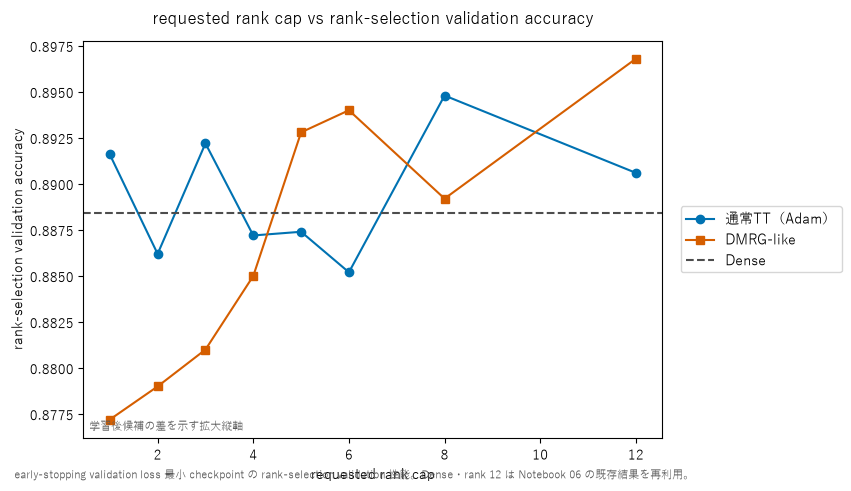

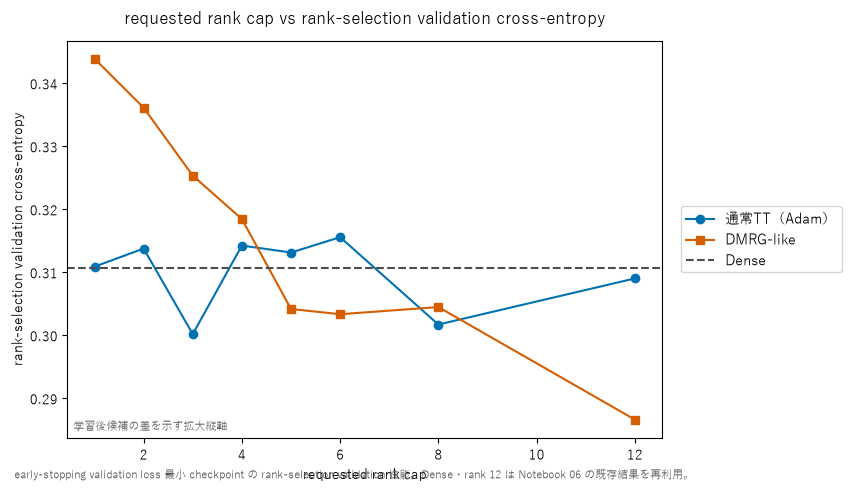

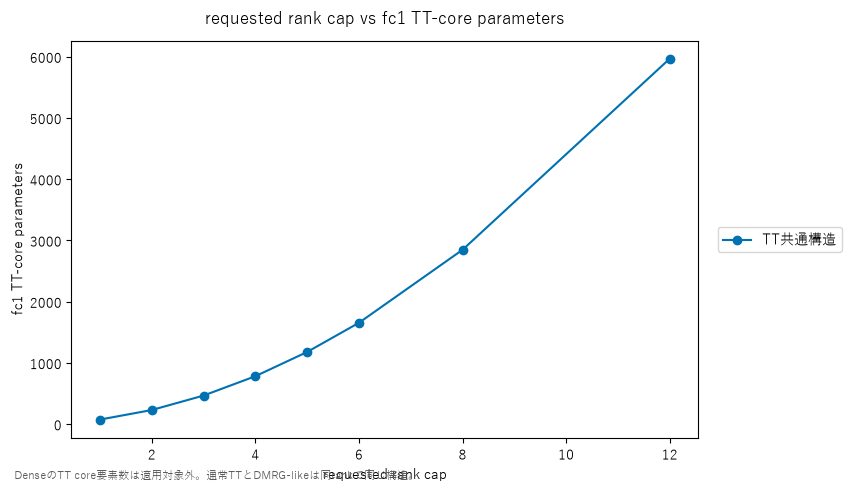

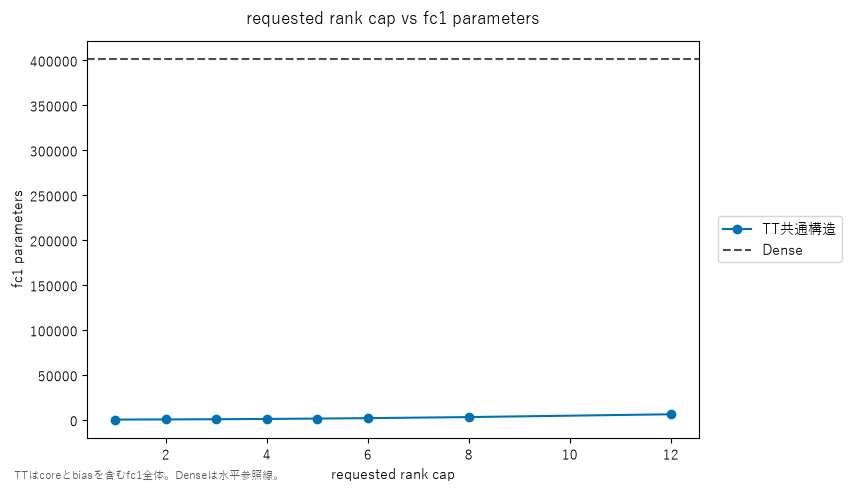

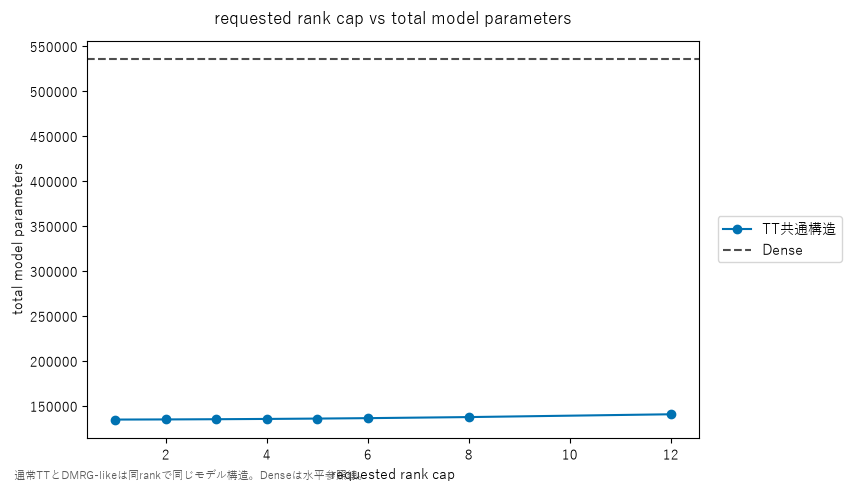

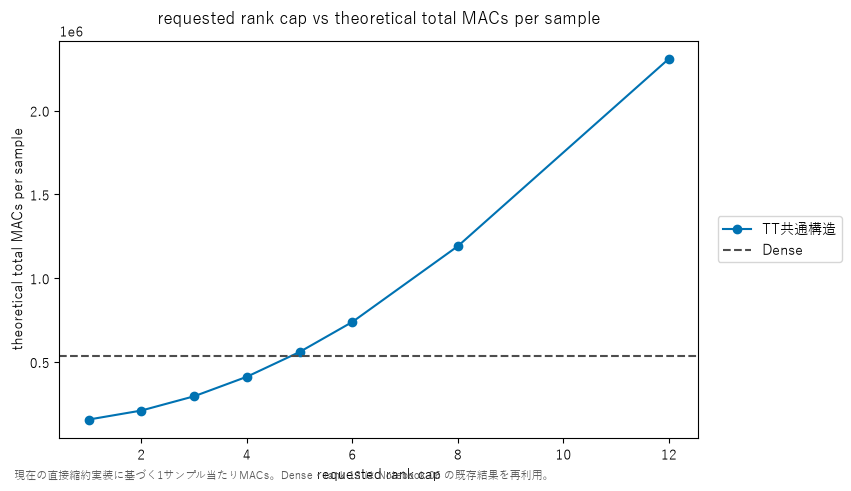

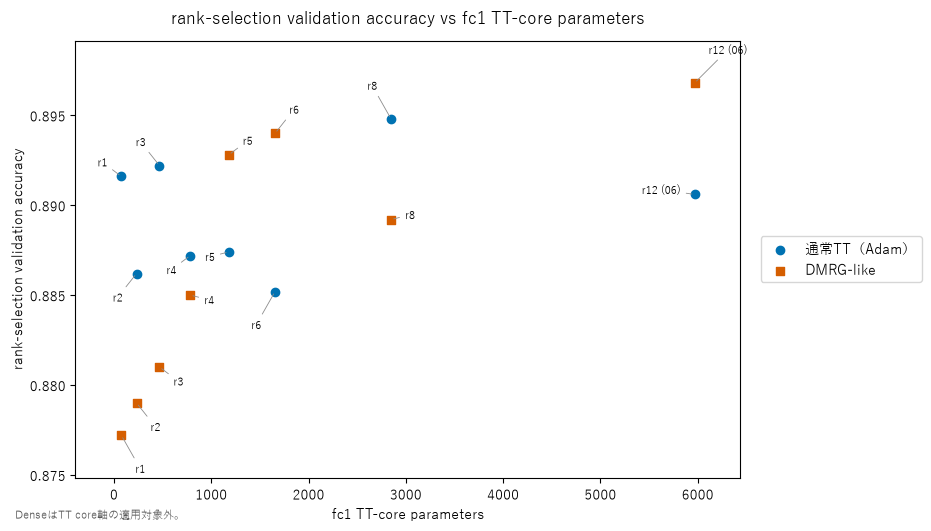

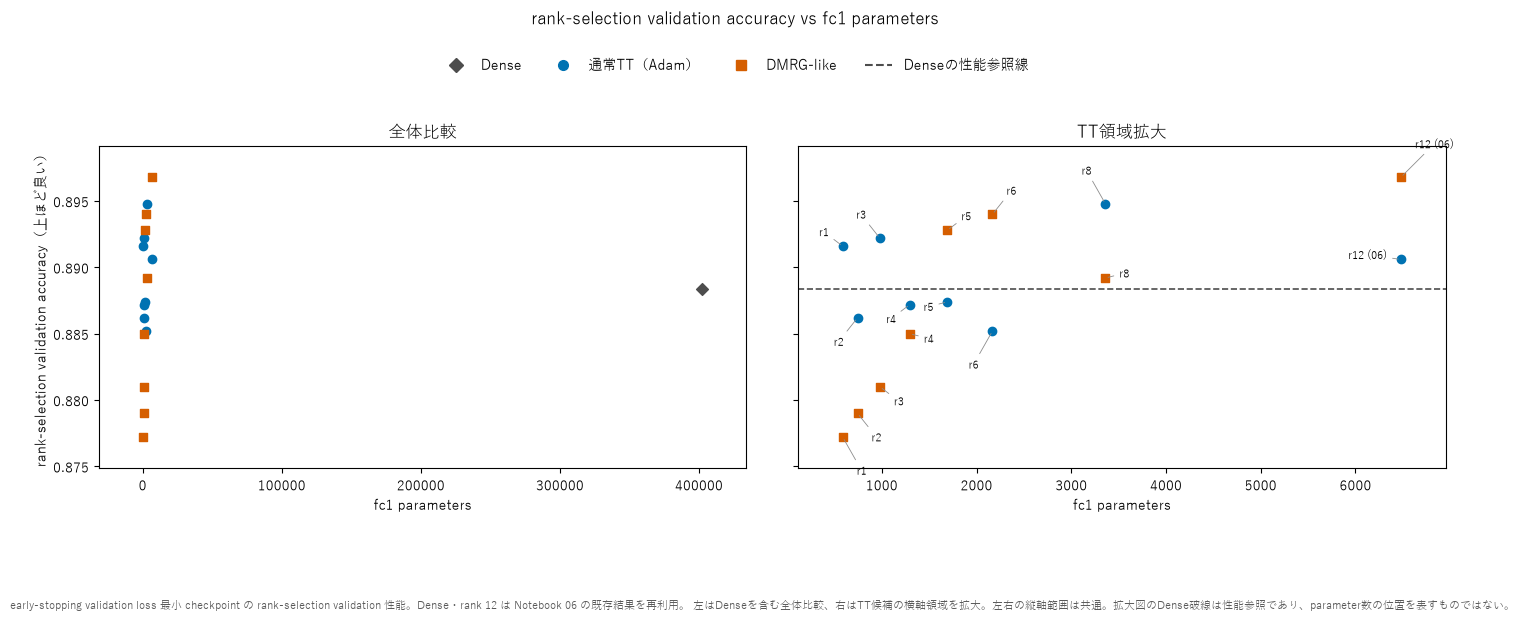

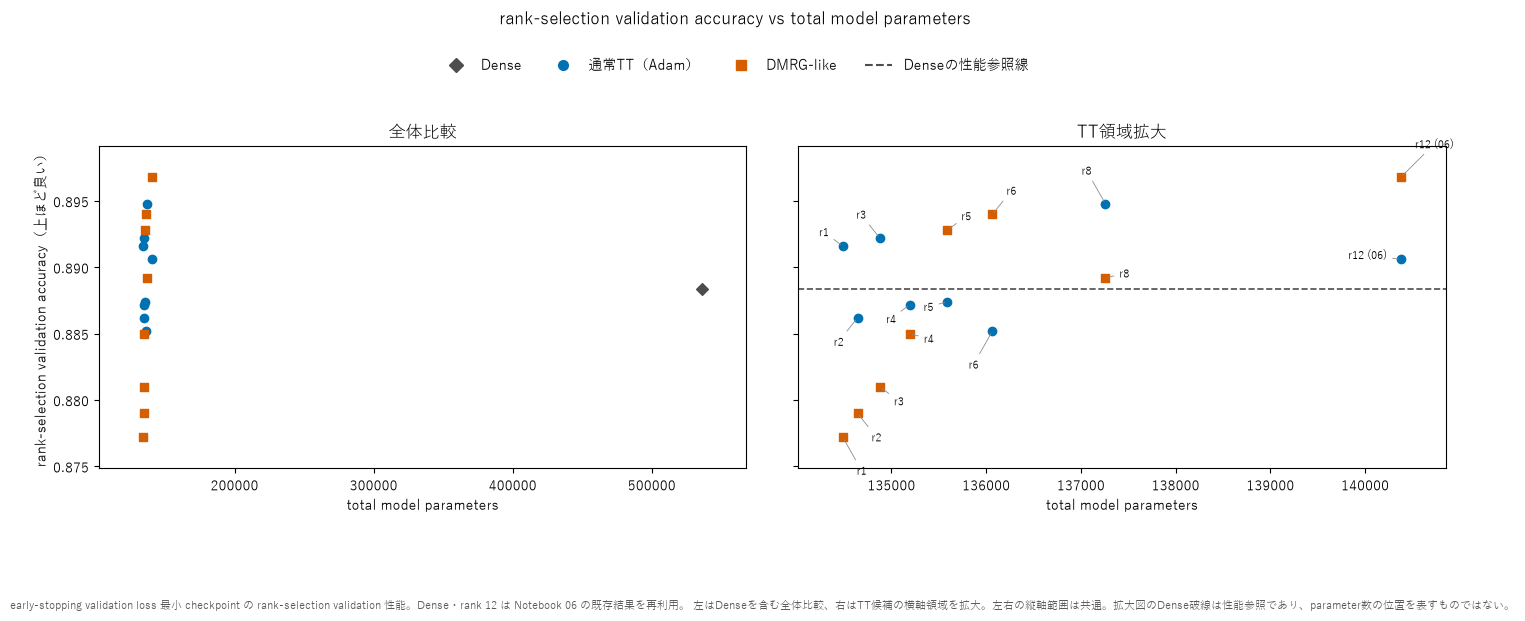

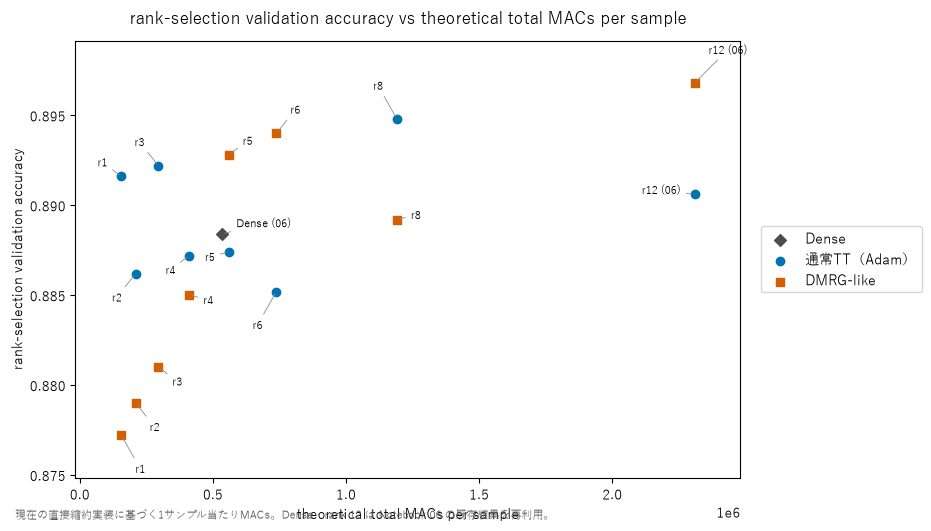

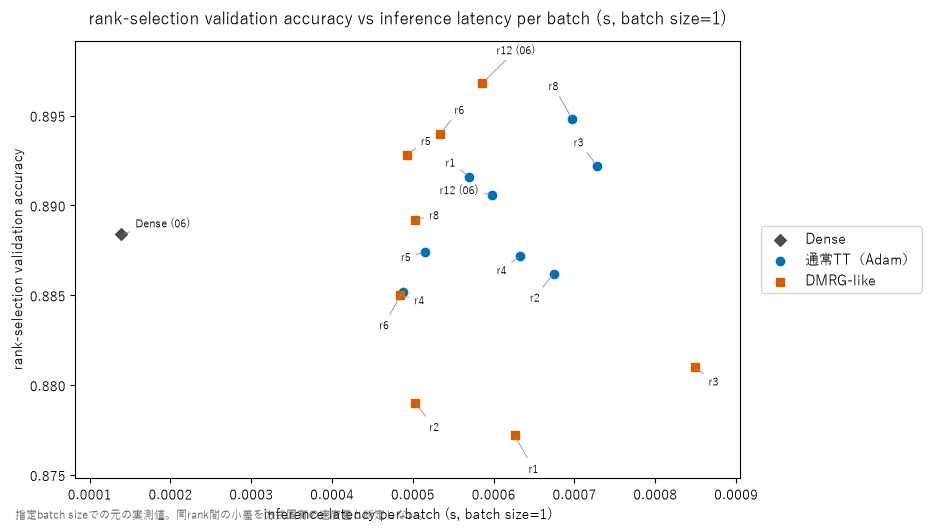

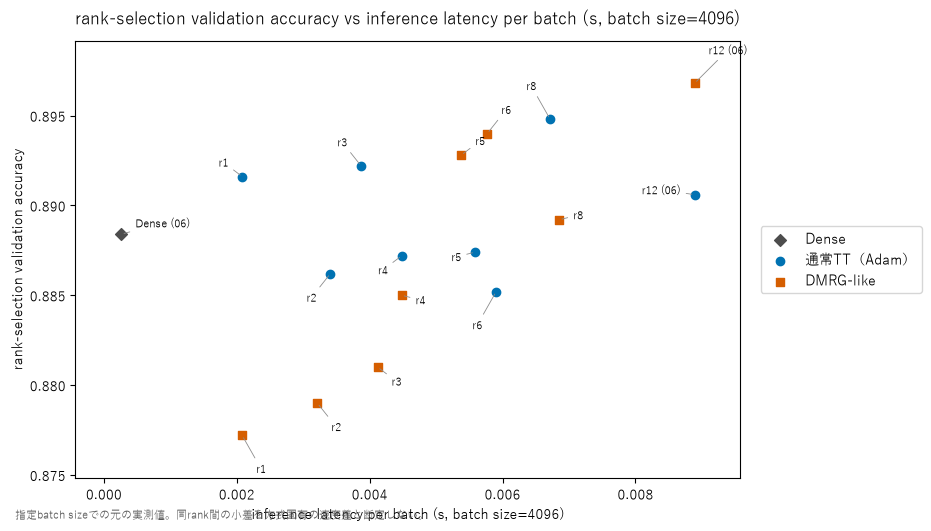

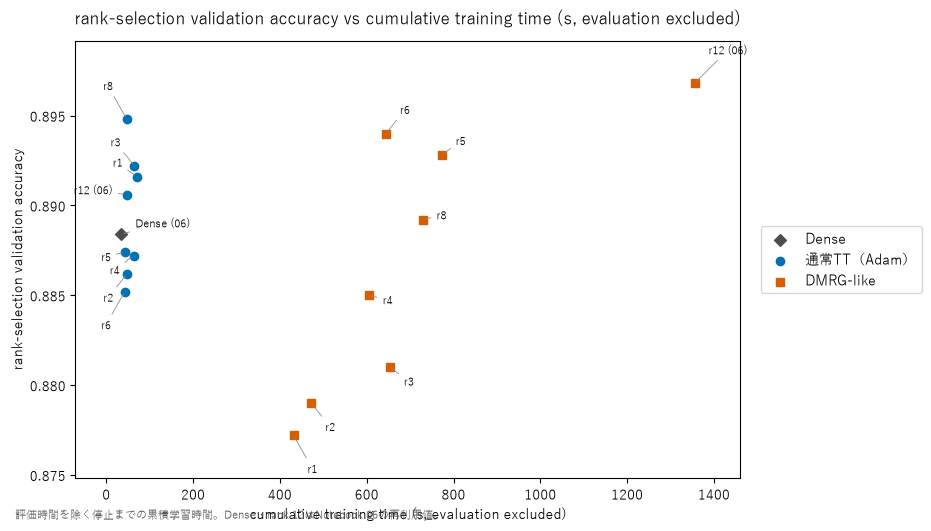

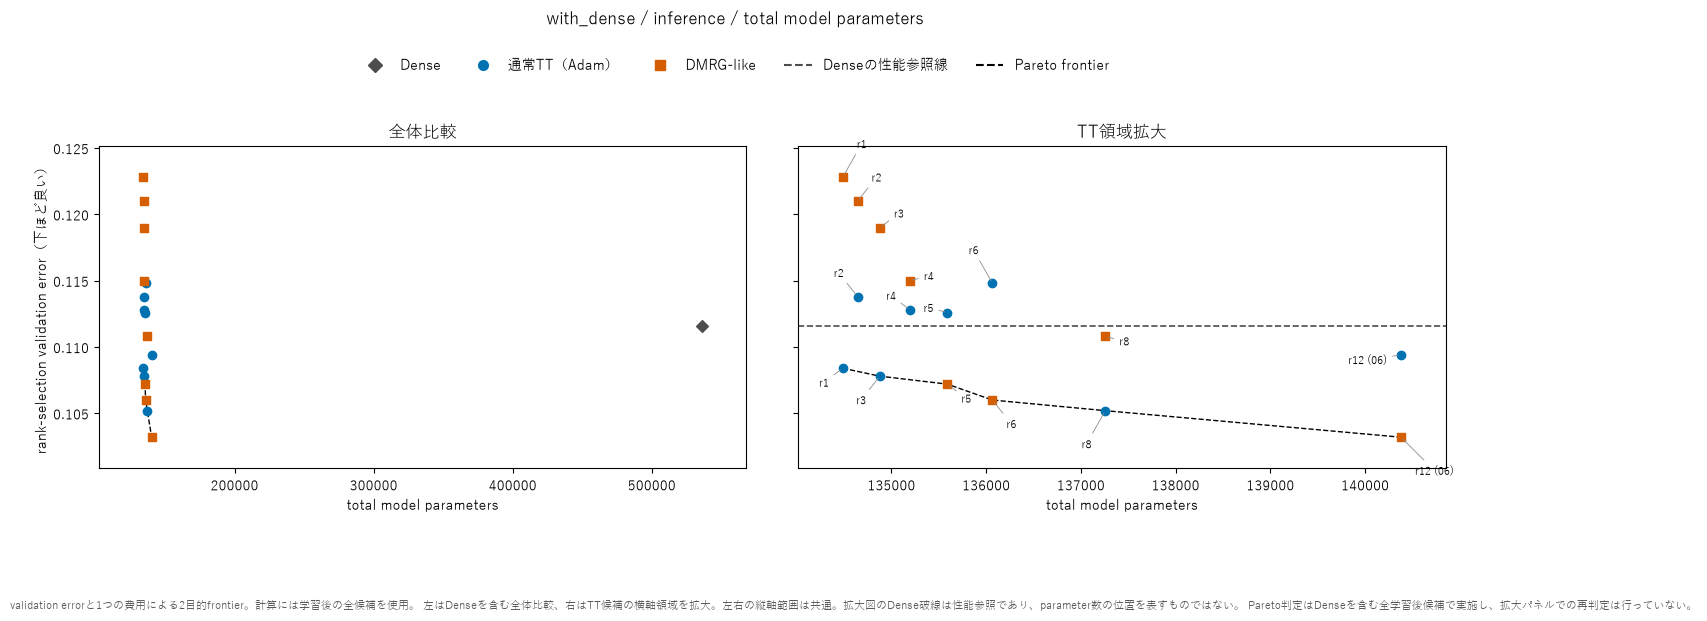

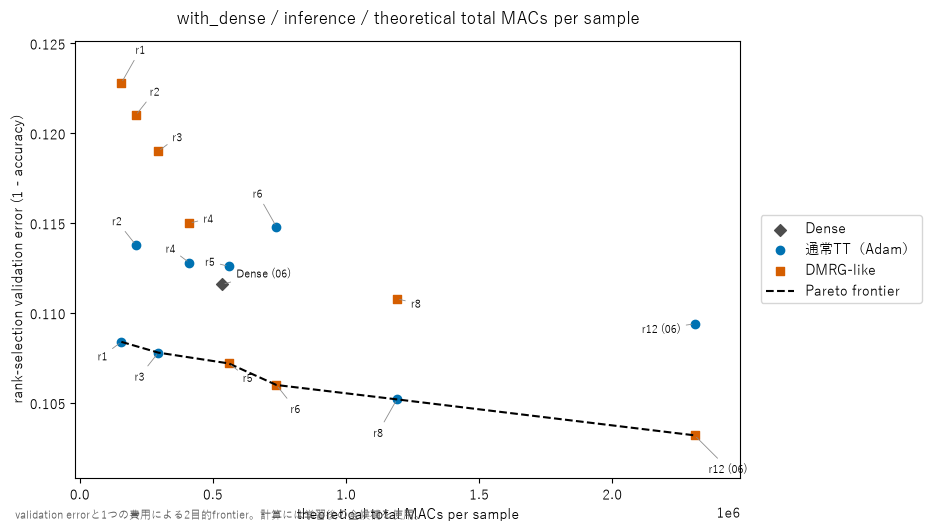

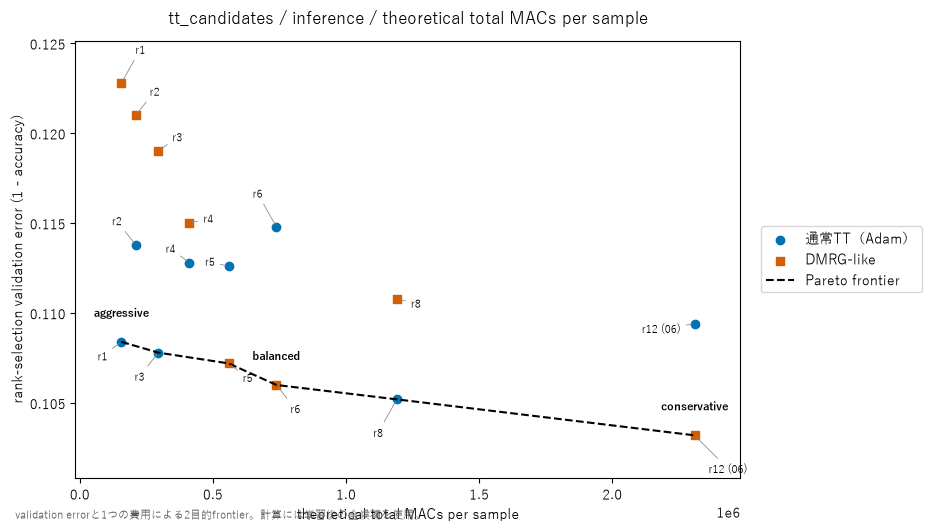

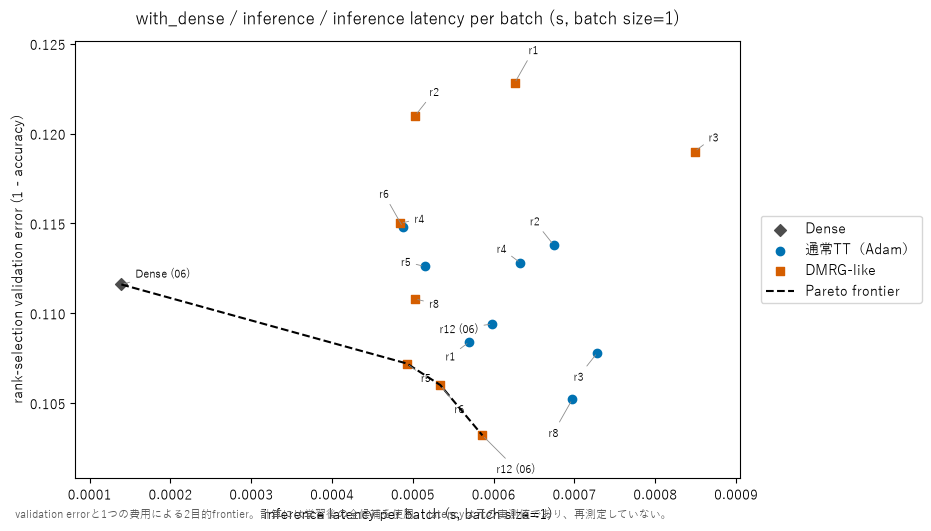

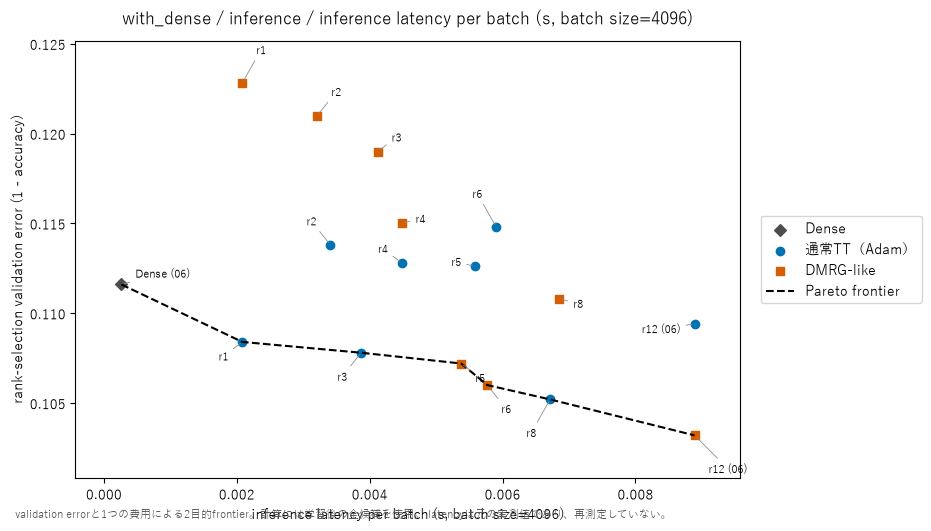

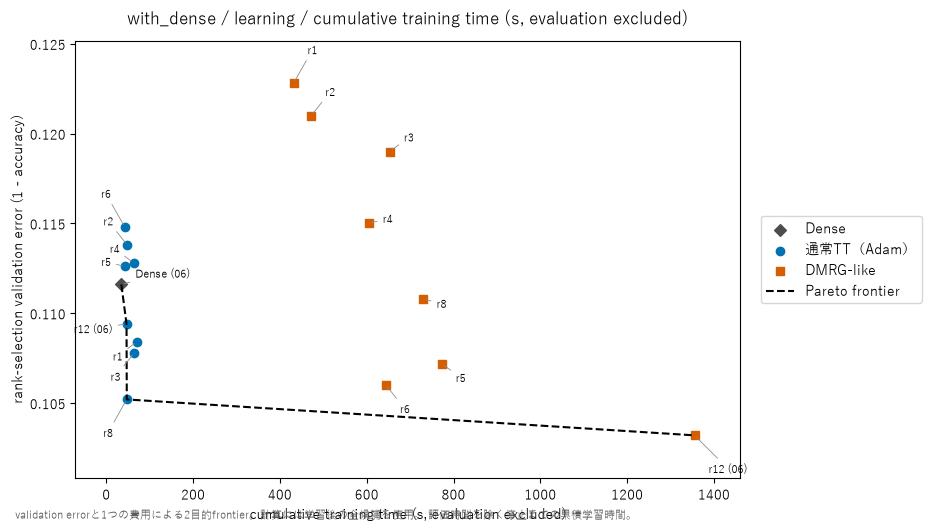

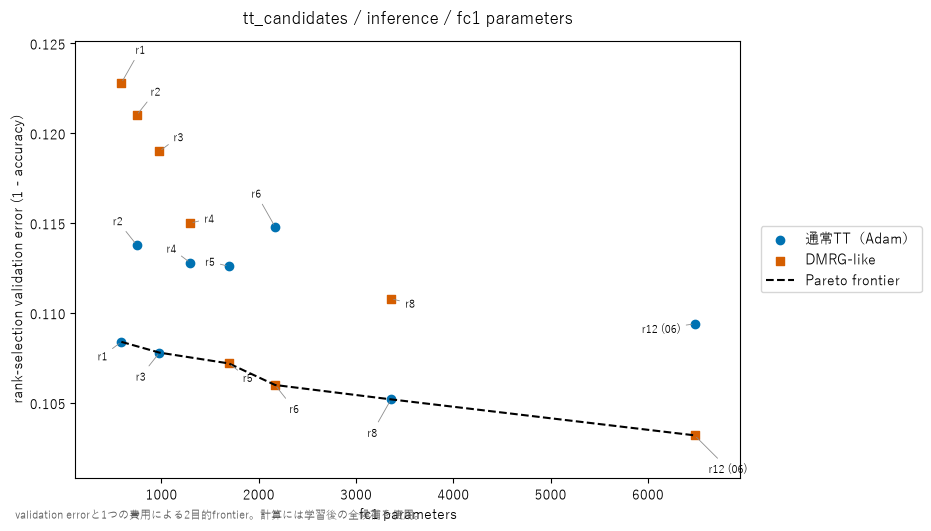

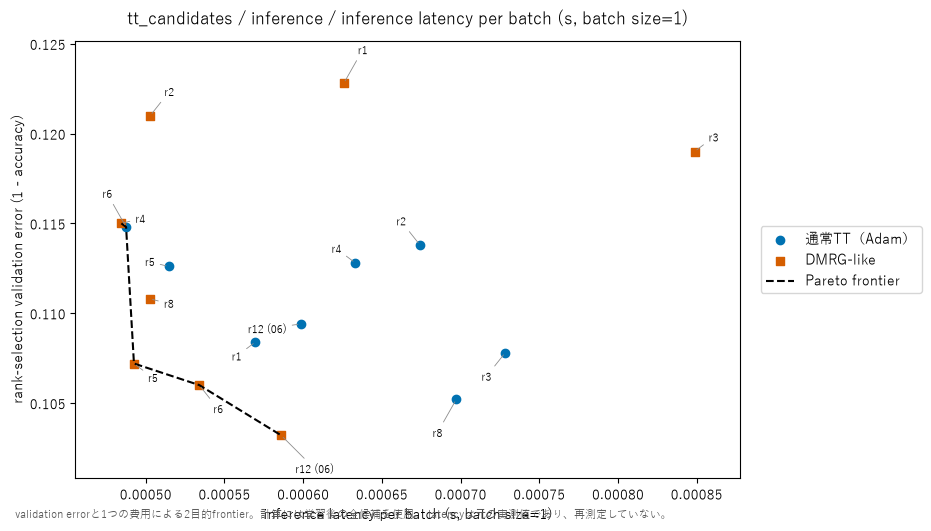

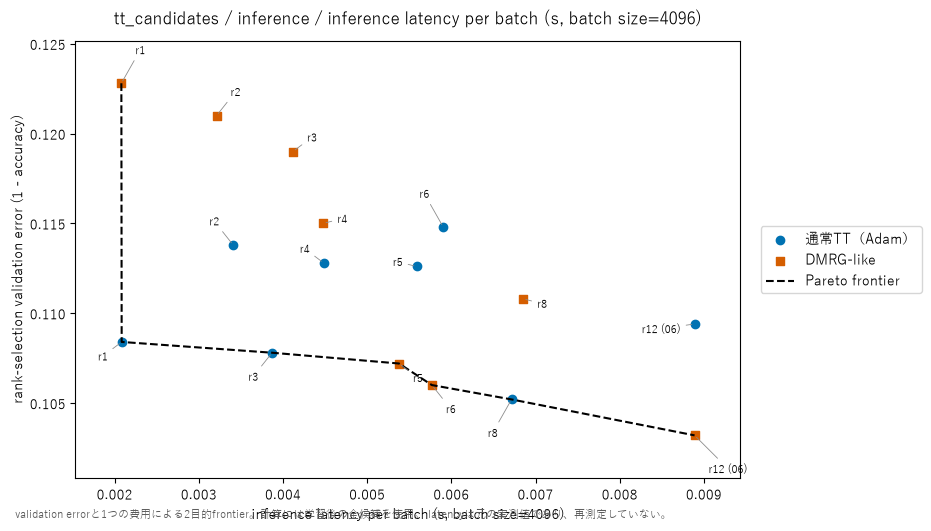

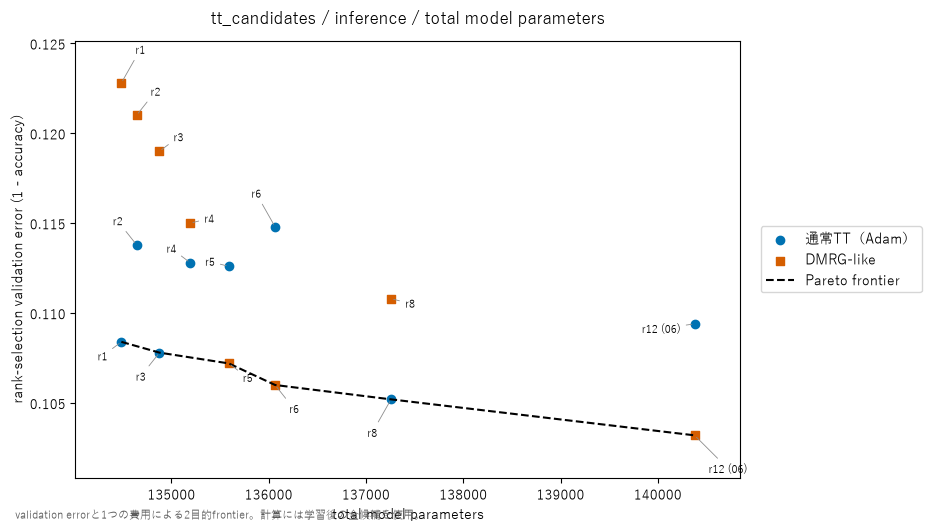

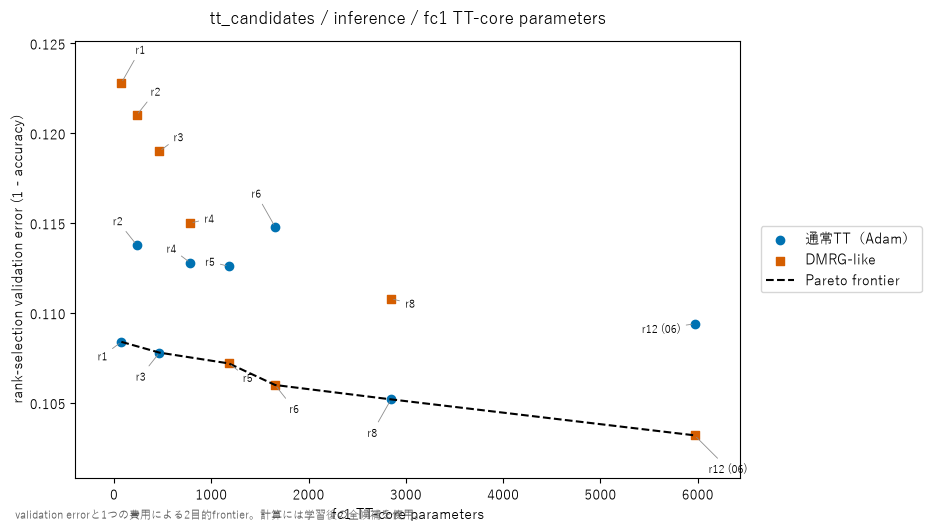

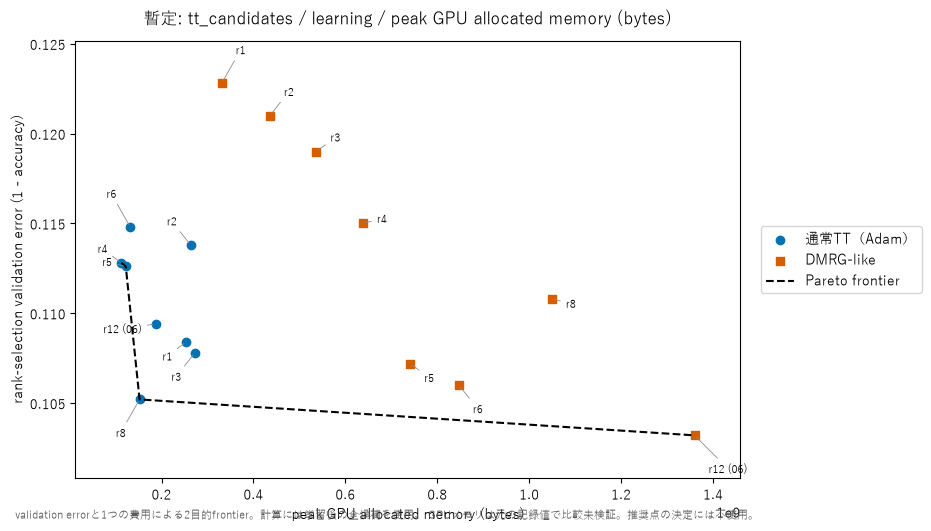

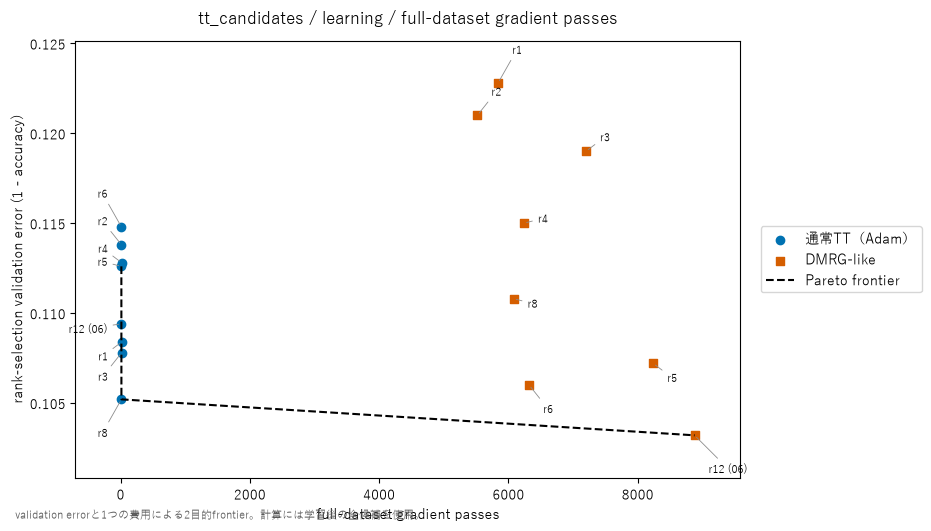

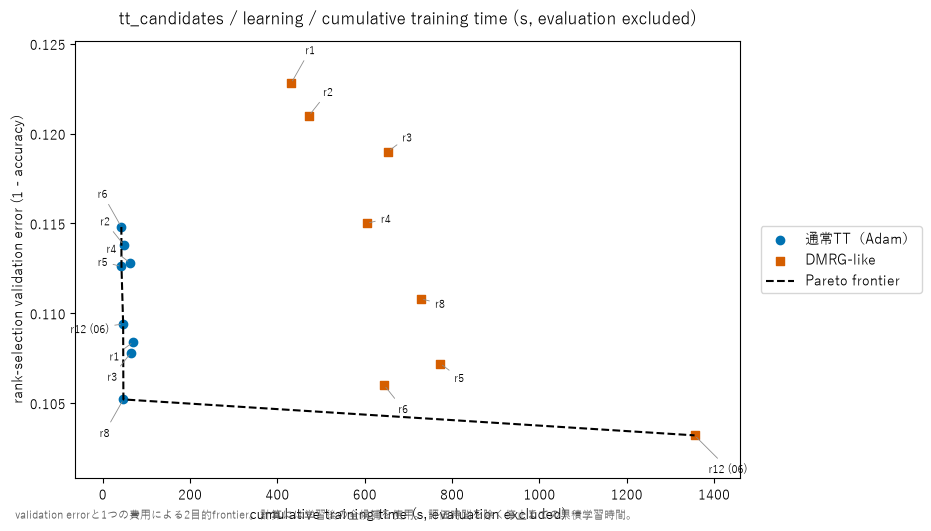

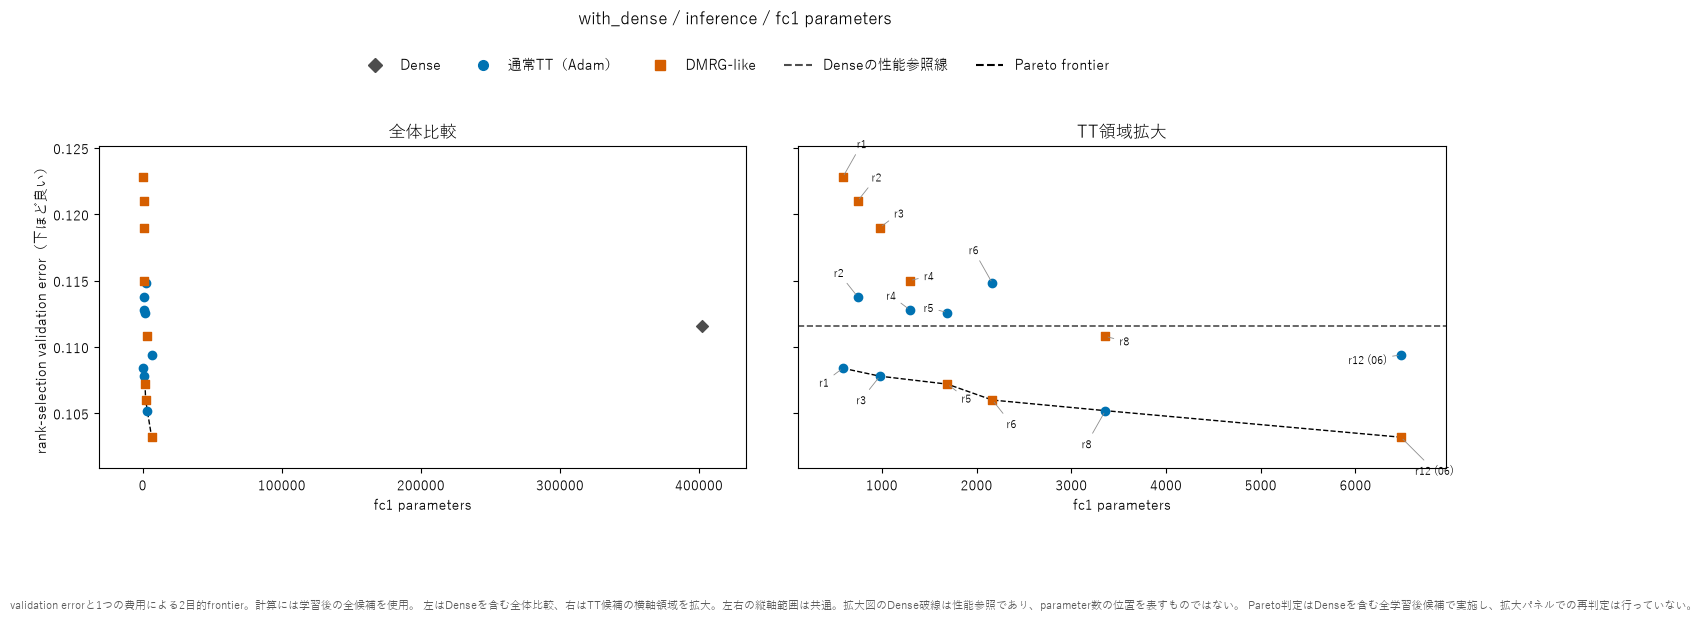

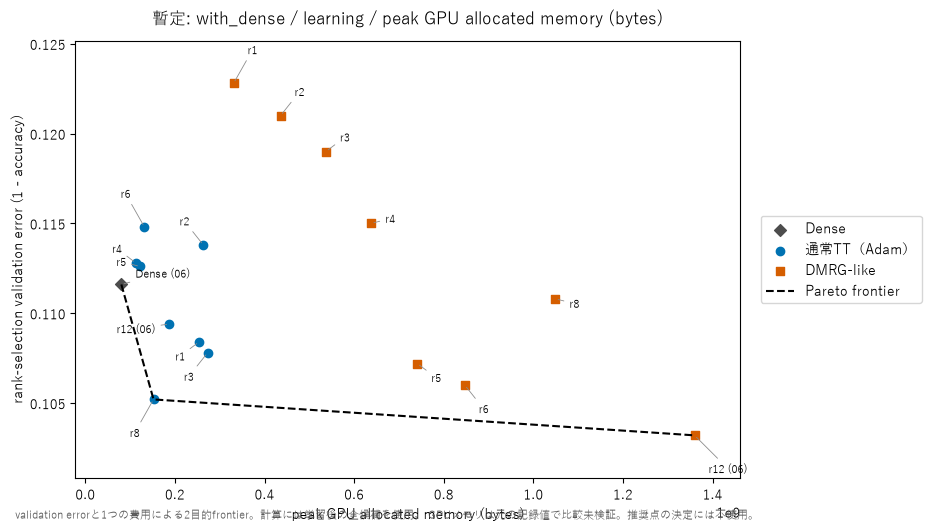

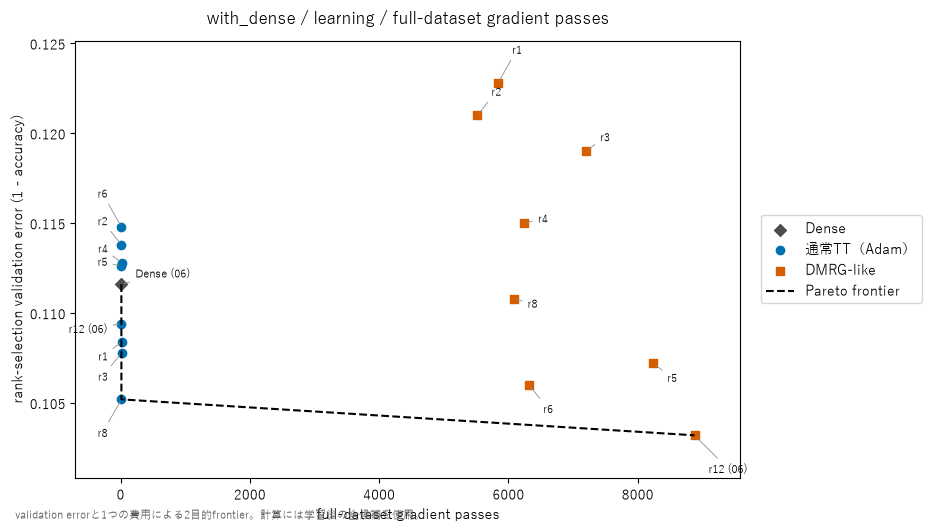

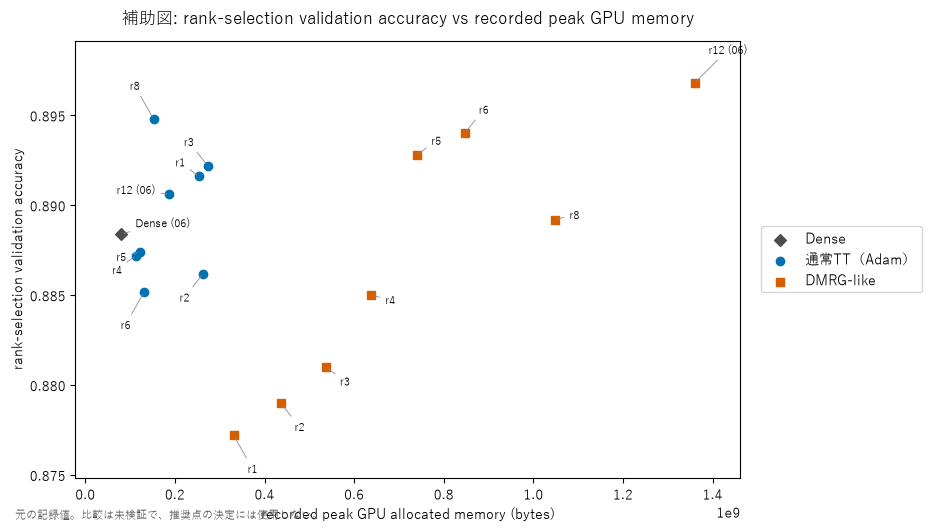

全結果


,requested_rank_cap,state,source,expected_actual_ranks,actual_ranks,tt_core_elements,fc1_parameters,total_model_parameters,early_stopping_validation_loss,early_stopping_validation_accuracy,rank_selection_validation_loss,rank_selection_validation_accuracy,validation_error,loss_improvement_from_initial,accuracy_improvement_from_initial,early_stopping_loss_improvement_from_initial,early_stopping_accuracy_improvement_from_initial,theoretical_fc1_macs,theoretical_total_macs,mac_ratio_vs_dense,latency_batch_1_seconds,latency_batch_4096_seconds,training_time_seconds,evaluation_time_seconds,save_time_seconds,rank_selection_eval_seconds,train_full_dataset_gradient_passes,optimizer_steps,local_updates,best_epoch,best_sweep,stop_reason,peak_gpu_allocated_bytes,initial_eval_peak_gpu_allocated_bytes,peak_memory_scope,fixed_rank_audit,rank_audit_scope,per_update_actual_ranks_recorded,best_checkpoint_sha256,split_index_sha256,notebook_code_sha256,implementation_sha256,verification_code_sha256,training_source_restored,stage_c_sha256,torch_version,gpu_name
0,1.0,initial,07,1|1|1|1|1|1|1,1|1|1|1|1|1|1,76.0,588,134486,2.303715,0.0868,2.303852,0.0812,0.9188,NaN,NaN,NaN,NaN,22400,156032,0.291627,0.000598,0.002115,0.000000,0.342833,0.000000,0.148198,0,0,0,0.0,0.0,initial,NaN,48556544.0,initial_evaluation_after_dedicated_reset,pass,initial_checkpoint,False,b84062df92206292bb33211158f97b6b2d0d9292e8b8ab...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,8516e9e4c730cb02fe7a1f7bc7c00f1240c04516b762ba...,3c8607aa4366dca9c1772c5d5b5ae2a869a805eda8545d...,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
1,2.0,initial,07,1|2|2|2|2|2|1,1|2|2|2|2|2|1,232.0,744,134642,2.303815,0.1222,2.303935,0.1198,0.8802,NaN,NaN,NaN,NaN,76160,209792,0.392105,0.000665,0.003505,0.000000,0.408325,0.000000,0.206856,0,0,0,0.0,0.0,initial,NaN,58190848.0,initial_evaluation_after_dedicated_reset,pass,initial_checkpoint,False,33d604441b1ea1a0ef3d25893d743edf6fd75e919e3b06...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,8516e9e4c730cb02fe7a1f7bc7c00f1240c04516b762ba...,3c8607aa4366dca9c1772c5d5b5ae2a869a805eda8545d...,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
2,3.0,initial,07,1|3|3|3|3|3|1,1|3|3|3|3|3|1,468.0,980,134878,2.304348,0.0664,2.304503,0.0646,0.9354,NaN,NaN,NaN,NaN,161280,294912,0.551196,0.000704,0.004025,0.000000,0.396408,0.000000,0.181976,0,0,0,0.0,0.0,initial,NaN,67825152.0,initial_evaluation_after_dedicated_reset,pass,initial_checkpoint,False,e6522aa36a3a272c585b487859600e8f97683c685bef91...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,8516e9e4c730cb02fe7a1f7bc7c00f1240c04516b762ba...,3c8607aa4366dca9c1772c5d5b5ae2a869a805eda8545d...,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
3,4.0,initial,07,1|4|4|4|4|4|1,1|4|4|4|4|4|1,784.0,1296,135194,2.304024,0.0960,2.304148,0.0994,0.9006,NaN,NaN,NaN,NaN,277760,411392,0.768900,0.000484,0.004475,0.000000,0.416702,0.000000,0.227422,0,0,0,0.0,0.0,initial,NaN,77459968.0,initial_evaluation_after_dedicated_reset,pass,initial_checkpoint,False,ca3d07b80ec9e8b2bcb7bfdfb73e615611d8a7002d698f...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,8516e9e4c730cb02fe7a1f7bc7c00f1240c04516b762ba...,3c8607aa4366dca9c1772c5d5b5ae2a869a805eda8545d...,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
4,5.0,initial,07,1|5|5|5|5|5|1,1|5|5|5|5|5|1,1180.0,1692,135590,2.303349,0.1022,2.303446,0.0964,0.9036,NaN,NaN,NaN,NaN,425600,559232,1.045215,0.000580,0.005479,0.000000,0.344942,0.000000,0.147113,0,0,0,0.0,0.0,initial,NaN,87095296.0,initial_evaluation_after_dedicated_reset,pass,initial_checkpoint,False,30d2cc7379998ec098e9d4ff0a2ddb3c253622988f586f...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,8516e9e4c730cb02fe7a1f7bc7c00f1240c04516b762ba...,3c8607aa4366dca9c1772c5d5b5ae2a869a805eda8545d...,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917a

fine-tuning 前後の改善量


,requested_rank_cap,state,source,stop_reason,loss_improvement_from_initial,accuracy_improvement_from_initial,early_stopping_loss_improvement_from_initial,early_stopping_accuracy_improvement_from_initial
8,1.0,standard_tt,07,early_stopping,1.992978,0.8104,1.985046,0.8004
9,1.0,dmrg_like,07,early_stopping,1.959966,0.7960,1.958182,0.7838
10,2.0,standard_tt,07,early_stopping,1.990183,0.7664,2.001355,0.7696
11,2.0,dmrg_like,07,early_stopping,1.967828,0.7592,1.967065,0.7510
12,3.0,standard_tt,07,early_stopping,2.004339,0.8276,2.003617,0.8214
13,3.0,dmrg_like,07,early_stopping,1.979178,0.8164,1.976925,0.8102
14,4.0,standard_tt,07,early_stopping,1.989921,0.7878,1.997101,0.7904
15,4.0,dmrg_like,07,early_stopping,1.985711,0.7856,1.978448,0.7798
16,5.0,standard_tt,07,early_stopping,1.990324,0.7910,1.990120,0.7784
17,5.0,dmrg_like,07,early_stopping,1.999291,0.7964,2.004290,0.7834


Pareto 判定


,population,frontier_kind,x_column,y_column,status,knee_defined,undefined_reason,aggressive,balanced,conservative,role_reason,completion_reason,point_count,frontier_count
0,tt_candidates,inference,tt_core_elements,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,6
1,tt_candidates,inference,fc1_parameters,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,6
2,tt_candidates,inference,total_model_parameters,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,6
3,tt_candidates,inference,theoretical_total_macs,validation_error,final,True,,rank=1.0|state=standard_tt,rank=6.0|state=dmrg_like,rank=12.0|state=dmrg_like,knee を定義できた。,この軸の学習後候補と測定値は揃っています。,16,6
4,tt_candidates,inference,latency_batch_1_seconds,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,5
5,tt_candidates,inference,latency_batch_4096_seconds,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,7
6,tt_candidates,learning,training_time_seconds,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,5
7,tt_candidates,learning,train_full_dataset_gradient_passes,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,16,3
8,tt_candidates,learning,peak_gpu_allocated_bytes,validation_error,unverified,True,,,,,peak GPU memory は元の記録値であり再計測していない。この軸は未検証で、役割付...,peak GPU memory は元の記録値であり再計測していない。この軸は未検証で、役割付...,16,4
9,with_dense,inference,fc1_parameters,validation_error,final,True,,,,,役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。,この軸の学習後候補と測定値は揃っています。,17,6


... (4 outputs left out)

学習コスト


,requested_rank_cap,state,source,stop_reason,training_time_seconds,evaluation_time_seconds,save_time_seconds,train_full_dataset_gradient_passes,optimizer_steps,local_updates,peak_gpu_allocated_bytes,best_epoch,best_sweep
0,1.0,initial,07,initial,0.000000,0.342833,0.000000,0,0,0,NaN,0.0,0.0
1,2.0,initial,07,initial,0.000000,0.408325,0.000000,0,0,0,NaN,0.0,0.0
2,3.0,initial,07,initial,0.000000,0.396408,0.000000,0,0,0,NaN,0.0,0.0
3,4.0,initial,07,initial,0.000000,0.416702,0.000000,0,0,0,NaN,0.0,0.0
4,5.0,initial,07,initial,0.000000,0.344942,0.000000,0,0,0,NaN,0.0,0.0
5,6.0,initial,07,initial,0.000000,0.346469,0.000000,0,0,0,NaN,0.0,0.0
6,8.0,initial,07,initial,0.000000,0.336840,0.000000,0,0,0,NaN,0.0,0.0
7,12.0,initial,07,initial,0.000000,0.351546,0.000000,0,0,0,NaN,0.0,0.0
8,1.0,standard_tt,07,early_stopping,69.802267,3.875576,0.945044,19,14858,0,2.536847e+08,14.0,NaN
9,1.0,dmrg_like,07,early_stopping,431.425128,11.774137,3.598290,5840,5840,5840,3.309532e+08,NaN,70.0


Notebook 06 からの読み取り専用プレビュー


,requested_rank_cap,state,source,expected_actual_ranks,actual_ranks,tt_core_elements,fc1_parameters,total_model_parameters,early_stopping_validation_loss,early_stopping_validation_accuracy,rank_selection_validation_loss,rank_selection_validation_accuracy,validation_error,loss_improvement_from_initial,accuracy_improvement_from_initial,early_stopping_loss_improvement_from_initial,early_stopping_accuracy_improvement_from_initial,theoretical_fc1_macs,theoretical_total_macs,mac_ratio_vs_dense,latency_batch_1_seconds,latency_batch_4096_seconds,training_time_seconds,evaluation_time_seconds,save_time_seconds,rank_selection_eval_seconds,train_full_dataset_gradient_passes,optimizer_steps,local_updates,best_epoch,best_sweep,stop_reason,peak_gpu_allocated_bytes,initial_eval_peak_gpu_allocated_bytes,peak_memory_scope,fixed_rank_audit,rank_audit_scope,per_update_actual_ranks_recorded,best_checkpoint_sha256,split_index_sha256,notebook_code_sha256,implementation_sha256,verification_code_sha256,training_source_restored,stage_c_sha256,torch_version,gpu_name
0,12.0,standard_tt,notebook06,1|8|12|12|12|12|1,1|8|12|12|12|12|1,5968.0,6480,140378,0.303265,0.8926,0.309005,0.8906,0.1094,NaN,NaN,NaN,NaN,2175488,2309120,4.315789,0.000598,0.008889,46.694169,24.212313,2.731896,NaN,13,10166,0,8.0,NaN,early_stopping,187653120,NaN,notebook06_recorded_training_peak,pass,saved_checkpoints_and_history,False,6493c9baed0ef1be387969dc95cd06cbb9203e64b59660...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,NaN,NaN,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
1,12.0,dmrg_like,notebook06,1|8|12|12|12|12|1,1|8|12|12|12|12|1,5968.0,6480,140378,0.290853,0.8950,0.286605,0.8968,0.1032,NaN,NaN,NaN,NaN,2175488,2309120,4.315789,0.000586,0.008890,1355.376064,312.936606,29.645858,NaN,8880,8880,8880,NaN,106.0,early_stopping,1359745024,NaN,notebook06_recorded_training_peak,pass,retained_rank_plus_checkpoints,False,4356f83dbd1a6f609129a8c8afe8a0fbf3fddc0324a154...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,NaN,NaN,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti
2,NaN,dense_reference,notebook06,NaN,NaN,NaN,401920,535818,0.299885,0.8838,0.310588,0.8884,0.1116,NaN,NaN,NaN,NaN,401408,535040,1.000000,0.000139,0.000262,34.792796,24.422209,3.084134,NaN,12,9384,0,NaN,NaN,early_stopping,80464384,NaN,notebook06_recorded_training_peak,NaN,dense_has_no_tt_rank,False,c9365eeaef594c546af0b9e660590f690984e90e3e9aeb...,aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98...,NaN,NaN,NaN,NaN,ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd50...,2.11.0+cu128,NVIDIA GeForce RTX 5070 Ti


In [11]:
def ensure_display_dependencies():
    setup_names = (
        "project_root",
        "EXPERIMENT_NAME",
        "SMOKE_EXPERIMENT_NAME",
        "RUN_SMOKE",
        "RUN_MAIN_EXPERIMENT",
        "REGENERATE_DISPLAY_ARTIFACTS",
        "Path",
        "pd",
        "display",
        "plt",
        "np",
    )
    helper_names = (
        "numeric_frame",
        "frontier_is_final",
        "plot_rank_lines",
        "plot_rank_structure",
        "plot_scatter",
        "plot_frontier",
        "pareto_for",
        "unique_extreme",
        "METHOD_STYLES",
        "annotate_rank_points",
        "point_rank_label",
        "save_figure",
        "add_figure_note",
    )
    missing_setup = [name for name in setup_names if name not in globals()]
    missing_helpers = [name for name in helper_names if name not in globals()]
    if missing_setup or missing_helpers:
        parts = []
        if missing_setup:
            parts.append("セル1（import / RUN_* / project_root）: " + ", ".join(missing_setup))
        if missing_helpers:
            parts.append("セル4（描画ヘルパー）: " + ", ".join(missing_helpers))
        raise RuntimeError("表示の前提セルが未実行です。先に実行してください。 " + " / ".join(parts))


def resolve_results_dir():
    ensure_display_dependencies()
    if "ACTIVE_RESULTS" in globals() and ACTIVE_RESULTS is not None:
        return Path(ACTIVE_RESULTS)
    smoke = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / SMOKE_EXPERIMENT_NAME / "results_table.csv"
    main = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME / "results_table.csv"
    if RUN_MAIN_EXPERIMENT and main.is_file():
        return main.parent
    if RUN_SMOKE and smoke.is_file():
        return smoke.parent
    if main.is_file():
        return main.parent
    if smoke.is_file():
        return smoke.parent
    return None



DENSE_SPLIT_NOTE = (
    "左はDenseを含む全体比較、右はTT候補の横軸領域を拡大。"
    "左右の縦軸範囲は共通。"
    "拡大図のDense破線は性能参照であり、parameter数の位置を表すものではない。"
)
DENSE_SPLIT_PARETO_NOTE = "Pareto判定はDenseを含む全学習後候補で実施し、拡大パネルでの再判定は行っていない。"
DENSE_SPLIT_SCATTER_COLUMNS = {"fc1_parameters", "total_model_parameters"}
DENSE_SPLIT_FRONTIER_NAMES = {
    "frontier_with_dense_inference_total_model_parameters.png",
    "frontier_with_dense_inference_fc1_parameters.png",
}


def dense_split_limits(values, pad_ratio):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        return None
    low = float(finite.min())
    high = float(finite.max())
    span = high - low
    if span == 0.0:
        pad = abs(low) * 0.05 if low != 0.0 else 1.0
    else:
        pad = span * pad_ratio
    return low - pad, high + pad


def plot_dense_split_comparison(points, x_column, y_column, xlabel, ylabel, path, title, note, selection=None):
    """Denseを含む全体と、TTの横軸領域の拡大を並べる。frontier は引数の判定結果を使う。"""
    from matplotlib.lines import Line2D

    visible = points[points["state"].isin(["dense_reference", "standard_tt", "dmrg_like"])].dropna(subset=[x_column, y_column])
    dense = visible[visible["state"] == "dense_reference"]
    tt = visible[visible["state"].isin(["standard_tt", "dmrg_like"])]
    fig, axes = plt.subplots(1, 2, figsize=(14.8, 6.2), sharey=True)
    fig.subplots_adjust(left=0.07, right=0.98, top=0.76, bottom=0.24, wspace=0.08)
    if visible.empty:
        for axis, panel_title in zip(axes, ("全体比較", "TT領域拡大")):
            axis.set_title(panel_title)
            axis.text(0.5, 0.5, "表示できる点がありません", ha="center", va="center", transform=axis.transAxes)
    else:
        for state_name in ("dense_reference", "standard_tt", "dmrg_like"):
            style = METHOD_STYLES[state_name]
            part = visible[visible["state"] == state_name]
            if part.empty:
                continue
            axes[0].scatter(part[x_column], part[y_column], color=style["color"], marker=style["marker"], s=36, zorder=3)
        for state_name in ("standard_tt", "dmrg_like"):
            style = METHOD_STYLES[state_name]
            part = tt[tt["state"] == state_name]
            if part.empty:
                continue
            axes[1].scatter(part[x_column], part[y_column], color=style["color"], marker=style["marker"], s=36, zorder=3)
            annotate_rank_points(axes[1], part, x_column, y_column, state_name)
        dense_values = []
        for value in dense[y_column].tolist():
            number = float(value)
            if number not in dense_values:
                dense_values.append(number)
        for number in dense_values:
            axes[1].axhline(number, color=METHOD_STYLES["dense_reference"]["color"], linestyle="--", linewidth=1.2, zorder=2)
        frontier = None if selection is None or selection.frontier.empty else selection.frontier.sort_values(x_column)
        if frontier is not None:
            for axis in axes:
                axis.plot(frontier[x_column], frontier[y_column], color="black", linestyle="--", linewidth=1.0, zorder=1)
        y_limits = dense_split_limits(visible[y_column], 0.12)
        overall_x = dense_split_limits(visible[x_column], 0.08)
        tt_x = dense_split_limits(tt[x_column], 0.08)
        if y_limits is not None:
            axes[0].set_ylim(*y_limits)
        if overall_x is not None:
            axes[0].set_xlim(*overall_x)
        if tt_x is not None:
            axes[1].set_xlim(*tt_x)
        elif tt.empty:
            axes[1].text(0.5, 0.5, "TT候補がありません", ha="center", va="center", transform=axes[1].transAxes)
    for axis in axes:
        axis.set_xscale("linear")
    axes[0].set_title("全体比較")
    axes[1].set_title("TT領域拡大")
    axes[0].set_xlabel(xlabel)
    axes[1].set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title, fontsize=12)
    handles = [
        Line2D([0], [0], marker=METHOD_STYLES[state_name]["marker"], color=METHOD_STYLES[state_name]["color"], linestyle="None", markersize=7, label=METHOD_STYLES[state_name]["label"])
        for state_name in ("dense_reference", "standard_tt", "dmrg_like")
    ]
    handles.append(Line2D([0], [0], color=METHOD_STYLES["dense_reference"]["color"], linestyle="--", label="Denseの性能参照線"))
    if selection is not None and not selection.frontier.empty:
        handles.append(Line2D([0], [0], color="black", linestyle="--", label="Pareto frontier"))
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.86), ncol=5, frameon=False)
    add_figure_note(fig, note)
    save_figure(path)


def display_saved_results():
    results_dir = resolve_results_dir()
    if results_dir is None or not (results_dir / "results_table.csv").is_file():
        print("表示できる結果 CSV はまだありません。")
        return
    frame = numeric_frame(results_dir / "results_table.csv")
    training_final, training_reason = frontier_is_final(frame)
    print("results directory:", results_dir)
    print("training completion:", "final" if training_final else "provisional")
    print(training_reason)
    print("frontier は validation error と一つの費用の 2 目的比較であり、全費用を同時に扱う多目的 frontier ではない。")
    figures = results_dir / "figures_revised"
    main_figures = figures / "main"
    auxiliary_figures = figures / "auxiliary"
    if REGENERATE_DISPLAY_ARTIFACTS and figures.exists():
        raise RuntimeError(f"改訂図の保存先が既にあるため、上書きせず停止します: {figures}")
    prefix = "" if training_final else "暫定: "
    performance_note = "early-stopping validation loss 最小 checkpoint の rank-selection validation 性能。Dense・rank 12 は Notebook 06 の既存結果を再利用。"
    mac_note = "現在の直接縮約実装に基づく1サンプル当たりMACs。Dense・rank 12 は Notebook 06 の既存結果を再利用。"
    plot_rank_lines(
        frame,
        "rank_selection_validation_accuracy",
        "rank-selection validation accuracy",
        main_figures / "01_rank_vs_accuracy.png",
        prefix + "requested rank cap vs rank-selection validation accuracy",
        performance_note,
    )
    plot_rank_lines(
        frame,
        "rank_selection_validation_loss",
        "rank-selection validation cross-entropy",
        main_figures / "02_rank_vs_loss.png",
        prefix + "requested rank cap vs rank-selection validation cross-entropy",
        performance_note,
    )
    plot_rank_structure(
        frame,
        "tt_core_elements",
        "fc1 TT-core parameters",
        main_figures / "03_rank_vs_tt_core_elements.png",
        prefix + "requested rank cap vs fc1 TT-core parameters",
        dense_reference=False,
        note="DenseのTT core要素数は適用対象外。通常TTとDMRG-likeは同rankで同じ構造。",
    )
    plot_rank_structure(
        frame,
        "fc1_parameters",
        "fc1 parameters",
        main_figures / "04_rank_vs_fc1_parameters.png",
        prefix + "requested rank cap vs fc1 parameters",
        note="TTはcoreとbiasを含むfc1全体。Denseは水平参照線。",
    )
    plot_rank_structure(
        frame,
        "total_model_parameters",
        "total model parameters",
        main_figures / "05_rank_vs_total_parameters.png",
        prefix + "requested rank cap vs total model parameters",
        note="通常TTとDMRG-likeは同rankで同じモデル構造。Denseは水平参照線。",
    )
    plot_rank_structure(
        frame,
        "theoretical_total_macs",
        "theoretical total MACs per sample",
        main_figures / "06_rank_vs_total_macs.png",
        prefix + "requested rank cap vs theoretical total MACs per sample",
        note=mac_note,
    )
    scatter_specs = (
        ("tt_core_elements", "fc1 TT-core parameters", main_figures / "07_accuracy_vs_tt_core_elements.png", "DenseはTT core軸の適用対象外。"),
        ("fc1_parameters", "fc1 parameters", main_figures / "08_accuracy_vs_fc1_parameters.png", performance_note),
        ("total_model_parameters", "total model parameters", main_figures / "09_accuracy_vs_total_parameters.png", performance_note),
        ("theoretical_total_macs", "theoretical total MACs per sample", main_figures / "10_accuracy_vs_total_macs.png", mac_note),
        ("latency_batch_1_seconds", "inference latency per batch (s, batch size=1)", main_figures / "11_accuracy_vs_latency_batch1.png", "指定batch sizeでの元の実測値。同rank間の小差を方式固有の速度差と断定しない。"),
        ("latency_batch_4096_seconds", "inference latency per batch (s, batch size=4096)", main_figures / "12_accuracy_vs_latency_batch4096.png", "指定batch sizeでの元の実測値。同rank間の小差を方式固有の速度差と断定しない。"),
        ("training_time_seconds", "cumulative training time (s, evaluation excluded)", main_figures / "13_accuracy_vs_training_time.png", "評価時間を除く停止までの累積学習時間。Dense・rank 12はNotebook 06の再利用値。"),
    )
    for column, xlabel, figure_path, note in scatter_specs:
        scatter_title = prefix + "rank-selection validation accuracy vs " + xlabel
        if column in DENSE_SPLIT_SCATTER_COLUMNS:
            plot_dense_split_comparison(
                frame,
                column,
                "rank_selection_validation_accuracy",
                xlabel,
                "rank-selection validation accuracy（上ほど良い）",
                figure_path.with_name(figure_path.stem + "_dense_split" + figure_path.suffix),
                scatter_title,
                note + " " + DENSE_SPLIT_NOTE,
            )
        else:
            plot_scatter(frame, column, xlabel, figure_path, scatter_title, note=note)
    trained = frame[frame["state"].isin(["standard_tt", "dmrg_like"])].copy()
    capped = trained[trained["stop_reason"].isin(["max_epochs", "max_sweeps"])]
    eligible = trained
    inference_axes = (
        ("tt_core_elements", "fc1 TT-core parameters"),
        ("fc1_parameters", "fc1 parameters"),
        ("total_model_parameters", "total model parameters"),
        ("theoretical_total_macs", "theoretical total MACs per sample"),
        ("latency_batch_1_seconds", "inference latency per batch (s, batch size=1)"),
        ("latency_batch_4096_seconds", "inference latency per batch (s, batch size=4096)"),
    )
    learning_axes = (
        ("training_time_seconds", "cumulative training time (s, evaluation excluded)"),
        ("train_full_dataset_gradient_passes", "full-dataset gradient passes"),
        ("peak_gpu_allocated_bytes", "peak GPU allocated memory (bytes)"),
    )
    judgement_rows = []
    frontier_rows = []
    frontier_plot_jobs = []
    populations = (("tt_candidates", eligible),)
    if (frame["state"] == "dense_reference").any():
        with_dense = pd.concat([eligible, frame[frame["state"] == "dense_reference"]], ignore_index=True)
        populations = populations + (("with_dense", with_dense),)
    for population_name, population in populations:
        for kind, axes in (("inference", inference_axes), ("learning", learning_axes)):
            for x_column, xlabel in axes:
                use_population = population
                recorded_population = population_name
                if x_column == "tt_core_elements":
                    if population_name != "tt_candidates":
                        continue
                    use_population = trained
                    recorded_population = "tt_candidates"
                points, selection = pareto_for(use_population, x_column, "validation_error")
                required = trained if x_column == "tt_core_elements" else use_population
                missing = int(required[x_column].isna().sum()) if x_column in required.columns else len(required)
                if x_column == "peak_gpu_allocated_bytes":
                    axis_status, axis_reason = "unverified", "peak GPU memory は元の記録値であり再計測していない。この軸は未検証で、役割付けに使わない。"
                elif not training_final:
                    axis_status, axis_reason = "provisional", training_reason
                elif missing > 0 or len(points) != len(required):
                    axis_status, axis_reason = "provisional", f"{x_column} は欠損を除いた点数だけで最終 frontier にしません。"
                else:
                    axis_status, axis_reason = "final", "この軸の学習後候補と測定値は揃っています。"
                undefined = None if selection is None else selection.undefined_reason
                knee_defined = bool(selection.is_defined) if selection is not None else False
                roles_confirmed = axis_status == "final" and recorded_population == "tt_candidates" and x_column == "theoretical_total_macs" and kind == "inference"
                aggressive = ""
                conservative = ""
                balanced = ""
                role_rows = {}
                role_reason = "役割付けは TT 候補の理論総 MACs 対 validation error だけに行う。"
                if not roles_confirmed:
                    role_reason = axis_reason if axis_status != "final" else role_reason
                elif selection is not None:
                    notes = []
                    aggressive_row, _aggressive_reason = unique_extreme(selection.frontier, x_column, True)
                    conservative_row, _conservative_reason = unique_extreme(selection.frontier, "validation_error", True)
                    if aggressive_row is not None:
                        aggressive = f"rank={aggressive_row['requested_rank_cap']}|state={aggressive_row['state']}"
                        role_rows["aggressive"] = aggressive_row
                    else:
                        notes.append("aggressive は同率のため未確定。")
                    if conservative_row is not None:
                        conservative = f"rank={conservative_row['requested_rank_cap']}|state={conservative_row['state']}"
                        role_rows["conservative"] = conservative_row
                    else:
                        notes.append("conservative は同率のため未確定。")
                    if knee_defined:
                        balanced = f"rank={selection.knee_row['requested_rank_cap']}|state={selection.knee_row['state']}"
                        role_rows["balanced"] = selection.knee_row
                    else:
                        notes.append(f"knee は未定義: {undefined}")
                    role_reason = " ".join(notes) if notes else "knee を定義できた。"
                prefix = "" if axis_status == "final" else "暫定: "
                judgement_rows.append(
                    {
                        "population": recorded_population,
                        "frontier_kind": kind,
                        "x_column": x_column,
                        "y_column": "validation_error",
                        "status": axis_status,
                        "knee_defined": knee_defined,
                        "undefined_reason": "" if undefined is None else undefined,
                        "aggressive": aggressive,
                        "balanced": balanced,
                        "conservative": conservative,
                        "role_reason": role_reason,
                        "completion_reason": axis_reason,
                        "point_count": int(len(points)),
                        "frontier_count": 0 if selection is None else int(len(selection.frontier)),
                    }
                )
                if selection is not None:
                    for _, frontier_row in selection.frontier.iterrows():
                        frontier_rows.append(
                            {
                                "population": population_name,
                                "frontier_kind": kind,
                                "x_column": x_column,
                                "requested_rank_cap": frontier_row["requested_rank_cap"],
                                "state": frontier_row["state"],
                                "source": frontier_row["source"],
                                "x_value": frontier_row[x_column],
                                "validation_error": frontier_row["validation_error"],
                                "status": axis_status,
                            }
                        )
                main_keys = {
                    ("with_dense", "inference", "total_model_parameters"),
                    ("with_dense", "inference", "theoretical_total_macs"),
                    ("tt_candidates", "inference", "theoretical_total_macs"),
                    ("with_dense", "inference", "latency_batch_1_seconds"),
                    ("with_dense", "inference", "latency_batch_4096_seconds"),
                    ("with_dense", "learning", "training_time_seconds"),
                }
                main_priority = {
                    ("with_dense", "inference", "total_model_parameters"): 1,
                    ("with_dense", "inference", "theoretical_total_macs"): 2,
                    ("tt_candidates", "inference", "theoretical_total_macs"): 3,
                    ("with_dense", "inference", "latency_batch_1_seconds"): 4,
                    ("with_dense", "inference", "latency_batch_4096_seconds"): 5,
                    ("with_dense", "learning", "training_time_seconds"): 6,
                }
                plot_key = (population_name, kind, x_column)
                figure_group = "main" if plot_key in main_keys else "auxiliary"
                frontier_note = "validation errorと1つの費用による2目的frontier。計算には学習後の全候補を使用。"
                if x_column == "peak_gpu_allocated_bytes":
                    frontier_note += " GPUメモリは元の記録値で比較未検証。推奨点の決定には不使用。"
                elif x_column.startswith("latency_"):
                    frontier_note += " latencyは元の実測値であり、再測定していない。"
                elif x_column == "training_time_seconds":
                    frontier_note += " 評価時間を除く停止までの累積学習時間。"
                frontier_plot_jobs.append(
                    {
                        "is_main": figure_group == "main",
                        "priority": main_priority.get(plot_key, 100),
                        "points": points,
                        "selection": selection,
                        "x_column": x_column,
                        "xlabel": xlabel,
                        "path": (main_figures if figure_group == "main" else auxiliary_figures) / f"frontier_{population_name}_{kind}_{x_column}.png",
                        "title": prefix + f"{recorded_population} / {kind} / {xlabel}",
                        "note": frontier_note,
                        "role_rows": role_rows,
                    }
                )
    # 主Paretoを先に、補助Paretoを後に表示する。計算対象と判定規則は変えない。
    for job in sorted(frontier_plot_jobs, key=lambda item: (not item["is_main"], item["priority"], item["path"].name)):
        if job["path"].name in DENSE_SPLIT_FRONTIER_NAMES:
            plot_dense_split_comparison(
                job["points"],
                job["x_column"],
                "validation_error",
                job["xlabel"],
                "rank-selection validation error（下ほど良い）",
                job["path"].with_name(job["path"].stem + "_dense_split" + job["path"].suffix),
                job["title"],
                job["note"] + " " + DENSE_SPLIT_NOTE + " " + DENSE_SPLIT_PARETO_NOTE,
                selection=job["selection"],
            )
        else:
            plot_frontier(job["points"], job["selection"], job["x_column"], job["xlabel"], job["path"], job["title"], note=job["note"], role_rows=job["role_rows"])
    plot_scatter(
        frame,
        "peak_gpu_allocated_bytes",
        "recorded peak GPU allocated memory (bytes)",
        auxiliary_figures / "accuracy_vs_peak_memory_unverified.png",
        "補助図: rank-selection validation accuracy vs recorded peak GPU memory",
        note="元の記録値。比較は未検証で、推奨点の決定には使用しない。",
    )
    judgement = pd.DataFrame(judgement_rows)
    frontiers = pd.DataFrame(frontier_rows)
    frontier_status = {
        "training_status": "final" if training_final else "provisional",
        "training_reason": training_reason,
        "capped_rows": int(len(capped)),
        "note": "各 frontier は validation error と一つの費用の 2 目的 frontier であり、全費用を同時に扱う多目的 frontier ではない。",
        "frontiers": judgement.to_dict("records"),
    }
    # 既存のPareto CSV・JSONは上書きしない。表示用計算はNotebook内だけで行う。
    improvements = frame[frame["state"].isin(["standard_tt", "dmrg_like"])][
        [
            "requested_rank_cap",
            "state",
            "source",
            "stop_reason",
            "loss_improvement_from_initial",
            "accuracy_improvement_from_initial",
            "early_stopping_loss_improvement_from_initial",
            "early_stopping_accuracy_improvement_from_initial",
        ]
    ]
    rank_costs = frame[
        [
            "requested_rank_cap",
            "state",
            "source",
            "tt_core_elements",
            "fc1_parameters",
            "total_model_parameters",
            "theoretical_fc1_macs",
            "theoretical_total_macs",
            "mac_ratio_vs_dense",
            "latency_batch_1_seconds",
            "latency_batch_4096_seconds",
        ]
    ]
    learning_costs = frame[
        [
            "requested_rank_cap",
            "state",
            "source",
            "stop_reason",
            "training_time_seconds",
            "evaluation_time_seconds",
            "save_time_seconds",
            "train_full_dataset_gradient_passes",
            "optimizer_steps",
            "local_updates",
            "peak_gpu_allocated_bytes",
            "best_epoch",
            "best_sweep",
        ]
    ]
    # 改訂図を保存する場合も、既存の結果CSVは上書きしない。
    with pd.option_context("display.max_columns", None, "display.max_rows", None, "display.width", None):
        print("全結果")
        display(frame)
        print("fine-tuning 前後の改善量")
        display(improvements)
        print("Pareto 判定")
        display(judgement)
        print("frontier 上の候補")
        display(frontiers)
        print("parameter・MACs・latency")
        display(rank_costs)
        print("学習コスト")
        display(learning_costs)
        preview = results_dir / "notebook06_reuse_preview.csv"
        if preview.is_file():
            print("Notebook 06 からの読み取り専用プレビュー")
            display(pd.read_csv(preview, dtype={"source": str}))


display_saved_results()
